# Observation proposal: COSMOS field planning

This notebook retains the initial SDSS/FINALCAT comparison and records subsequent observing-field planning, figures, and executed results.

> Executed branch snapshot: aperture flags unrestricted; original boundary masks and remaining selection criteria retained. Existing SE++ measurements are reused.


## Initial investigation: 7DT + SDSS galaxies without FINALCAT matches

COSMOS1–4 field master catalogs. Selection: `has_7dt & has_sdss & ~has_finalcat & (sdss_type == 3)`. No magnitude or redshift cut is applied. Accepted ambiguous SDSS matches are included, with counts reported separately.

Coordinates use the 7DT master positions (`master_ra`, `master_dec`). Overlap sources are retained per field because FINALCAT association is a field-level outcome; the total is a count of field records, with distinct SDSS IDs also reported. The background and layout follow the FINALCAT RoI spatial coverage plot in notebook 2.2.

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, vstack
from IPython.display import display

# Support execution from the project root or the Notebooks directory.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'COSMOS_data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / 'COSMOS_data'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'singlephot' / 'analysis' / 'test_sdss_galaxies_without_finalcat'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_PATH = OUTPUT_DIR / 'cosmos1-4_7dt_sdss_galaxies_without_finalcat_spatial.png'


In [3]:
selected_fields = []
summary_rows = []
for field in (1, 2, 3, 4):
    master_path = PROJECT_ROOT / 'output' / f'COSMOS{field}' / 'singlephot' / f'cosmos{field}_master_catalog.fits'
    master = Table.read(master_path)
    # These flags record accepted catalog associations, not magnitude availability.
    has_7dt = np.ma.filled(master['has_7dt'], False).astype(bool)
    has_sdss = np.ma.filled(master['has_sdss'], False).astype(bool)
    has_finalcat = np.ma.filled(master['has_finalcat'], False).astype(bool)
    # SDSS photometric type 3 denotes galaxies, following the production notebook.
    galaxy = np.ma.filled(master['sdss_type'], -1).astype(int) == 3
    selected = has_7dt & has_sdss & ~has_finalcat & galaxy
    subset = master[selected][['master_id', 'master_ra', 'master_dec', 'sdss_objid', 'sdss_type', 'sdss_match_status']].copy()
    # Master IDs are local to each field, so preserve the field alongside each ID.
    subset['cosmos_field'] = np.full(len(subset), field, dtype=int)
    ra = np.ma.filled(subset['master_ra'], np.nan).astype(float)
    dec = np.ma.filled(subset['master_dec'], np.nan).astype(float)
    finite = np.isfinite(ra) & np.isfinite(dec)
    status = np.asarray(subset['sdss_match_status']).astype(str)
    summary_rows.append((field, int(selected.sum()), int(finite.sum()),
                         int(np.sum(status == 'matched_unique')),
                         int(np.sum(status == 'matched_ambiguous'))))
    selected_fields.append(subset)

summary = Table(rows=summary_rows, names=['COSMOS', 'N_selected', 'N_plotted', 'N_matched_unique', 'N_matched_ambiguous'])
selected_sources = vstack(selected_fields, metadata_conflicts='silent')
# No cross-field deduplication: each row describes that field's FINALCAT non-match.
# A source in an overlap can have different association outcomes in different fields.
unique_sdss_ids = np.unique(np.asarray(selected_sources['sdss_objid']).astype(str))
display(summary)
print(f'Total selected field records: {len(selected_sources):,}')
print(f'Distinct SDSS object IDs among selected records: {len(unique_sdss_ids):,}')
print('Selection: has_7dt & has_sdss & ~has_finalcat & (sdss_type == 3)')
print('No magnitude or redshift cut; accepted ambiguous SDSS matches are included.')
selected_sources.write(OUTPUT_DIR / 'selected_source_positions.csv', format='ascii.csv', overwrite=True)
summary.write(OUTPUT_DIR / 'counts_by_field.csv', format='ascii.csv', overwrite=True)
display(selected_sources[:10])


COSMOS,N_selected,N_plotted,N_matched_unique,N_matched_ambiguous
int64,int64,int64,int64,int64
1,1654,1654,954,700
2,1721,1721,1000,721
3,791,791,542,249
4,1358,1358,773,585


Total selected field records: 5,524
Distinct SDSS object IDs among selected records: 4,965
Selection: has_7dt & has_sdss & ~has_finalcat & (sdss_type == 3)
No magnitude or redshift cut; accepted ambiguous SDSS matches are included.


master_id,master_ra,master_dec,sdss_objid,sdss_type,sdss_match_status,cosmos_field
int64,float64,float64,int64,int64,bytes19,int64
15,149.98498806193845,1.5583417262629768,1237651735743823933,3,matched_ambiguous,1
54,150.11496764582583,1.5654060726058572,1237651735743889743,3,matched_unique,1
56,149.77939118138443,1.56634385304399,1237653664184991842,3,matched_ambiguous,1
83,150.07803219606606,1.5719816125665826,1237651735743889838,3,matched_ambiguous,1
118,149.41074671856805,1.57989554637199,1237653664184860768,3,matched_ambiguous,1
143,149.40093508929223,1.5854189650618942,1237653664184860825,3,matched_ambiguous,1
164,150.22400330763557,1.5886369229642159,1237651735743955061,3,matched_unique,1
171,149.93370941254025,1.5898369054878028,1237653664185057474,3,matched_unique,1
284,150.21923523161016,1.6121788766949552,1237651735743955312,3,matched_ambiguous,1


## COSMOS1–4 detection-image mosaic

Reuse the 16 × 16 mean pooling, zero-padding transparency, WCS extents, and shared ZScale normalization from notebook 2.2.

In [4]:
# FINALCAT spatial coverage on the COSMOS1-4 mosaic (RA/Dec).
# Scope: visualization only, no recovery analysis in this step.
# - Background axes are RA/Dec; global limits come from the measured WCS
#   corners of the four detection images (plus a small padding).
# - Each detection image is shown with 16x16 mean pooling (chunk-wise,
#   NaN-aware) to avoid dropping point sources by subsampling.
# - WCS direction is preserved per image (dRA/dx < 0, dDec/dy > 0):
#   imshow extent = [ra_max_used, ra_min_used, dec_min_used, dec_max_used].
# - Trimming: 10200 = 16*637 + 8, so the last 8 columns are excluded and the
#   extent below is computed from the actually used pixels [1:10192]x[1:6800].
# - Detection frames are zero-padded outside the valid coadd area; pooled
#   pixels exactly equal to 0 are masked transparent so a top image's padding
#   never hides another image's valid data.
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import ImageNormalize, ZScaleInterval
from astropy.wcs import WCS

POOL = 16
PAD_DEG = 0.02
CHUNK_POOLED_ROWS = 64  # 64*16 = 1024 original rows per chunk

# Project paths are initialized in the preceding cell.
# Background rendering is reused from notebook 2.2 without its catalog selection.


def chunk_pooled_mean(image_path, factor=POOL, chunk_pooled_rows=CHUNK_POOLED_ROWS):
    """16x16 mean pooling without a full-frame float64 temp array.

    Reads one row-chunk at a time (memmap, float32 copy of the chunk only)
    and applies NaN-aware mean per block. Full-frame
    ``block_reduce(np.nanmean)`` would materialize a ~69M-pixel float64
    intermediate; chunking keeps peak memory to ~40 MB.
    """
    data = fits.getdata(image_path, memmap=True)
    ny, nx = data.shape
    nx_used = (nx // factor) * factor
    ny_used = (ny // factor) * factor
    nx_p, ny_p = nx_used // factor, ny_used // factor
    pooled = np.empty((ny_p, nx_p), dtype=np.float32)
    chunk_h = chunk_pooled_rows * factor
    for y0 in range(0, ny_used, chunk_h):
        y1 = min(y0 + chunk_h, ny_used)
        npy = (y1 - y0) // factor
        chunk = np.asarray(data[y0:y0 + npy * factor, :nx_used], dtype=np.float32)
        block = chunk.reshape(npy, factor, nx_p, factor)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=RuntimeWarning)
            pooled[y0 // factor:y0 // factor + npy, :] = np.nanmean(block, axis=(1, 3))
    del data
    return pooled, nx_used, ny_used


# ---- Footprints from measured WCS corners (used-pixel region) ----
footprints = {}
all_ra, all_dec = [], []
for i in (1, 2, 3, 4):
    det_path = DATA_ROOT / f'COSMOS{i}' / f'COSMOS{i}_detectionimage.fits'
    hdr = fits.getheader(det_path)
    w = WCS(hdr)
    nx, ny = int(hdr['NAXIS1']), int(hdr['NAXIS2'])
    pooled, nx_used, ny_used = chunk_pooled_mean(det_path)
    # Used-pixel corners, FITS 1-based: x in [1, nx_used], y in [1, ny_used].
    xs = np.array([1, nx_used, 1, nx_used], dtype=float)
    ys = np.array([1, 1, ny_used, ny_used], dtype=float)
    ra_c, dec_c = w.all_pix2world(xs, ys, 1)
    # dRA/dx < 0: x=1 edge holds RA max; dDec/dy > 0: y=1 holds Dec min.
    ra_max_used = float(ra_c[xs == 1].max())
    ra_min_used = float(ra_c[xs == nx_used].min())
    dec_min_used = float(dec_c.min())
    dec_max_used = float(dec_c.max())
    assert ra_max_used > ra_min_used and dec_max_used > dec_min_used
    masked = np.ma.masked_equal(pooled, 0.0)  # zero padding -> transparent
    footprints[i] = dict(path=det_path, wcs=w, pooled=masked,
                         nx=nx, ny=ny, nx_used=nx_used, ny_used=ny_used,
                         ra_min=ra_min_used, ra_max=ra_max_used,
                         dec_min=dec_min_used, dec_max=dec_max_used)
    all_ra += [ra_min_used, ra_max_used]
    all_dec += [dec_min_used, dec_max_used]
    print(f'COSMOS{i}: NAXIS={nx}x{ny}, used={nx_used}x{ny_used} '
          f'(trimmed {nx - nx_used} cols), pooled={pooled.shape}, '
          f'masked-zero frac={float(masked.mask.mean()):.3f}, '
          f'RA=[{ra_min_used:.5f},{ra_max_used:.5f}], Dec=[{dec_min_used:.5f},{dec_max_used:.5f}]')

RA_MIN, RA_MAX = float(min(all_ra)), float(max(all_ra))
DEC_MIN, DEC_MAX = float(min(all_dec)), float(max(all_dec))
print(f'Global used footprint: RA=[{RA_MIN:.5f},{RA_MAX:.5f}] (span {RA_MAX - RA_MIN:.5f} deg), '
      f'Dec=[{DEC_MIN:.5f},{DEC_MAX:.5f}] (span {DEC_MAX - DEC_MIN:.5f} deg), pad={PAD_DEG} deg')

# ---- Common stretch from pooled valid pixels ----
pooled_sample = np.concatenate(
    [np.asarray(fp['pooled'].compressed(), dtype=float) for fp in footprints.values()])
vmin, vmax = ZScaleInterval().get_limits(pooled_sample)
norm = ImageNormalize(vmin=vmin, vmax=vmax)
print(f'ZScale on pooled valid pixels: vmin={vmin:.4g}, vmax={vmax:.4g}, N={pooled_sample.size}')
del pooled_sample



COSMOS1: NAXIS=10200x6800, used=10192x6800 (trimmed 8 cols), pooled=(425, 637), masked-zero frac=0.256, RA=[149.08520,150.51593], Dec=[1.47302,2.42667]


COSMOS2: NAXIS=10200x6800, used=10192x6800 (trimmed 8 cols), pooled=(425, 637), masked-zero frac=0.240, RA=[149.08487,150.51625], Dec=[2.02298,2.97663]


COSMOS3: NAXIS=10200x6800, used=10192x6800 (trimmed 8 cols), pooled=(425, 637), masked-zero frac=0.259, RA=[149.68520,151.11593], Dec=[1.47302,2.42667]


COSMOS4: NAXIS=10200x6800, used=10192x6800 (trimmed 8 cols), pooled=(425, 637), masked-zero frac=0.257, RA=[149.68487,151.11625], Dec=[2.02298,2.97663]
Global used footprint: RA=[149.08487,151.11625] (span 2.03138 deg), Dec=[1.47302,2.97663] (span 1.50361 deg), pad=0.02 deg
ZScale on pooled valid pixels: vmin=-0.6116, vmax=2.204, N=809023


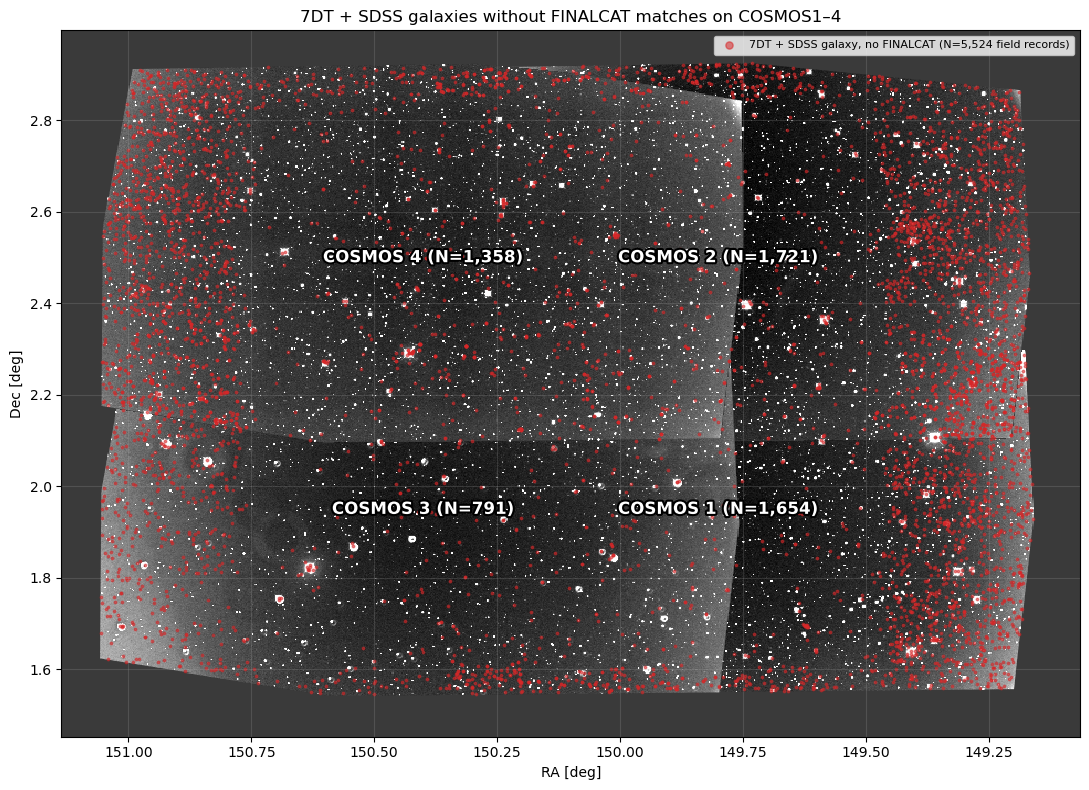

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/output/singlephot/analysis/test_sdss_galaxies_without_finalcat/cosmos1-4_7dt_sdss_galaxies_without_finalcat_spatial.png


In [5]:
# Match notebook 2.2's FINALCAT RoI presentation: pooled grayscale mosaic,
# common ZScale stretch, WCS-derived extents, red source positions, and field labels.
fig, ax = plt.subplots(figsize=(11, 8))
ax.set_facecolor('#3a3a3a')
for field in (1, 2, 3, 4):
    fp = footprints[field]
    ax.imshow(fp['pooled'], origin='lower', cmap='gray', norm=norm,
              extent=[fp['ra_max'], fp['ra_min'], fp['dec_min'], fp['dec_max']],
              interpolation='nearest', alpha=1.0, aspect='auto')
ra = np.ma.filled(selected_sources['master_ra'], np.nan).astype(float)
dec = np.ma.filled(selected_sources['master_dec'], np.nan).astype(float)
finite = np.isfinite(ra) & np.isfinite(dec)
ax.scatter(ra[finite], dec[finite], s=3, c='tab:red', alpha=0.55, rasterized=True,
           label=f'7DT + SDSS galaxy, no FINALCAT (N={int(finite.sum()):,} field records)')
for field in (1, 2, 3, 4):
    fp = footprints[field]
    count = summary['N_selected'][field - 1]
    ax.text((fp['ra_max'] + fp['ra_min']) / 2,
            (fp['dec_max'] + fp['dec_min']) / 2,
            f'COSMOS {field} (N={count:,})', color='white', fontsize=12,
            fontweight='bold', ha='center', va='center',
            path_effects=[patheffects.withStroke(linewidth=3, foreground='black')])
ax.set_xlim(RA_MAX + PAD_DEG, RA_MIN - PAD_DEG)
ax.set_ylim(DEC_MIN - PAD_DEG, DEC_MAX + PAD_DEG)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title('7DT + SDSS galaxies without FINALCAT matches on COSMOS1–4')
ax.grid(alpha=0.2)
ax.legend(loc='upper right', fontsize=8, markerscale=3)
fig.tight_layout()
fig.savefig(FIG_PATH, dpi=160, bbox_inches='tight')
plt.show()
print(f'Saved {FIG_PATH}')


## Proposed field scale: FINALCAT sources with RM ≤ 21

Select finite, positive `RM ≤ 21` values and finite FINALCAT RA/Dec positions. Zero, negative sentinel values, and nonfinite magnitudes are excluded. No redshift or morphology selection is applied.

Use the selected sample’s median RA and Dec, rounded to 0.01 degree, as an illustrative pointing center. The supplied FoV is interpreted directly as **ΔRA = 1.34° and ΔDec = 0.90°**, so the rectangle extends ±0.67° in RA and ±0.45° in Dec. These are coordinate spans; no cos(Dec) correction is applied. This illustrates field scale; the center has not been optimized. The plot follows the FINALCAT RoI RA/Dec presentation with red source markers, RA increasing to the left, and no image background.

FINALCAT sources with valid RM <= 21: 6,991
Sample median (RA, Dec): (150.120372, 2.284547) deg
Illustrative pointing center (RA, Dec): (150.12, 2.28) deg
FoV coordinate spans: RA 1.34 deg x Dec 0.90 deg
RA bounds: [149.450, 150.790] deg
Dec bounds: [1.830, 2.730] deg
Selected sources inside rectangle: 5,025 / 6,991 (71.88%)


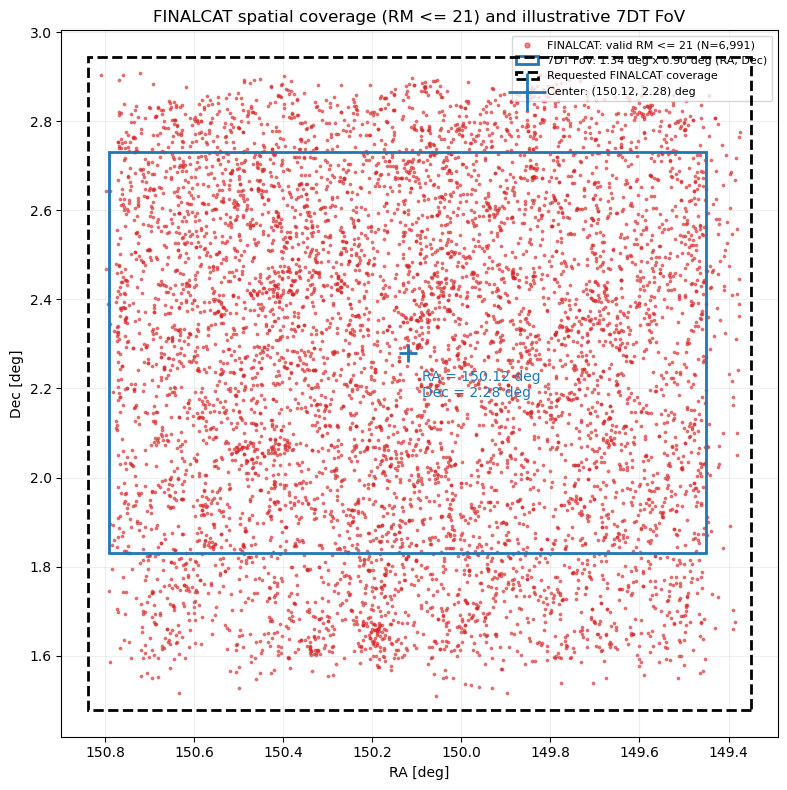

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/output/proposal/finalcat_rm_le21_7dt_fov.png


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from astropy.table import Table
from IPython.display import display

# Keep this planning cell independently runnable from either standard working directory.
PROPOSAL_ROOT = Path.cwd().resolve()
if not (PROPOSAL_ROOT / 'COSMOS_data').is_dir():
    PROPOSAL_ROOT = PROPOSAL_ROOT.parent
PROPOSAL_OUTPUT = PROPOSAL_ROOT / 'output' / 'proposal'
PROPOSAL_OUTPUT.mkdir(parents=True, exist_ok=True)
PROPOSAL_FIG_PATH = PROPOSAL_OUTPUT / 'finalcat_rm_le21_7dt_fov.png'

proposal_finalcat = Table.read(PROPOSAL_ROOT / 'COSMOS_data' / 'COSMOS_finalcat.fits')
# RM is the FINALCAT Subaru r+ total AB magnitude. Positive finite values
# reject missing magnitudes encoded as 0, -99, NaN, or infinity.
proposal_rm = np.ma.filled(proposal_finalcat['RM'], np.nan).astype(float)
proposal_ra_all = np.ma.filled(proposal_finalcat['RA'], np.nan).astype(float)
proposal_dec_all = np.ma.filled(proposal_finalcat['DEC'], np.nan).astype(float)
proposal_selection = (np.isfinite(proposal_rm) & (proposal_rm > 0) & (proposal_rm <= 21)
                      & np.isfinite(proposal_ra_all) & np.isfinite(proposal_dec_all))
proposal_sources = proposal_finalcat[proposal_selection]
proposal_ra = proposal_ra_all[proposal_selection]
proposal_dec = proposal_dec_all[proposal_selection]

# Round the sample medians to convenient coordinates for this scale illustration.
FOV_RA_DEG = 1.34
FOV_DEC_DEG = 0.90
POINTING_RA_DEG = float(np.round(np.median(proposal_ra), 2))
POINTING_DEC_DEG = float(np.round(np.median(proposal_dec), 2))
fov_ra_min = POINTING_RA_DEG - FOV_RA_DEG / 2
fov_ra_max = POINTING_RA_DEG + FOV_RA_DEG / 2
fov_dec_min = POINTING_DEC_DEG - FOV_DEC_DEG / 2
fov_dec_max = POINTING_DEC_DEG + FOV_DEC_DEG / 2
# The rectangular containment count uses the supplied coordinate spans.
inside_proposed_fov = ((proposal_ra >= fov_ra_min) & (proposal_ra <= fov_ra_max)
                       & (proposal_dec >= fov_dec_min) & (proposal_dec <= fov_dec_max))
print(f'FINALCAT sources with valid RM <= 21: {len(proposal_sources):,}')
print(f'Sample median (RA, Dec): ({np.median(proposal_ra):.6f}, {np.median(proposal_dec):.6f}) deg')
print(f'Illustrative pointing center (RA, Dec): ({POINTING_RA_DEG:.2f}, {POINTING_DEC_DEG:.2f}) deg')
print(f'FoV coordinate spans: RA {FOV_RA_DEG:.2f} deg x Dec {FOV_DEC_DEG:.2f} deg')
print(f'RA bounds: [{fov_ra_min:.3f}, {fov_ra_max:.3f}] deg')
print(f'Dec bounds: [{fov_dec_min:.3f}, {fov_dec_max:.3f}] deg')
print(f'Selected sources inside rectangle: {inside_proposed_fov.sum():,} / {len(proposal_sources):,} '
      f'({100 * inside_proposed_fov.mean():.2f}%)')

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(proposal_ra, proposal_dec, s=3, c='tab:red', alpha=0.55,
           rasterized=True, label=f'FINALCAT: valid RM <= 21 (N={len(proposal_sources):,})')
ax.add_patch(Rectangle((fov_ra_min, fov_dec_min), FOV_RA_DEG, FOV_DEC_DEG,
                       fill=False, edgecolor='tab:blue', linewidth=2,
                       label=f'7DT FoV: {FOV_RA_DEG:.2f} deg x {FOV_DEC_DEG:.2f} deg (RA, Dec)'))
# User-specified FINALCAT bounding rectangle in J2000 coordinate degrees.
# These limits describe the requested coverage, independently of the RM selection.
COVERAGE_RA_MIN, COVERAGE_RA_MAX = 149.35002, 150.837601
COVERAGE_DEC_MIN, COVERAGE_DEC_MAX = 1.478139, 2.943833
ax.add_patch(Rectangle(
    (COVERAGE_RA_MIN, COVERAGE_DEC_MIN),
    COVERAGE_RA_MAX - COVERAGE_RA_MIN, COVERAGE_DEC_MAX - COVERAGE_DEC_MIN,
    fill=False, edgecolor='black', linewidth=2, linestyle='--', zorder=6,
    label='Requested FINALCAT coverage'))
ax.scatter([POINTING_RA_DEG], [POINTING_DEC_DEG], marker='+', s=180,
           c='tab:blue', linewidths=2, zorder=5,
           label=f'Center: ({POINTING_RA_DEG:.2f}, {POINTING_DEC_DEG:.2f}) deg')
# Place the center annotation below the marker so the pointing remains visible.
ax.annotate(f'RA = {POINTING_RA_DEG:.2f} deg\nDec = {POINTING_DEC_DEG:.2f} deg',
            (POINTING_RA_DEG, POINTING_DEC_DEG), xytext=(10, -32),
            textcoords='offset points', fontsize=10, color='tab:blue')
plot_pad = 0.06
ax.set_xlim(max(proposal_ra.max(), fov_ra_max, COVERAGE_RA_MAX) + plot_pad,
            min(proposal_ra.min(), fov_ra_min, COVERAGE_RA_MIN) - plot_pad)
ax.set_ylim(min(proposal_dec.min(), fov_dec_min, COVERAGE_DEC_MIN) - plot_pad,
            max(proposal_dec.max(), fov_dec_max, COVERAGE_DEC_MAX) + plot_pad)
# Equal coordinate-degree scaling makes the rectangle's supplied aspect visible.
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title('FINALCAT spatial coverage (RM <= 21) and illustrative 7DT FoV')
ax.grid(alpha=0.2)
ax.legend(loc='upper right', fontsize=8, markerscale=2)
fig.tight_layout()
fig.savefig(PROPOSAL_FIG_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {PROPOSAL_FIG_PATH}')


## Existing COSMOS1–4 centers

Reference layout using original detection-image WCS centers with no offsets and the original COSMOS field identifiers. Each rectangle spans 1.34° in RA and 0.90° in Dec.

COSMOS,center_RA_deg,center_Dec_deg,N_RM_le21_in_FoV
int64,float64,float64,int64
1,149.80000,1.95000,3318
2,149.80000,2.50000,3704
3,150.40000,1.95000,3369
4,150.40000,2.50000,3836


FINALCAT RM <= 21 sources inside at least one rectangle: 6,991 / 6,991 (100.00%)


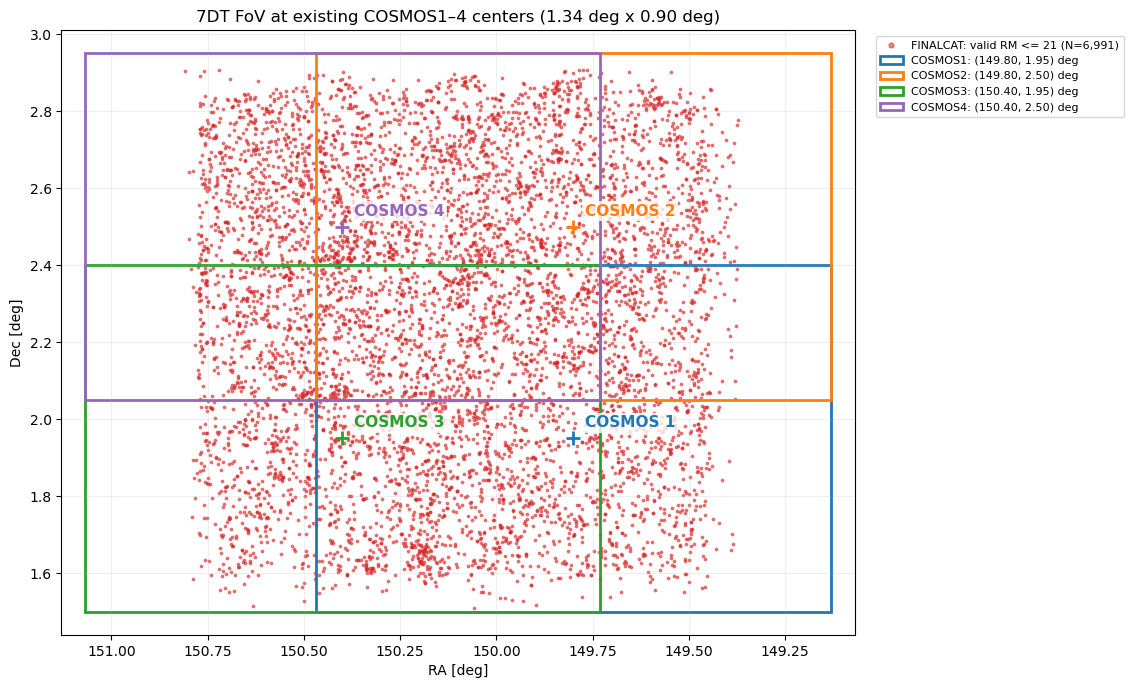

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/output/proposal/finalcat_rm_le21_existing_cosmos1-4_7dt_fov.png


In [7]:
from astropy.io import fits
from astropy.wcs import WCS

# Reuse the FINALCAT selection and supplied FoV dimensions from the preceding section.
# Always offset the original WCS centers, so rerunning does not accumulate shifts.
DEC_OFFSETS_DEG = {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0}
existing_field_centers = []
field_rectangle_masks = []
for field in (1, 2, 3, 4):
    detection_path = PROPOSAL_ROOT / 'COSMOS_data' / f'COSMOS{field}' / f'COSMOS{field}_detectionimage.fits'
    header = fits.getheader(detection_path)
    field_wcs = WCS(header).celestial
    # FITS coordinates are 1-based; this is the center of the entire detection image.
    center_pixel = [[(int(header['NAXIS1']) + 1) / 2,
                     (int(header['NAXIS2']) + 1) / 2]]
    center_ra, center_dec = field_wcs.all_pix2world(center_pixel, 1)[0]
    # Retain each original WCS center for the comparison plot.
    center_dec = float(center_dec) + DEC_OFFSETS_DEG[field]
    field_mask = ((np.abs(proposal_ra - center_ra) <= FOV_RA_DEG / 2)
                  & (np.abs(proposal_dec - center_dec) <= FOV_DEC_DEG / 2))
    field_rectangle_masks.append(field_mask)
    existing_field_centers.append((field, float(center_ra), float(center_dec),
                                   int(field_mask.sum())))

existing_field_summary = Table(rows=existing_field_centers,
    names=['COSMOS', 'center_RA_deg', 'center_Dec_deg', 'N_RM_le21_in_FoV'])
existing_field_summary['center_RA_deg'].info.format = '.5f'
existing_field_summary['center_Dec_deg'].info.format = '.5f'
display(existing_field_summary)
inside_existing_union = np.any(np.vstack(field_rectangle_masks), axis=0)
print(f'FINALCAT RM <= 21 sources inside at least one rectangle: '
      f'{inside_existing_union.sum():,} / {len(proposal_sources):,} '
      f'({100 * inside_existing_union.mean():.2f}%)')
existing_field_summary.write(PROPOSAL_OUTPUT / 'existing_cosmos_field_centers_fov.csv',
                             format='ascii.csv', overwrite=True)

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(proposal_ra, proposal_dec, s=3, c='tab:red', alpha=0.55, rasterized=True,
           label=f'FINALCAT: valid RM <= 21 (N={len(proposal_sources):,})')
field_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple']
all_box_ra, all_box_dec = [], []
for (field, center_ra, center_dec, count), color in zip(existing_field_centers, field_colors):
    ra_low = center_ra - FOV_RA_DEG / 2
    dec_low = center_dec - FOV_DEC_DEG / 2
    ax.add_patch(Rectangle((ra_low, dec_low), FOV_RA_DEG, FOV_DEC_DEG,
                           fill=False, edgecolor=color, linewidth=2,
                           label=f'COSMOS{field}: ({center_ra:.2f}, {center_dec:.2f}) deg'))
    ax.scatter([center_ra], [center_dec], marker='+', s=110, c=color,
               linewidths=2, zorder=5)
    ax.annotate(f'COSMOS {field}', (center_ra, center_dec), xytext=(8, 8),
                textcoords='offset points', color=color, fontsize=11,
                fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
    all_box_ra.extend([ra_low, ra_low + FOV_RA_DEG])
    all_box_dec.extend([dec_low, dec_low + FOV_DEC_DEG])
# Include complete FoV rectangles even where they extend beyond the catalog footprint.
ax.set_xlim(max(proposal_ra.max(), max(all_box_ra)) + 0.06,
            min(proposal_ra.min(), min(all_box_ra)) - 0.06)
ax.set_ylim(min(proposal_dec.min(), min(all_box_dec)) - 0.06,
            max(proposal_dec.max(), max(all_box_dec)) + 0.06)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title('7DT FoV at existing COSMOS1–4 centers (1.34 deg x 0.90 deg)')
ax.grid(alpha=0.2)
# Keep the legend outside the axes so it does not obscure catalog sources.
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8, markerscale=2)
fig.tight_layout()
EXISTING_FIELDS_FIG_PATH = PROPOSAL_OUTPUT / 'finalcat_rm_le21_existing_cosmos1-4_7dt_fov.png'
fig.savefig(EXISTING_FIELDS_FIG_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {EXISTING_FIELDS_FIG_PATH}')


## Proposal fields numbered by displayed quadrants

RA increases to the left in this astronomical plot. Following the visual mathematical quadrant convention, Proposal 1 is upper right, Proposal 2 upper left, Proposal 3 lower left, and Proposal 4 lower right. The original COSMOS identities remain in the printed provenance and summary CSV.

The proposal uses the original COSMOS1/3 centers minus 0.05° in Dec and COSMOS2/4 centers plus 0.05° in Dec. RA and the 1.34° × 0.90° FoV are retained. Center coordinates are printed with Python float `repr` (no decimal precision truncation or fixed-width table formatting).

Proposal 1 (original COSMOS2): RA = 149.8 deg, Dec = 2.55 deg; N_RM_le21 = 3484
Proposal 2 (original COSMOS4): RA = 150.4 deg, Dec = 2.55 deg; N_RM_le21 = 3616
Proposal 3 (original COSMOS3): RA = 150.4 deg, Dec = 1.9000000000000028 deg; N_RM_le21 = 3136
Proposal 4 (original COSMOS1): RA = 149.8 deg, Dec = 1.9000000000000028 deg; N_RM_le21 = 3086


Proposal_field,Original_COSMOS,center_RA_deg,center_Dec_deg,N_RM_le21_in_FoV
int64,int64,float64,float64,int64
1,2,149.8,2.55,3484
2,4,150.4,2.55,3616
3,3,150.4,1.9000000000000028,3136
4,1,149.8,1.9000000000000028,3086


FINALCAT RM <= 21 sources inside at least one rectangle: 6,991 / 6,991 (100.00%)


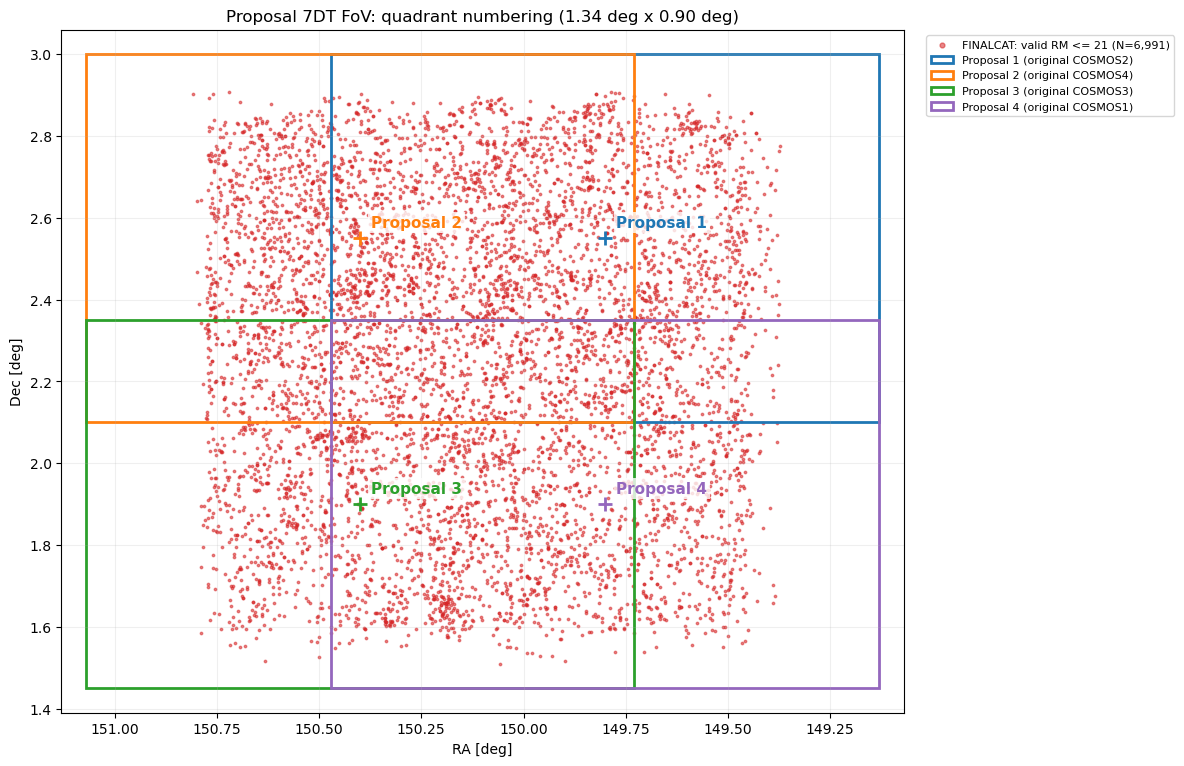

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/output/proposal/proposal_finalcat_rm_le21_cosmos1-4_dec_offset_0p05_fov.png


In [8]:
from astropy.io import fits
from astropy.wcs import WCS

# Reuse the FINALCAT selection and supplied FoV dimensions from the preceding section.
# Always offset the original WCS centers, so rerunning does not accumulate shifts.
DEC_OFFSETS_DEG = {1: -0.05, 2: +0.05, 3: -0.05, 4: +0.05}
# Mapping is based on displayed quadrants, accounting for the reversed RA axis.
# Preserve the original field ID so proposal numbering cannot alter file selection.
PROPOSAL_TO_COSMOS = {1: 2, 2: 4, 3: 3, 4: 1}
proposal_field_centers = []
field_rectangle_masks = []
for proposal_field, field in PROPOSAL_TO_COSMOS.items():
    detection_path = PROPOSAL_ROOT / 'COSMOS_data' / f'COSMOS{field}' / f'COSMOS{field}_detectionimage.fits'
    header = fits.getheader(detection_path)
    field_wcs = WCS(header).celestial
    # FITS coordinates are 1-based; this is the center of the entire detection image.
    center_pixel = [[(int(header['NAXIS1']) + 1) / 2,
                     (int(header['NAXIS2']) + 1) / 2]]
    center_ra, center_dec = field_wcs.all_pix2world(center_pixel, 1)[0]
    # Move the northern fields north and the southern fields south; retain RA.
    center_dec = float(center_dec) + DEC_OFFSETS_DEG[field]
    field_mask = ((np.abs(proposal_ra - center_ra) <= FOV_RA_DEG / 2)
                  & (np.abs(proposal_dec - center_dec) <= FOV_DEC_DEG / 2))
    field_rectangle_masks.append(field_mask)
    proposal_field_centers.append((proposal_field, field, float(center_ra), float(center_dec),
                                   int(field_mask.sum())))

existing_field_summary = Table(rows=proposal_field_centers,
    names=['Proposal_field', 'Original_COSMOS', 'center_RA_deg', 'center_Dec_deg', 'N_RM_le21_in_FoV'])
# repr retains the complete round-trip decimal representation of each float.
for proposal_field, original_cosmos, center_ra, center_dec, count in proposal_field_centers:
    print(f'Proposal {proposal_field} (original COSMOS{original_cosmos}): '
          f'RA = {center_ra!r} deg, Dec = {center_dec!r} deg; N_RM_le21 = {count}')
display(existing_field_summary)
inside_existing_union = np.any(np.vstack(field_rectangle_masks), axis=0)
print(f'FINALCAT RM <= 21 sources inside at least one rectangle: '
      f'{inside_existing_union.sum():,} / {len(proposal_sources):,} '
      f'({100 * inside_existing_union.mean():.2f}%)')
existing_field_summary.write(PROPOSAL_OUTPUT / 'proposal_cosmos_field_centers_dec_offset_0p05_fov.csv',
                             format='ascii.csv', overwrite=True)

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(proposal_ra, proposal_dec, s=3, c='tab:red', alpha=0.55, rasterized=True,
           label=f'FINALCAT: valid RM <= 21 (N={len(proposal_sources):,})')
field_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple']
all_box_ra, all_box_dec = [], []
for (field, original_cosmos, center_ra, center_dec, count), color in zip(proposal_field_centers, field_colors):
    ra_low = center_ra - FOV_RA_DEG / 2
    dec_low = center_dec - FOV_DEC_DEG / 2
    ax.add_patch(Rectangle((ra_low, dec_low), FOV_RA_DEG, FOV_DEC_DEG,
                           fill=False, edgecolor=color, linewidth=2,
                           label=f'Proposal {field} (original COSMOS{original_cosmos})'))
    ax.scatter([center_ra], [center_dec], marker='+', s=110, c=color,
               linewidths=2, zorder=5)
    ax.annotate(f'Proposal {field}', (center_ra, center_dec), xytext=(8, 8),
                textcoords='offset points', color=color, fontsize=11,
                fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
    all_box_ra.extend([ra_low, ra_low + FOV_RA_DEG])
    all_box_dec.extend([dec_low, dec_low + FOV_DEC_DEG])
# Include complete FoV rectangles even where they extend beyond the catalog footprint.
ax.set_xlim(max(proposal_ra.max(), max(all_box_ra)) + 0.06,
            min(proposal_ra.min(), min(all_box_ra)) - 0.06)
ax.set_ylim(min(proposal_dec.min(), min(all_box_dec)) - 0.06,
            max(proposal_dec.max(), max(all_box_dec)) + 0.06)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title('Proposal 7DT FoV: quadrant numbering (1.34 deg x 0.90 deg)')
ax.grid(alpha=0.2)
# Keep the legend outside the axes so it does not obscure catalog sources.
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8, markerscale=2)
fig.tight_layout()
EXISTING_FIELDS_FIG_PATH = PROPOSAL_OUTPUT / 'proposal_finalcat_rm_le21_cosmos1-4_dec_offset_0p05_fov.png'
fig.savefig(EXISTING_FIELDS_FIG_PATH, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved {EXISTING_FIELDS_FIG_PATH}')


## ETC exposure-time comparison: Dark sky, Good/Poor conditions

Compare the original `dark-good.csv` and `dark-poor.csv` with stacked exposure times from **COSMOS1–4**. The next section repeats this comparison for the supplied **z = 0.3** exports. The original CSV redshift is not recorded in its schema; the first plot is identified as z = 0 per the requested comparison. Both scenarios use r = 21 AB mag, S/N = 5, and one telescope unit per filter. Good/Poor and z = 0.3 labels follow the supplied filenames/user context; the CSV does not encode sky condition or redshift explicitly.

Use the 20 medium bands m400–m875 at 25 nm intervals, excluding broad-band r and ETC-only interpolated filters. Join each coadd by its FITS `FILTER` header. At each band, bars run left to right: **CSV Good, CSV Poor, COSMOS1, COSMOS2, COSMOS3, COSMOS4**. COSMOS colors are **red, green, blue, purple**. Missing coadds retain an empty slot with an × marker (not a zero exposure). Each figure uses one tall linear panel, with horizontal grid lines every 5 hours. Numerical y-axis labels are spaced by 5 hours for the original target and 50 hours for z = 0.3 to keep the larger range readable.

ETC requirements use `frames_of_100s_per_unit × 100 s`; summary CSVs also retain continuous ETC values. COSMOS1–3 FITS headers define EXPTIME as total combined exposure; COSMOS4 defines it as maximum equivalent exposure time. COSMOS IDs here refer to the original data directories, not the display-only Field numbers in the later sky maps.

**Interpretation:** a sum over filters is an integration-time budget, not a wall-clock allocation. Telescope concurrency, pointing count, and overheads are excluded. Exposure-time comparison alone does not establish measured depth or S/N. The CSV does not specify aperture, surface-brightness normalization, or galaxy type.


In [9]:
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from IPython.display import display, Markdown

# Resolve paths independently so the ETC sections run from root or Notebooks.
ETC_PROJECT_ROOT = Path.cwd().resolve()
if not (ETC_PROJECT_ROOT / 'COSMOS_data').is_dir():
    ETC_PROJECT_ROOT = ETC_PROJECT_ROOT.parent
ETC_REPORT_DIR = ETC_PROJECT_ROOT / 'Report' / '7DT Observation Proposal'
ETC_BANDS = tuple(f'm{wave}' for wave in range(400, 900, 25))
ETC_FIELDS = (1, 2, 3, 4)
ETC_FIELD_COLORS = {1: 'red', 2: 'green', 3: 'blue', 4: 'purple'}

# Join on FILTER, never file order. NaN means unavailable, not zero seconds.
ETC_COSMOS_SECONDS = {}
for field in ETC_FIELDS:
    coadd_dir = ETC_PROJECT_ROOT / 'COSMOS_data' / f'COSMOS{field}'
    if not coadd_dir.is_dir():
        raise FileNotFoundError(coadd_dir)
    exposures = {}
    for image_path in sorted(coadd_dir.glob('*.com.fits')):
        header = fits.getheader(image_path)
        band = str(header['FILTER']).strip()
        if band not in ETC_BANDS:
            continue
        if band in exposures:
            raise ValueError(f'Multiple COSMOS{field} coadds for {band}')
        seconds = float(header['EXPTIME'])
        if not np.isfinite(seconds) or seconds <= 0:
            raise ValueError(f'Invalid EXPTIME in {image_path}')
        exposures[band] = seconds
    ETC_COSMOS_SECONDS[field] = np.array([exposures.get(b, np.nan) for b in ETC_BANDS])
    missing = [b for b in ETC_BANDS if b not in exposures]
    print(f'COSMOS{field}: {len(exposures)} bands; unavailable: {", ".join(missing) or "none"}')
# Retain this alias for the existing original-target interpretation cell.
COSMOS1_ETC_SECONDS = ETC_COSMOS_SECONDS[1]


def load_etc_scenario(files):
    """Validate a Good/Poor pair without equating spectra across redshifts.

    Only native 7DT medium bands are selected. Source brightness must agree
    between Good and Poor within this scenario, but can differ at z = 0.3.
    """
    records_by_condition, exact_times, rounded_times = {}, {}, {}
    reference_magnitudes = None
    for condition, filename in files.items():
        with (ETC_REPORT_DIR / filename).open(newline='') as handle:
            rows = list(csv.DictReader(handle))
        filters = [row['filter'] for row in rows]
        if len(filters) != len(set(filters)):
            raise ValueError(f'Duplicate filters in {filename}')
        records = {row['filter']: row for row in rows}
        missing = set(ETC_BANDS) - records.keys()
        if missing:
            raise ValueError(f'{filename}: missing bands {sorted(missing)}')
        mags = np.array([float(records[b]['mag_AB']) for b in ETC_BANDS])
        if reference_magnitudes is None:
            reference_magnitudes = mags
        if not np.all(np.isfinite(mags)) or not np.allclose(mags, reference_magnitudes, rtol=0, atol=1e-10):
            raise ValueError(f'Target brightness differs within {filename}')
        # The broad-band normalization is stated on both plot captions.
        if not np.isclose(float(records['r']['mag_AB']), 21, rtol=0, atol=1e-10):
            raise ValueError(f'Expected r = 21 AB mag in {filename}')
        if any(float(records[b]['SNR_target']) != 5 or float(records[b]['units']) != 1
               for b in ETC_BANDS):
            raise ValueError(f'Expected S/N=5, units=1 in {filename}')
        seconds = np.array([float(records[b]['total_exptime_per_unit_s']) for b in ETC_BANDS])
        frames = np.array([float(records[b]['frames_of_100s_per_unit']) for b in ETC_BANDS])
        if not np.all(np.isfinite(seconds) & (seconds > 0)):
            raise ValueError(f'Invalid ETC time in {filename}')
        if not np.array_equal(frames, np.ceil(seconds / 100)):
            raise ValueError(f'Unexpected 100-second frame counts in {filename}')
        records_by_condition[condition] = records
        exact_times[condition] = seconds
        rounded_times[condition] = frames * 100
    return records_by_condition, reference_magnitudes, exact_times, rounded_times


def summarize_etc_scenario(files, magnitudes, exact, rounded, output_stem):
    """Save reproducible per-band times; report missing coadds separately.

    Counts compare requirements with available exposures only. No missing
    field/band pair is counted as a measured zero-second integration.
    """
    rows = []
    for condition in files:
        needed = rounded[condition]
        longest = int(np.argmax(needed))
        row = [condition, exact[condition].sum()/3600, needed.sum()/3600,
               ETC_BANDS[longest], needed[longest]/3600]
        for field in ETC_FIELDS:
            observed = ETC_COSMOS_SECONDS[field]
            available = np.isfinite(observed)
            row.extend([int(np.sum(available & (observed < needed))), int(np.sum(~available))])
        rows.append(row)
    names = ['Condition', 'Exact_sum_h', '100s_frame_sum_h', 'Longest_band', 'Longest_band_h']
    for field in ETC_FIELDS:
        names.extend([f'N_longer_than_COSMOS{field}', f'N_missing_COSMOS{field}'])
    summary = Table(rows=rows, names=names)
    for name in ('Exact_sum_h', '100s_frame_sum_h', 'Longest_band_h'):
        summary[name].info.format = '.2f'
    display(summary)
    per_band = Table()
    per_band['Filter'] = ETC_BANDS
    per_band['CSV_mag_AB'] = magnitudes
    for condition in files:
        prefix = condition.replace(' / ', '_')
        per_band[prefix + '_exact_s'] = exact[condition]
        per_band[prefix + '_100s_frames_s'] = rounded[condition]
    for field in ETC_FIELDS:
        per_band[f'COSMOS{field}_s'] = ETC_COSMOS_SECONDS[field]
    # CSV columns have explicit seconds units; absent coadds are stored as NaN.
    per_band.write(ETC_REPORT_DIR / f'{output_stem}_by_band.csv', format='ascii.csv', overwrite=True)
    summary.write(ETC_REPORT_DIR / f'{output_stem}_summary.csv', format='ascii.csv', overwrite=True)
    return summary, per_band


ETC_FILES = {'Dark / Good': 'dark-good.csv', 'Dark / Poor': 'dark-poor.csv'}
ETC_RESULTS, ETC_TARGET_MAG, ETC_EXACT_SECONDS, ETC_ROUNDED_SECONDS = load_etc_scenario(ETC_FILES)
ETC_SUMMARY, ETC_BY_BAND = summarize_etc_scenario(
    ETC_FILES, ETC_TARGET_MAG, ETC_EXACT_SECONDS, ETC_ROUNDED_SECONDS,
    'etc_dark_good_poor_comparison')


COSMOS1: 20 bands; unavailable: none
COSMOS2: 16 bands; unavailable: m650, m675, m800, m825
COSMOS3: 18 bands; unavailable: m650, m675
COSMOS4: 16 bands; unavailable: m450, m475, m650, m675


Condition,Exact_sum_h,100s_frame_sum_h,Longest_band,Longest_band_h,N_longer_than_COSMOS1,N_missing_COSMOS1,N_longer_than_COSMOS2,N_missing_COSMOS2,N_longer_than_COSMOS3,N_missing_COSMOS3,N_longer_than_COSMOS4,N_missing_COSMOS4
str11,float64,float64,str4,float64,int64,int64,int64,int64,int64,int64,int64,int64
Dark / Good,114.52,114.81,m400,36.58,9,0,11,4,17,2,14,4
Dark / Poor,147.50,147.81,m400,46.83,11,0,14,4,18,2,16,4


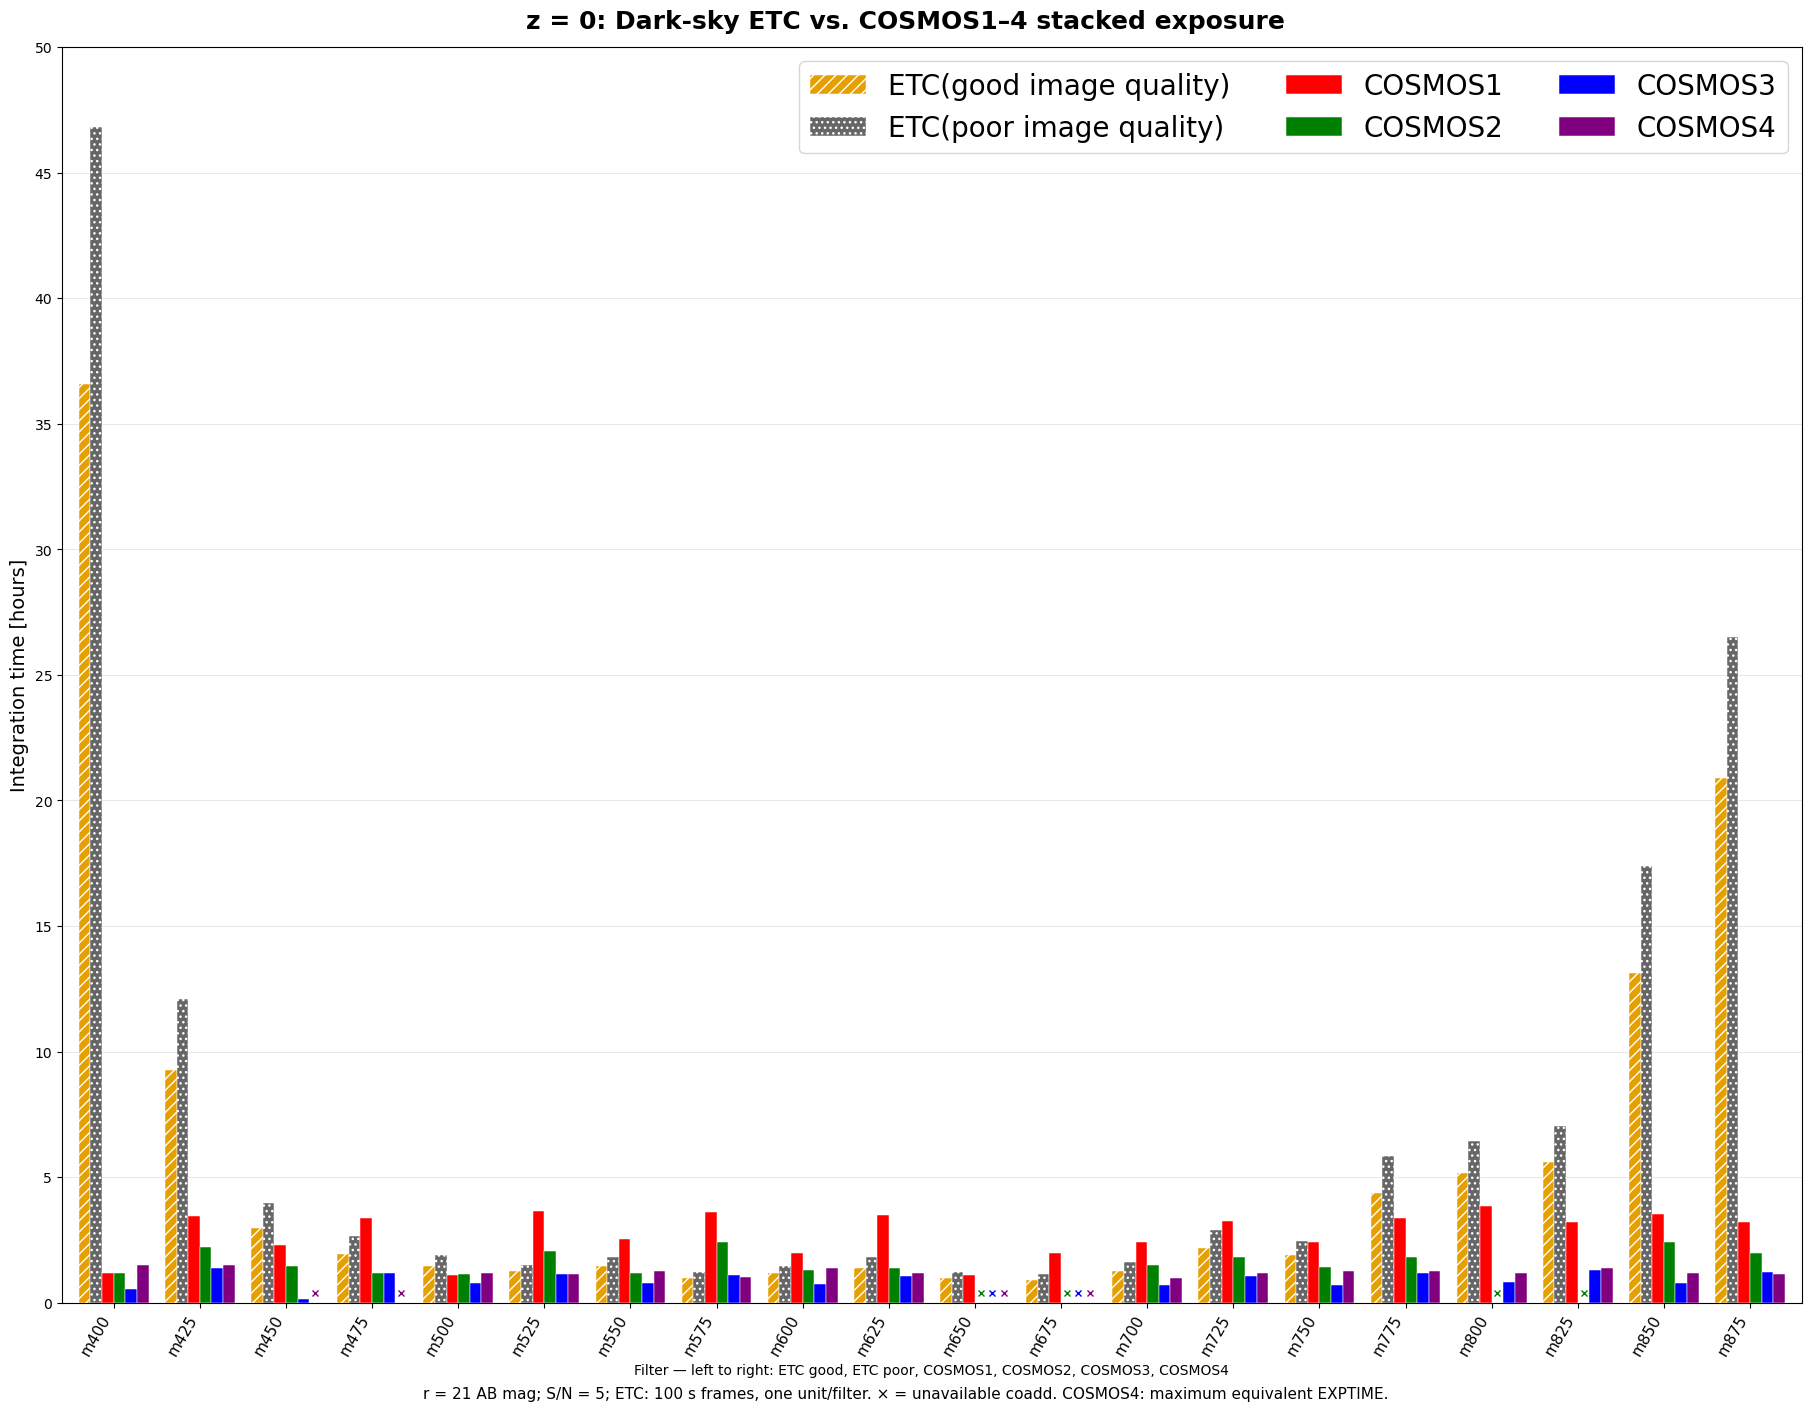

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/etc_dark_good_poor_comparison.png


In [10]:
def plot_etc_grouped_bars(rounded_seconds, scenario_label, output_name, excluded_bands=()):
    """Plot six fixed slots per filter, preserving gaps for missing coadds.

    Use a tall linear axis in hours with horizontal grid lines every five
    hours. Preserve the complete exposure range without clipping tall bars.
    """
    # Apply one band mask to every series so CSV and coadd bars stay aligned.
    # Exclusion affects this visualization only; full-band summaries are kept.
    unknown = set(excluded_bands) - set(ETC_BANDS)
    if unknown:
        raise ValueError(f'Unknown excluded bands: {sorted(unknown)}')
    selected = np.array([band not in excluded_bands for band in ETC_BANDS])
    plot_bands = np.asarray(ETC_BANDS)[selected]
    if not len(plot_bands):
        raise ValueError('At least one band must remain in the plot')
    x = np.arange(len(plot_bands))
    width = 0.135
    series = [
        ('ETC(good image quality)', rounded_seconds['Dark / Good'], '#E69F00', '///'),
        ('ETC(poor image quality)', rounded_seconds['Dark / Poor'], '#666666', '...'),
    ] + [(f'COSMOS{field}', ETC_COSMOS_SECONDS[field], ETC_FIELD_COLORS[field], None)
         for field in ETC_FIELDS]
    series = [(label, np.asarray(seconds)[selected], color, hatch)
              for label, seconds, color, hatch in series]
    from matplotlib.ticker import MultipleLocator

    # A taller single linear panel replaces the previous two-panel figure.
    fig, ax = plt.subplots(figsize=(18, 14), layout='constrained')
    for index, (label, seconds, color, hatch) in enumerate(series):
        positions = x + (index - 2.5) * width
        available = np.isfinite(seconds)
        ax.bar(positions[available], seconds[available]/3600, width=width,
               color=color, hatch=hatch, edgecolor='white', linewidth=0.35,
               label=label, zorder=3)
        if np.any(~available):
            # Axes-relative markers flag missing coadds, not zero exposure.
            ax.plot(positions[~available], np.full(np.sum(~available), 0.008),
                    linestyle='none', marker='x', color=color, markersize=5,
                    transform=ax.get_xaxis_transform(), clip_on=False, zorder=5)
    maximum_hours = max(np.nanmax(item[1])/3600 for item in series)
    upper_hours = np.ceil(maximum_hours * 1.05 / 5) * 5
    ax.set_ylim(0, upper_hours)
    ax.set_ylabel('Integration time [hours]', fontsize=14)
    ax.set_axisbelow(True)
    # Grid lines always occur every five hours. For the much larger z=0.3
    # range, label every 50 hours so tick text remains readable; intermediate
    # five-hour lines are minor grid lines, with no numerical data omitted.
    major_spacing = 50 if upper_hours > 150 else 5
    ax.yaxis.set_major_locator(MultipleLocator(major_spacing))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.grid(axis='y', which='major', alpha=0.3, linewidth=0.7)
    ax.grid(axis='y', which='minor', alpha=0.2, linewidth=0.5)
    ax.set_xlim(-0.6, len(x)-0.4)
    ax.legend(ncol=3, loc='upper right', fontsize=20)
    ax.set_xticks(x, plot_bands, rotation=60, ha='right', fontsize=11)
    ax.set_xlabel('Filter — left to right: ETC good, ETC poor, COSMOS1, COSMOS2, COSMOS3, COSMOS4')
    fig.suptitle(f'{scenario_label}: Dark-sky ETC vs. COSMOS1–4 stacked exposure',
                 fontsize=18, fontweight='bold')
    fig.supxlabel('r = 21 AB mag; S/N = 5; ETC: 100 s frames, one unit/filter. '
                  '× = unavailable coadd. COSMOS4: maximum equivalent EXPTIME.', fontsize=11)
    output_path = ETC_REPORT_DIR / output_name
    fig.savefig(output_path, dpi=180)
    plt.show()
    print(f'Saved {output_path}')
    return output_path


ETC_COMPARISON_FIG_PATH = plot_etc_grouped_bars(
    ETC_ROUNDED_SECONDS, 'z = 0', 'etc_dark_good_poor_comparison.png')


In [11]:
# Recalculate the prose from the loaded files so reruns cannot retain stale
# numerical conclusions after an ETC export is replaced.
def etc_exact_hours(condition):
    """Return continuous ETC integration time summed across the 20 bands."""
    return float(ETC_EXACT_SECONDS[condition].sum() / 3600)

m400_index = ETC_BANDS.index('m400')
m425_index = ETC_BANDS.index('m425')
m875_index = ETC_BANDS.index('m875')
line_items = ['### 비교 결과', '']
line_items.append(
    f"- 100초 프레임 기준 20개 필터의 적분시간 합은 **Dark/Good "
    f"{ETC_ROUNDED_SECONDS['Dark / Good'].sum()/3600:.2f}시간 → Dark/Poor "
    f"{ETC_ROUNDED_SECONDS['Dark / Poor'].sum()/3600:.2f}시간**입니다.")
good, poor = etc_exact_hours('Dark / Good'), etc_exact_hours('Dark / Poor')
line_items.append(f'- Dark sky에서 연속 ETC 계산값 합 기준 Good→Poor는 **{poor/good:.2f}배**입니다.')
for band, index in [('m400', m400_index), ('m425', m425_index), ('m875', m875_index)]:
    good_h = float(ETC_ROUNDED_SECONDS['Dark / Good'][index] / 3600)
    poor_h = float(ETC_ROUNDED_SECONDS['Dark / Poor'][index] / 3600)
    line_items.append(f'- {band}: Dark/Good **{good_h:.2f}시간** / Dark/Poor **{poor_h:.2f}시간**.')
for condition in ETC_FILES:
    short = [band for band, existing, needed in zip(
        ETC_BANDS, COSMOS1_ETC_SECONDS, ETC_ROUNDED_SECONDS[condition]) if existing < needed]
    line_items.append(f'- {condition}: ETC 요구시간이 기존 COSMOS1 노출보다 긴 필터 '
                      f'**{len(short)}개** — ' + ', '.join(short) + '.')
line_items.extend(['', '**해석 범위:** 두 CSV는 동일한 spectrum과 r = 21 AB mag를 사용하며, '
    '비교 조건은 모두 dark sky입니다. CSV만으로 aperture 또는 표면밝기 단위를 정할 수 없습니다. '
    '위 비교는 노출시간 비교이며, 기존 자료의 실측 깊이나 S/N 달성을 입증하지 않습니다. '
    'ETC와 노트북 2.2의 aperture/깊이 정의를 일치시켜야 하므로 요구시간과 기존 시간의 차이를 '
    '곧바로 추가 관측시간으로 사용할 수 없습니다. Good/Poor는 시간 추정 시나리오로 사용합니다.'])
display(Markdown('\n'.join(line_items)))


### 비교 결과

- 100초 프레임 기준 20개 필터의 적분시간 합은 **Dark/Good 114.81시간 → Dark/Poor 147.81시간**입니다.
- Dark sky에서 연속 ETC 계산값 합 기준 Good→Poor는 **1.29배**입니다.
- m400: Dark/Good **36.58시간** / Dark/Poor **46.83시간**.
- m425: Dark/Good **9.25시간** / Dark/Poor **12.08시간**.
- m875: Dark/Good **20.89시간** / Dark/Poor **26.50시간**.
- Dark / Good: ETC 요구시간이 기존 COSMOS1 노출보다 긴 필터 **9개** — m400, m425, m450, m500, m775, m800, m825, m850, m875.
- Dark / Poor: ETC 요구시간이 기존 COSMOS1 노출보다 긴 필터 **11개** — m400, m425, m450, m500, m650, m750, m775, m800, m825, m850, m875.

**해석 범위:** 두 CSV는 동일한 spectrum과 r = 21 AB mag를 사용하며, 비교 조건은 모두 dark sky입니다. CSV만으로 aperture 또는 표면밝기 단위를 정할 수 없습니다. 위 비교는 노출시간 비교이며, 기존 자료의 실측 깊이나 S/N 달성을 입증하지 않습니다. ETC와 노트북 2.2의 aperture/깊이 정의를 일치시켜야 하므로 요구시간과 기존 시간의 차이를 곧바로 추가 관측시간으로 사용할 수 없습니다. Good/Poor는 시간 추정 시나리오로 사용합니다.

## z = 0.3: Dark-sky Good/Poor ETC versus COSMOS1–4

Use the supplied `z0.3dark_good.csv` and `z0.3dark_poor.csv`, retained in `Report/7DT Observation Proposal`. This is a separate target-spectrum scenario: validate Good/Poor magnitudes within this pair, rather than requiring agreement with the original target. Band selection, frame rounding, bar order, field colors, and missing-band handling match the original plot above. The observed COSMOS exposure times are the same comparison data in both figures; they do not depend on the modeled target redshift.

Retain the full 20-band z = 0.3 figure, followed by a second linear figure excluding **m400** from all six series. The latter rescales its y-axis to the remaining 19 bands, retaining 5-hour grid spacing. Exposure summaries above still describe all 20 bands.


Condition,Exact_sum_h,100s_frame_sum_h,Longest_band,Longest_band_h,N_longer_than_COSMOS1,N_missing_COSMOS1,N_longer_than_COSMOS2,N_missing_COSMOS2,N_longer_than_COSMOS3,N_missing_COSMOS3,N_longer_than_COSMOS4,N_missing_COSMOS4
str11,float64,float64,str4,float64,int64,int64,int64,int64,int64,int64,int64,int64
Dark / Good,835.19,835.50,m400,676.33,9,0,10,4,18,2,13,4
Dark / Poor,1073.67,1073.97,m400,865.81,12,0,14,4,18,2,15,4


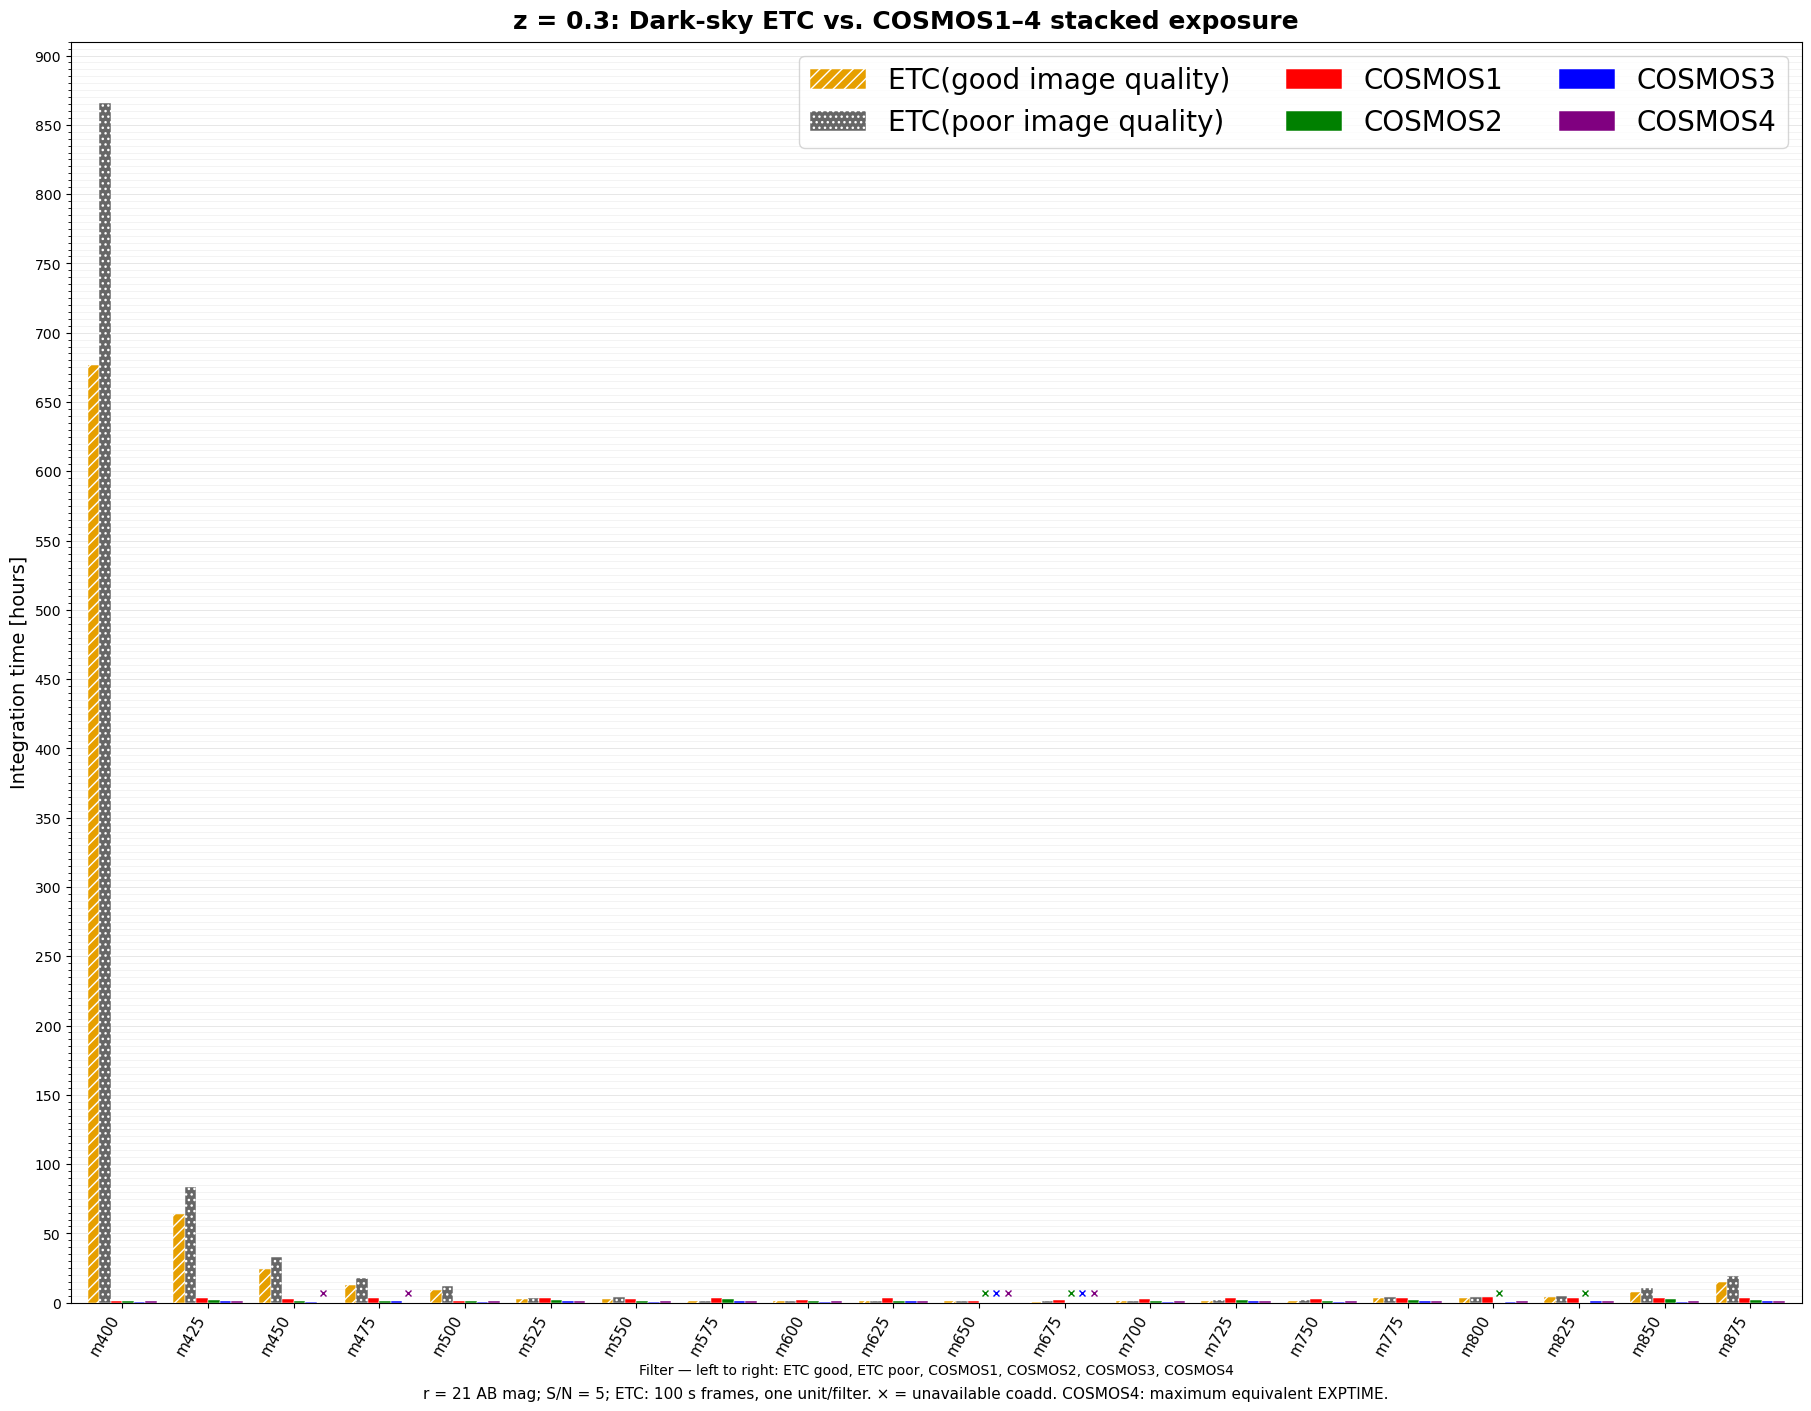

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/etc_z0.3_dark_good_poor_comparison.png


In [12]:
# Run the shared ETC setup and plotting-definition cells above first.
ETC_Z03_FILES = {
    'Dark / Good': 'z0.3dark_good.csv',
    'Dark / Poor': 'z0.3dark_poor.csv',
}
ETC_Z03_RESULTS, ETC_Z03_TARGET_MAG, ETC_Z03_EXACT_SECONDS, ETC_Z03_ROUNDED_SECONDS = load_etc_scenario(ETC_Z03_FILES)
ETC_Z03_SUMMARY, ETC_Z03_BY_BAND = summarize_etc_scenario(
    ETC_Z03_FILES, ETC_Z03_TARGET_MAG, ETC_Z03_EXACT_SECONDS,
    ETC_Z03_ROUNDED_SECONDS, 'etc_z0.3_dark_good_poor_comparison')
ETC_Z03_COMPARISON_FIG_PATH = plot_etc_grouped_bars(
    ETC_Z03_ROUNDED_SECONDS, 'z = 0.3', 'etc_z0.3_dark_good_poor_comparison.png')


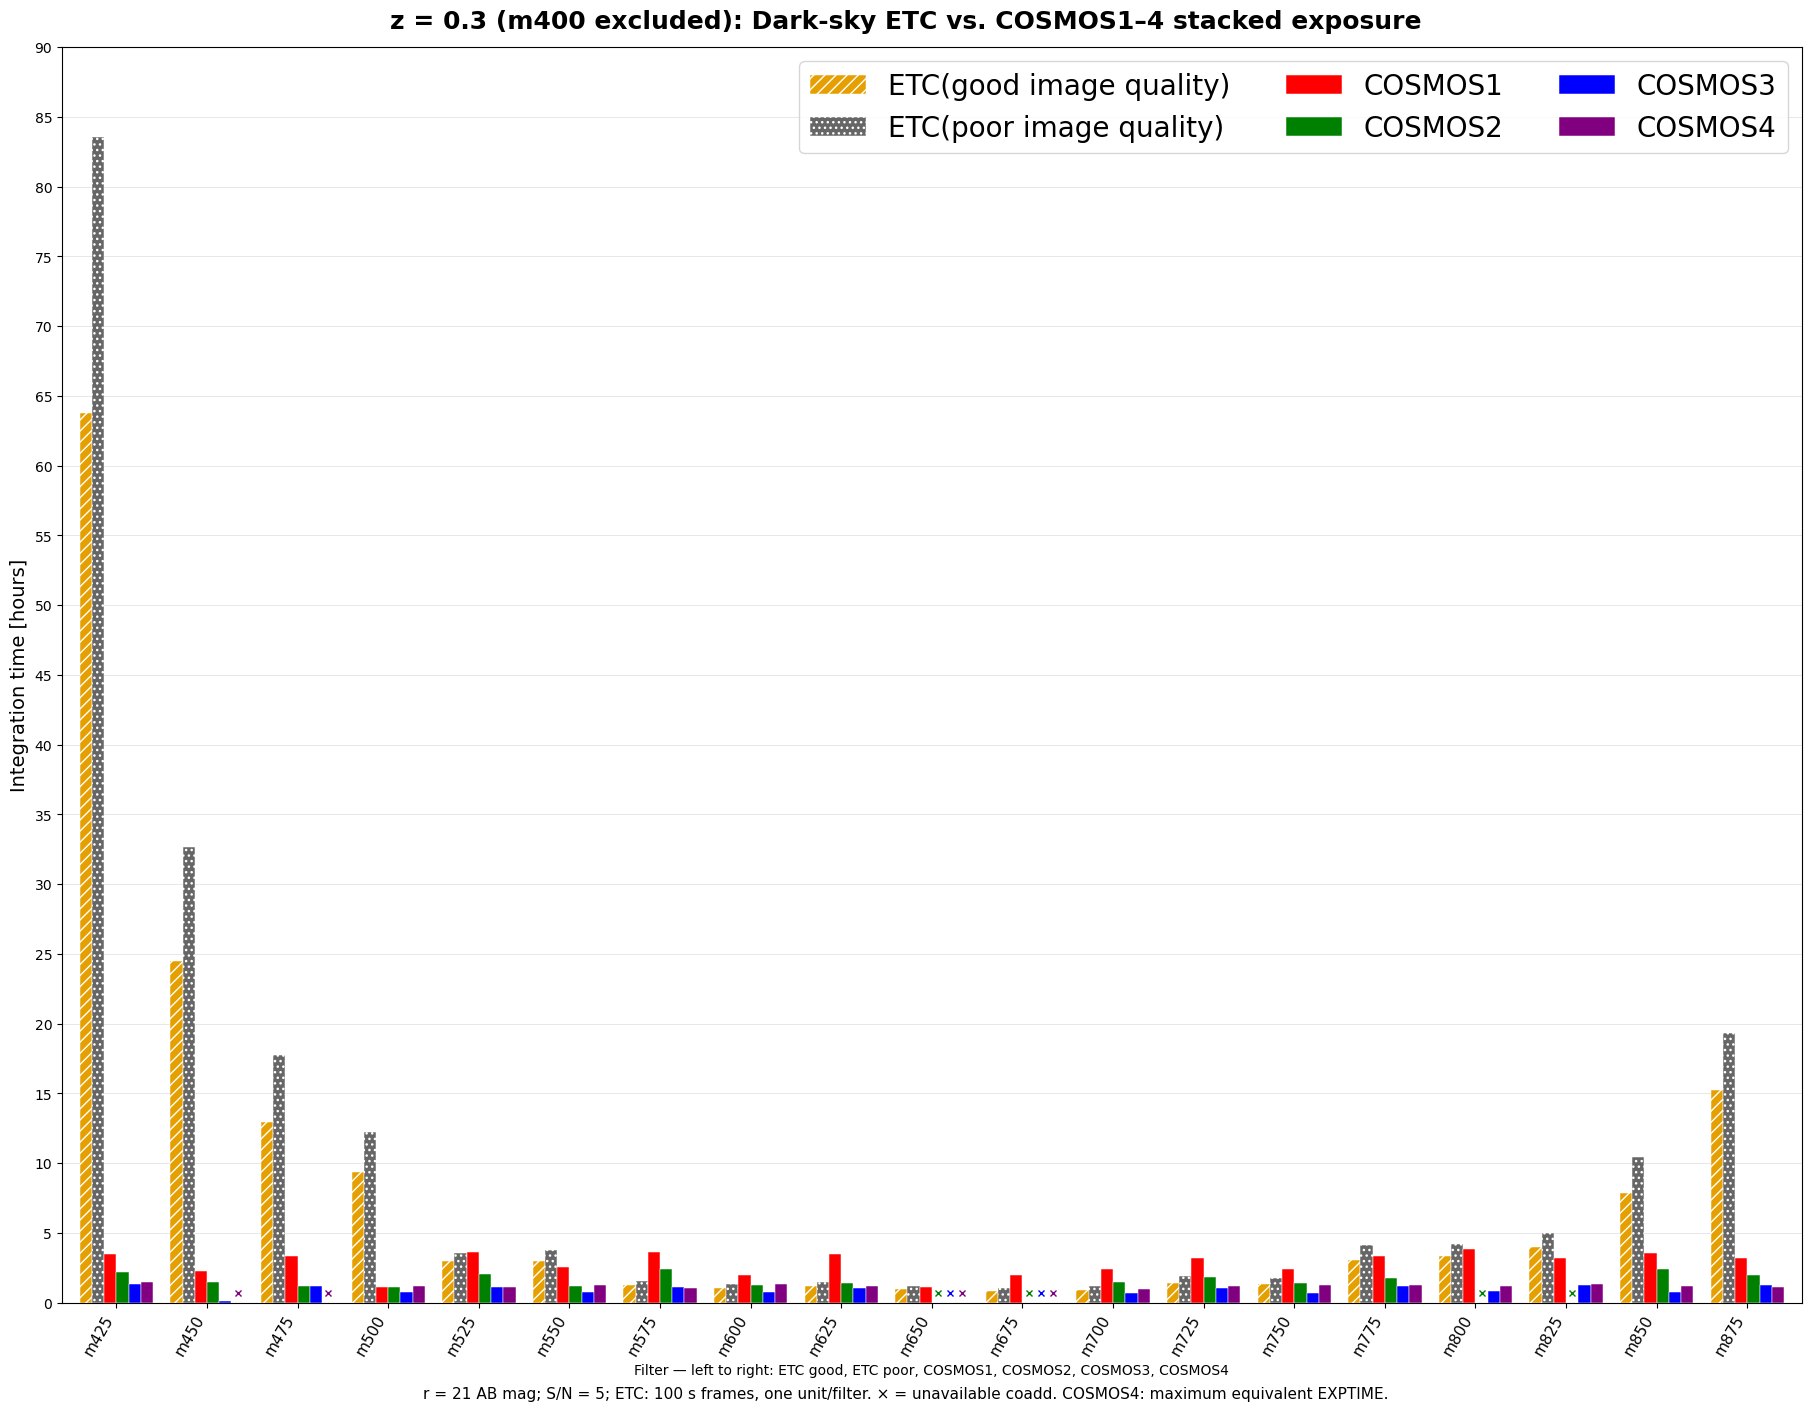

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/etc_z0.3_dark_good_poor_comparison_without_m400.png


In [13]:
# A separate display-only selection preserves the full-band plot and tables.
ETC_Z03_NO_M400_FIG_PATH = plot_etc_grouped_bars(
    ETC_Z03_ROUNDED_SECONDS, 'z = 0.3 (m400 excluded)',
    'etc_z0.3_dark_good_poor_comparison_without_m400.png',
    excluded_bands=('m400',))


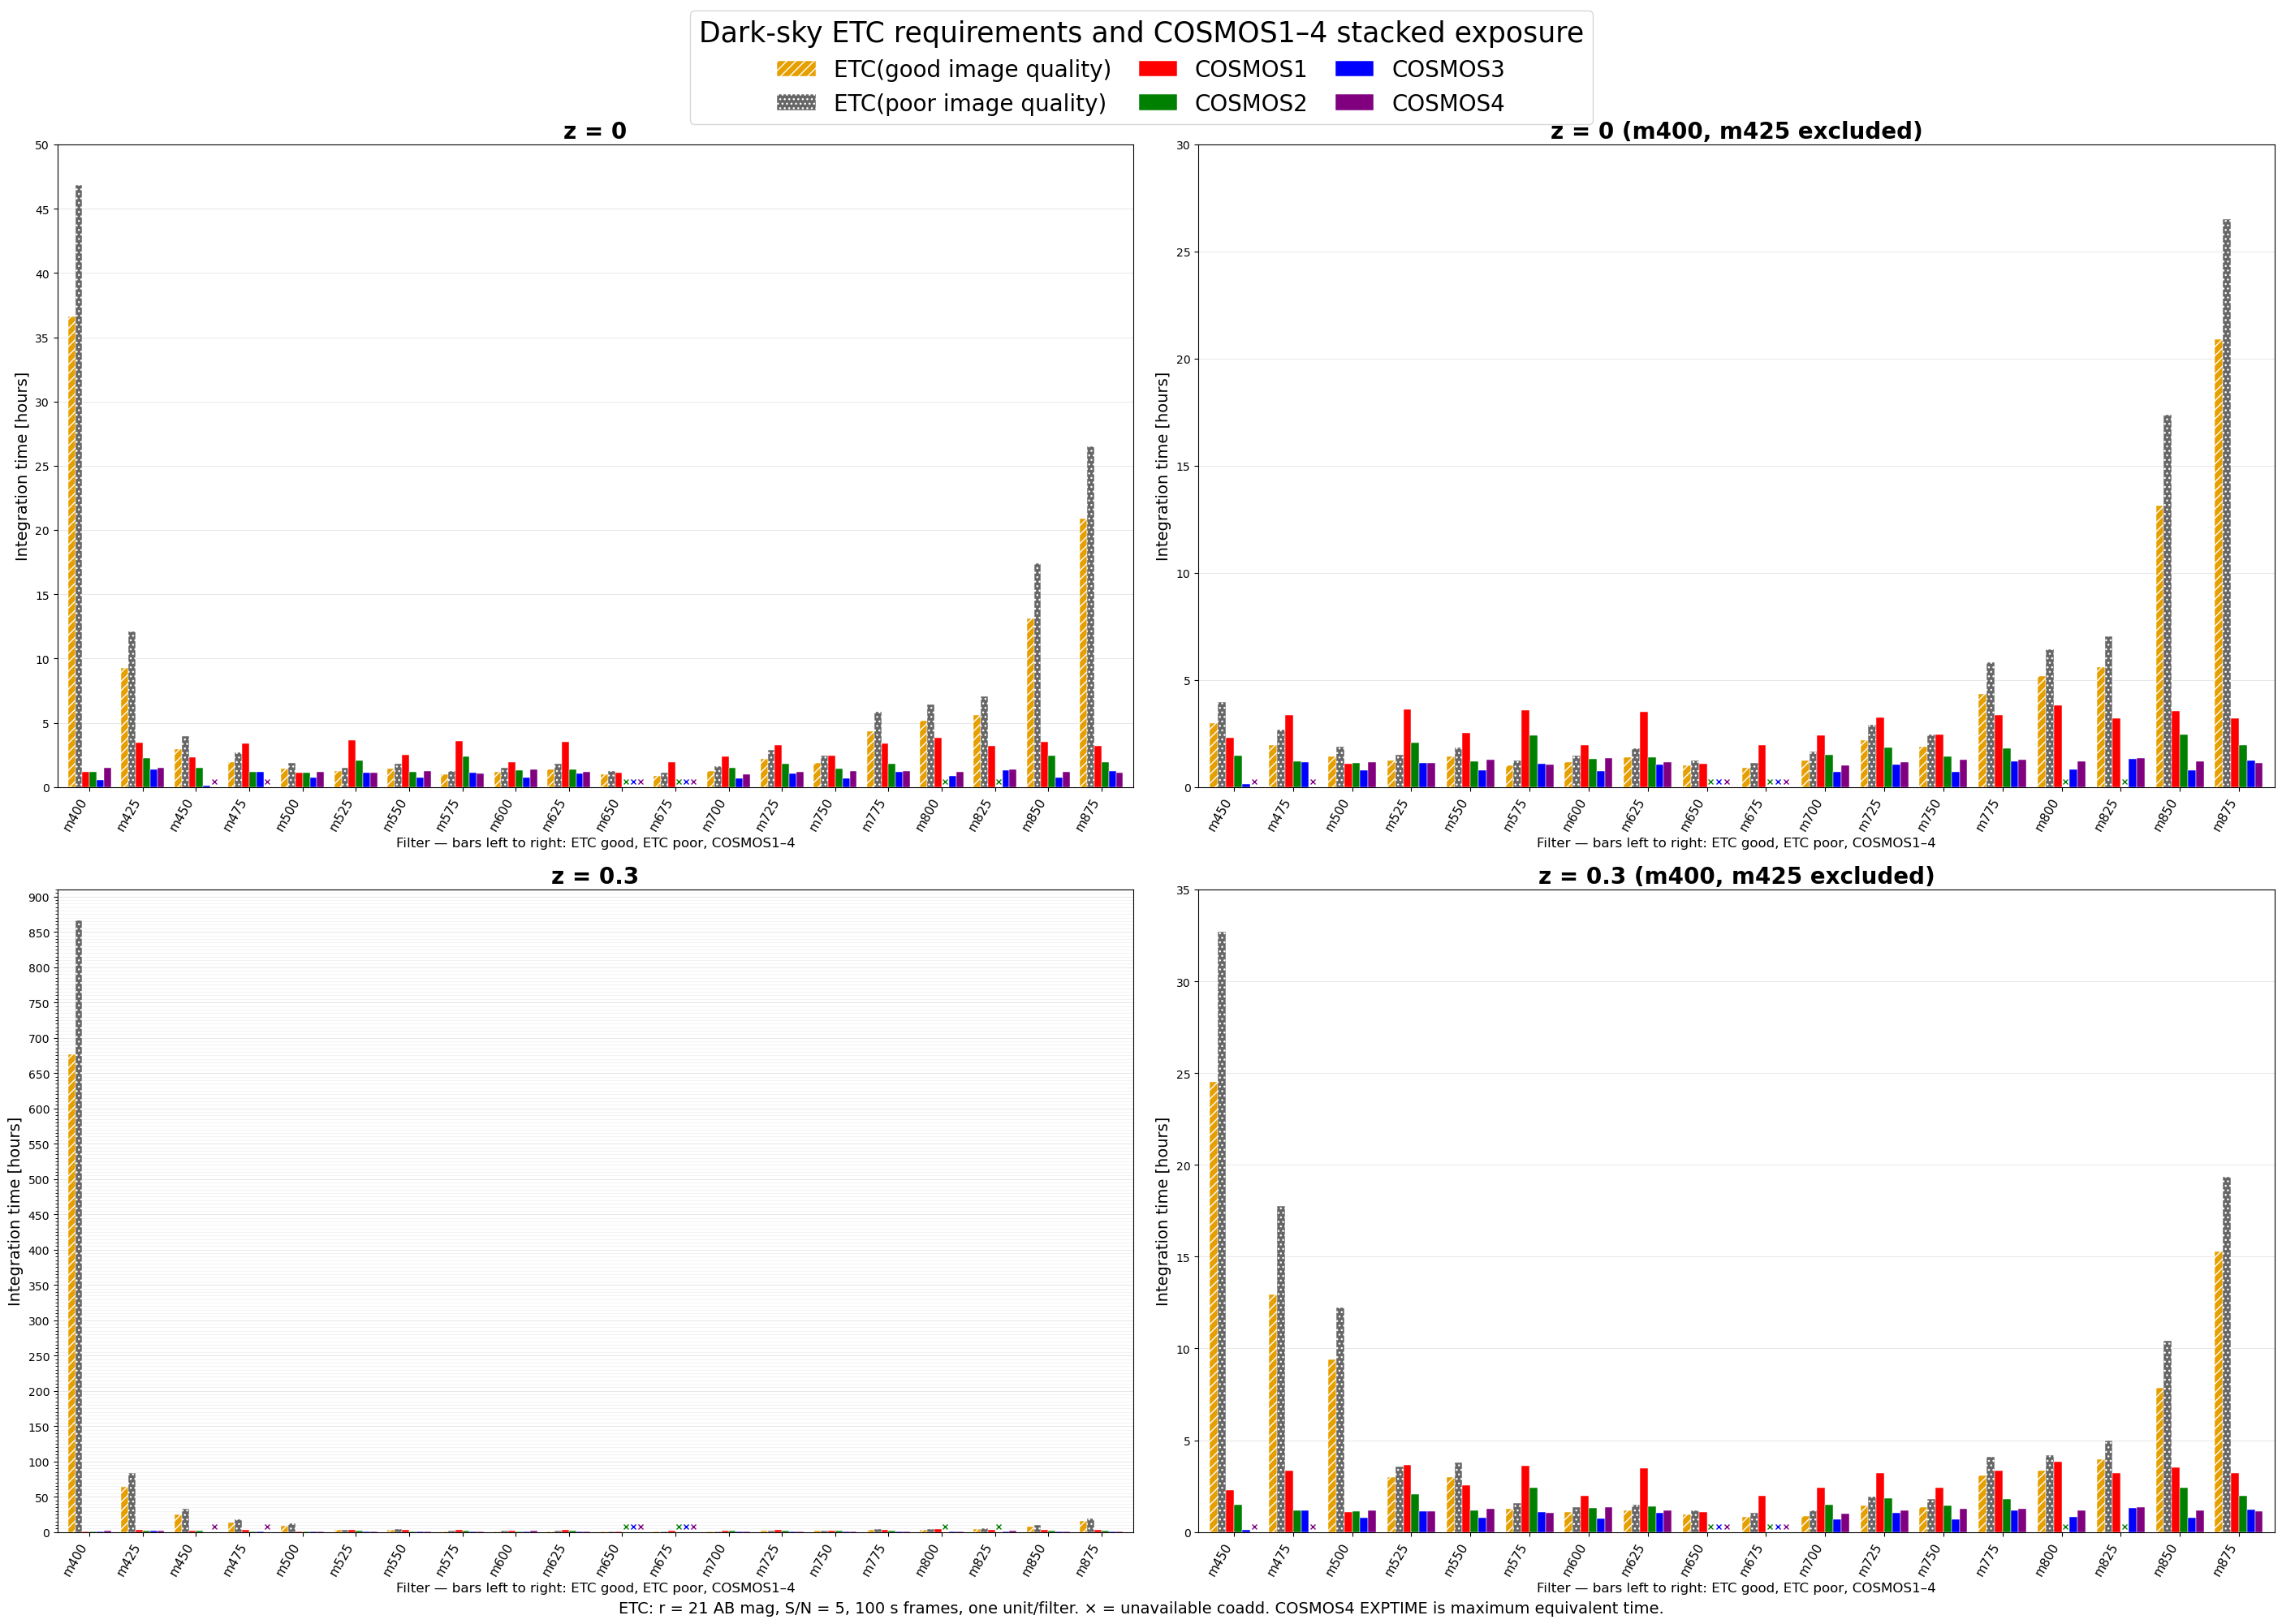

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/etc_z0_z0.3_four_panel_comparison.png


In [14]:
# Put all four target/band selections in one 2 × 2 figure for direct review.
from matplotlib.ticker import MultipleLocator

ETC_COMPOSITE_CASES = [
    ('z = 0', ETC_ROUNDED_SECONDS, ()),
    ('z = 0 (m400, m425 excluded)', ETC_ROUNDED_SECONDS, ('m400', 'm425')),
    ('z = 0.3', ETC_Z03_ROUNDED_SECONDS, ()),
    ('z = 0.3 (m400, m425 excluded)', ETC_Z03_ROUNDED_SECONDS, ('m400', 'm425')),
]
ETC_COMPOSITE_SERIES = [
    ('ETC(good image quality)', 'Dark / Good', '#E69F00', '///'),
    ('ETC(poor image quality)', 'Dark / Poor', '#666666', '...'),
] + [(f'COSMOS{field}', field, ETC_FIELD_COLORS[field], None)
     for field in ETC_FIELDS]

fig, axes = plt.subplots(2, 2, figsize=(28, 20), layout='constrained')
for ax, (title, rounded, excluded) in zip(axes.flat, ETC_COMPOSITE_CASES):
    selected = np.array([band not in excluded for band in ETC_BANDS])
    plot_bands = np.asarray(ETC_BANDS)[selected]
    x = np.arange(len(plot_bands))
    width = 0.135
    for index, (label, source, color, hatch) in enumerate(ETC_COMPOSITE_SERIES):
        seconds = (rounded[source] if isinstance(source, str)
                   else ETC_COSMOS_SECONDS[source])[selected]
        positions = x + (index - 2.5) * width
        available = np.isfinite(seconds)
        bars = ax.bar(positions[available], seconds[available]/3600,
                      width=width, color=color, hatch=hatch,
                      edgecolor='white', linewidth=0.35, label=label, zorder=3)
        if np.any(~available):
            ax.plot(positions[~available], np.full(np.sum(~available), 0.008),
                    linestyle='none', marker='x', color=color, markersize=5,
                    transform=ax.get_xaxis_transform(), clip_on=False, zorder=5)
    maximum_hours = max(
        np.nanmax((rounded[source] if isinstance(source, str)
                   else ETC_COSMOS_SECONDS[source])[selected])/3600
        for _, source, _, _ in ETC_COMPOSITE_SERIES)
    upper_hours = np.ceil(maximum_hours * 1.05 / 5) * 5
    ax.set_ylim(0, upper_hours)
    ax.set_xlim(-0.6, len(x)-0.4)
    ax.set_xticks(x, plot_bands, rotation=60, ha='right', fontsize=11)
    ax.set_ylabel('Integration time [hours]', fontsize=14)
    ax.set_title(title, fontsize=20, fontweight='bold')
    ax.set_axisbelow(True)
    major_spacing = 50 if upper_hours > 150 else 5
    ax.yaxis.set_major_locator(MultipleLocator(major_spacing))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.grid(axis='y', which='major', alpha=0.3, linewidth=0.7)
    ax.grid(axis='y', which='minor', alpha=0.2, linewidth=0.5)
    ax.set_xlabel('Filter — bars left to right: ETC good, ETC poor, COSMOS1–4', fontsize=12)

# Share one large legend so the four panels retain their plotting area.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=3, fontsize=20,
           title='Dark-sky ETC requirements and COSMOS1–4 stacked exposure',
           title_fontsize=25, frameon=True, columnspacing=1.2, handlelength=1.7)
fig.supxlabel('ETC: r = 21 AB mag, S/N = 5, 100 s frames, one unit/filter. '
              '× = unavailable coadd. COSMOS4 EXPTIME is maximum equivalent time.',
              fontsize=14)
ETC_COMPOSITE_FIG_PATH = ETC_REPORT_DIR / 'etc_z0_z0.3_four_panel_comparison.png'
fig.savefig(ETC_COMPOSITE_FIG_PATH, dpi=180)
plt.show()
print(f'Saved {ETC_COMPOSITE_FIG_PATH}')


## Matched COSMOS1–4 sources: flux_radius (r50) histograms

Use `output/singlephot/master_catalog_MatchedWithFianlcat_OverallCosmosField.fits`, which has one row per `finalcat_idx` with a 7DT match in at least one COSMOS field. Preserve this reference-row identity; the original FINALCAT ID string need not be unique.

For each source **and each medium-band filter**, use the largest finite, positive `flux_radius` among matched COSMOS1–4 measurements. The column unit is **pixels**. Require the field's `7dt_cosmos{field}_matched` flag; exclude nonfinite, masked, zero, and negative radii. Apply no magnitude, morphology, redshift, S/N, or successful-band-count cut.

The main figure shows 20 per-band histograms after this field-overlap reduction. A separate overview uses the largest radius across the available bands as well, giving exactly one value per source. This additional maximum across bands is explicit: it is not a single-filter size. These observed radii include PSF/seeing and measurement effects and have not been PSF-deconvolved.

Plot both the full overview range and a central-range view. Per-band panels use a common central-range limit; each panel reports how many values lie above that plotted limit. No large radii are removed from the statistics.


In [15]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from IPython.display import display, Markdown

# Resolve paths independently of all earlier planning/ETC cells.
R50_ROOT = Path.cwd().resolve()
if not (R50_ROOT / 'COSMOS_data').is_dir():
    R50_ROOT = R50_ROOT.parent
R50_INPUT = R50_ROOT / 'output' / 'singlephot' / 'master_catalog_MatchedWithFianlcat_OverallCosmosField.fits'
R50_OUTPUT = R50_ROOT / 'Report' / '7DT Observation Proposal'
R50_OUTPUT.mkdir(parents=True, exist_ok=True)
R50_CATALOG = Table.read(R50_INPUT, hdu=1)
R50_BANDS = tuple(f'm{wavelength}' for wavelength in range(400, 900, 25))
R50_FIELDS = (1, 2, 3, 4)
R50_REFERENCE_IDS = np.asarray(R50_CATALOG['finalcat_idx'], dtype=np.int64)
if len(np.unique(R50_REFERENCE_IDS)) != len(R50_REFERENCE_IDS):
    raise ValueError('Expected one row per finalcat_idx in the combined matched catalog')

# Keep the filter and field axes separate: first reduce only the four field
# measurements of the SAME filter. Each source is counted at most once per band.
R50_MAX_BY_BAND_PIX = np.full((len(R50_CATALOG), len(R50_BANDS)), np.nan)
R50_N_FIELDS_BY_BAND = np.zeros_like(R50_MAX_BY_BAND_PIX, dtype=int)
R50_FIELD_OF_MAX = np.zeros_like(R50_N_FIELDS_BY_BAND)
for band_index, band in enumerate(R50_BANDS):
    field_radii = np.full((len(R50_CATALOG), len(R50_FIELDS)), np.nan)
    for field_index, field in enumerate(R50_FIELDS):
        radius_name = f'7dt_cosmos{field}_{band}_flux_radius'
        # The combined catalog contains placeholder columns for some missing
        # field/band pairs; missing columns or invalid values are not zeros.
        if radius_name not in R50_CATALOG.colnames:
            continue
        radius_column = R50_CATALOG[radius_name]
        if str(radius_column.unit) != 'pix':
            raise ValueError(f'Unexpected radius unit for {radius_name}: {radius_column.unit}')
        radius = np.asarray(np.ma.filled(radius_column, np.nan), dtype=float)
        matched = np.asarray(np.ma.filled(R50_CATALOG[f'7dt_cosmos{field}_matched'], False), dtype=bool)
        valid = matched & np.isfinite(radius) & (radius > 0)
        field_radii[valid, field_index] = radius[valid]
    finite = np.isfinite(field_radii)
    R50_N_FIELDS_BY_BAND[:, band_index] = finite.sum(axis=1)
    has_radius = finite.any(axis=1)
    # Use -inf only inside the reduction to avoid all-NaN warnings. Rows
    # without any valid radius remain NaN, and retain field-of-max = 0.
    comparable = np.where(finite, field_radii, -np.inf)
    R50_MAX_BY_BAND_PIX[has_radius, band_index] = comparable[has_radius].max(axis=1)
    largest_field_index = comparable[has_radius].argmax(axis=1)
    R50_FIELD_OF_MAX[has_radius, band_index] = np.asarray(R50_FIELDS)[largest_field_index]

# An additional across-band maximum provides one overall histogram entry
# per reference source, rather than pooling 20 correlated measurements.
radius_available = np.isfinite(R50_MAX_BY_BAND_PIX)
R50_HAS_RADIUS = radius_available.any(axis=1)
R50_SOURCE_MAX_PIX = np.full(len(R50_CATALOG), np.nan)
R50_SOURCE_MAX_PIX[R50_HAS_RADIUS] = np.where(
    radius_available, R50_MAX_BY_BAND_PIX, -np.inf
)[R50_HAS_RADIUS].max(axis=1)

# Obtain angular units from actual image WCS rather than assuming a pixel
# scale. A single secondary axis is meaningful only when these scales agree.
R50_SCALES = []
for field in R50_FIELDS:
    for band in R50_BANDS:
        images = list((R50_ROOT / 'COSMOS_data' / f'COSMOS{field}').glob(f'*_{band}_*.com.fits'))
        if not images:
            continue
        if len(images) != 1:
            raise ValueError(f'Expected one coadd for COSMOS{field}/{band}')
        scale = proj_plane_pixel_scales(WCS(fits.getheader(images[0])).celestial) * 3600
        R50_SCALES.extend(np.asarray(scale, dtype=float).tolist())
R50_PIXEL_SCALE_ARCSEC = float(np.median(R50_SCALES))
if not np.allclose(R50_SCALES, R50_PIXEL_SCALE_ARCSEC, rtol=1e-5, atol=1e-8):
    raise ValueError('Pixel scales differ; compare radii in angular units before taking maxima')

R50_VALID_SOURCE_VALUES = R50_SOURCE_MAX_PIX[R50_HAS_RADIUS]
if not len(R50_VALID_SOURCE_VALUES):
    raise ValueError('No valid matched-source flux_radius measurements')
R50_SOURCE_QUANTILES = np.percentile(R50_VALID_SOURCE_VALUES, [50, 90, 95, 99, 100])
print(f'Combined matched catalog: {len(R50_CATALOG):,} unique finalcat_idx rows')
print(f'Sources with any valid r50: {R50_HAS_RADIUS.sum():,}; missing: {(~R50_HAS_RADIUS).sum():,}')
print(f'Common WCS pixel scale: {R50_PIXEL_SCALE_ARCSEC:.6f} arcsec/pixel')
print('No magnitude, morphology, redshift, or S/N cut.')
print('Overview: maximum over fields AND bands; per-band panels: maximum over fields only.')
for label, value in zip(('median', 'P90', 'P95', 'P99', 'maximum'), R50_SOURCE_QUANTILES):
    print(f'One-per-source r50 {label}: {value:.4f} pix = {value*R50_PIXEL_SCALE_ARCSEC:.4f} arcsec')

r50_summary_rows = []
for band_index, band in enumerate(R50_BANDS):
    values = R50_MAX_BY_BAND_PIX[:, band_index]
    good = np.isfinite(values)
    radius = values[good]
    r50_summary_rows.append((band, len(radius),
        int(np.sum(R50_N_FIELDS_BY_BAND[:, band_index] >= 2)),
        float(np.median(radius)), float(np.percentile(radius, 90)),
        float(np.max(radius))))
R50_SUMMARY = Table(rows=r50_summary_rows, names=[
    'Band', 'N_unique_sources', 'N_with_multiple_fields', 'Median_r50_pix',
    'P90_r50_pix', 'Max_r50_pix'])
for name in R50_SUMMARY.colnames[3:]:
    R50_SUMMARY[name].info.format = '.3f'
R50_SUMMARY.pprint(max_lines=-1, max_width=-1)


Combined matched catalog: 10,217 unique finalcat_idx rows
Sources with any valid r50: 10,217; missing: 0
Common WCS pixel scale: 0.505000 arcsec/pixel
No magnitude, morphology, redshift, or S/N cut.
Overview: maximum over fields AND bands; per-band panels: maximum over fields only.
One-per-source r50 median: 4.1951 pix = 2.1185 arcsec
One-per-source r50 P90: 6.4013 pix = 3.2326 arcsec
One-per-source r50 P95: 7.6580 pix = 3.8673 arcsec
One-per-source r50 P99: 12.6563 pix = 6.3914 arcsec
One-per-source r50 maximum: 55.0361 pix = 27.7932 arcsec
Band N_unique_sources N_with_multiple_fields Median_r50_pix P90_r50_pix Max_r50_pix
---- ---------------- ---------------------- -------------- ----------- -----------
m400             1831                    605          3.276       5.245      41.902
m425             2204                    613          3.685       5.461      41.877
m450             3034                    319          3.401       5.338      53.056
m475             5997           

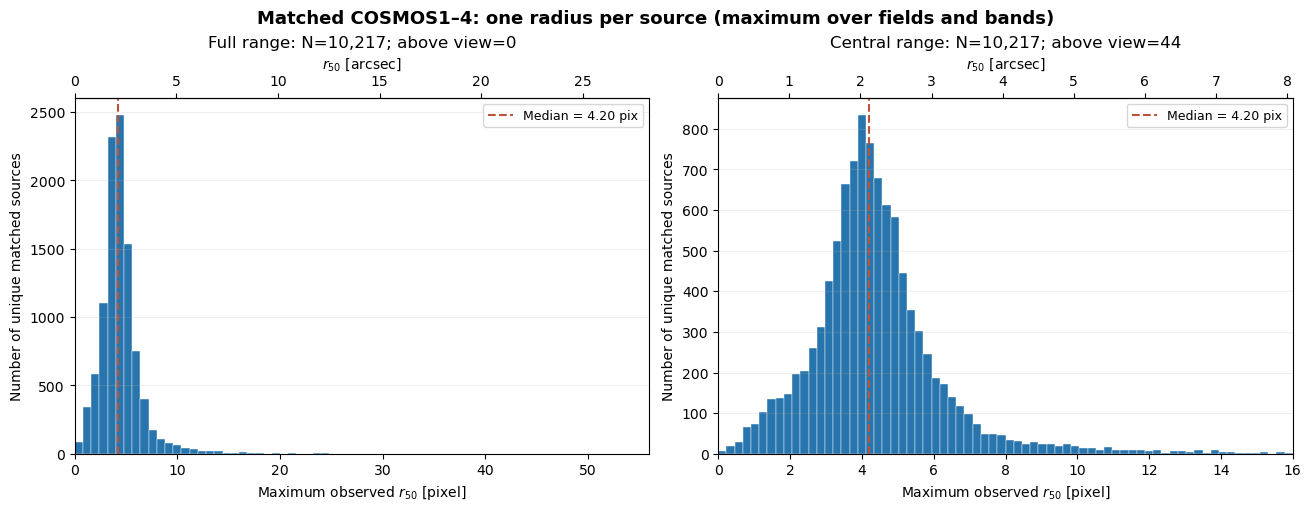

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_cosmos1-4_r50_source_max_histogram.png


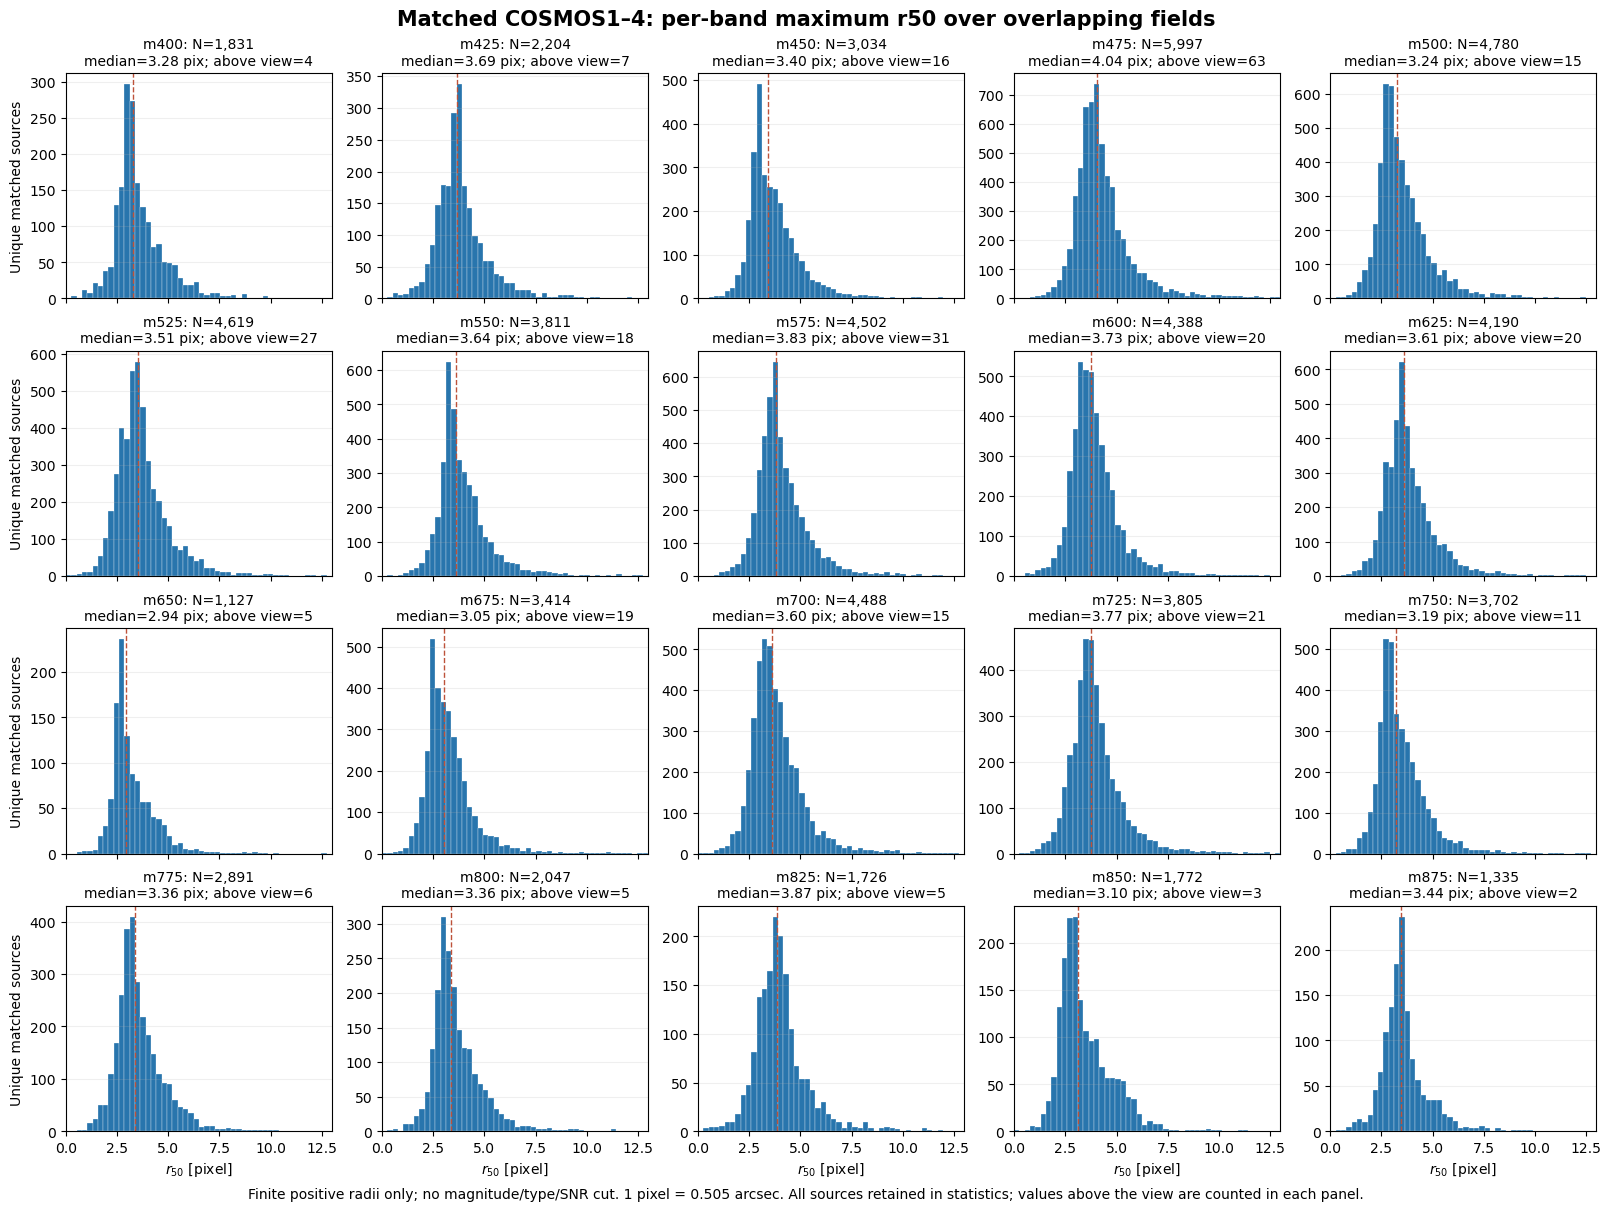

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_cosmos1-4_r50_per_band_histograms.png


In [16]:
# Show all large-radius sources in the full-range panel; the companion
# central view makes the bulk of the population visible on a linear count axis.
r50_values = R50_VALID_SOURCE_VALUES
r50_full_max = float(np.ceil(r50_values.max()))
r50_zoom_max = float(np.ceil(np.percentile(r50_values, 99.5)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for axis, upper, label in zip(axes, (r50_full_max, r50_zoom_max), ('Full range', 'Central range')):
    edges = np.linspace(0, upper, 71)
    axis.hist(r50_values, bins=edges, color='#2875AD', edgecolor='white', linewidth=0.3)
    axis.axvline(np.median(r50_values), color='#BD523A', linestyle='--',
                 label=f'Median = {np.median(r50_values):.2f} pix')
    overflow = int(np.sum(r50_values > upper))
    axis.set_xlim(0, upper)
    axis.set_xlabel(r'Maximum observed $r_{50}$ [pixel]')
    axis.set_ylabel('Number of unique matched sources')
    axis.set_title(f'{label}: N={len(r50_values):,}; above view={overflow}')
    axis.grid(axis='y', alpha=0.2)
    axis.legend(fontsize=9)
    # Angular axis is a unit conversion of the observed pixel radius.
    secondary = axis.secondary_xaxis('top', functions=(
        lambda x: x * R50_PIXEL_SCALE_ARCSEC,
        lambda x: x / R50_PIXEL_SCALE_ARCSEC))
    secondary.set_xlabel(r'$r_{50}$ [arcsec]')
fig.suptitle('Matched COSMOS1–4: one radius per source (maximum over fields and bands)',
             fontsize=13, fontweight='bold')
R50_OVERVIEW_PATH = R50_OUTPUT / 'matched_cosmos1-4_r50_source_max_histogram.png'
fig.savefig(R50_OVERVIEW_PATH, dpi=180)
plt.show()
print(f'Saved {R50_OVERVIEW_PATH}')

# Use common bins and x limits for the 20 filters. Report overflow rather
# than silently interpreting the central-range view as the complete sample.
r50_band_values = R50_MAX_BY_BAND_PIX[np.isfinite(R50_MAX_BY_BAND_PIX)]
R50_BAND_VIEW_MAX = float(np.ceil(np.percentile(r50_band_values, 99.5)))
r50_band_edges = np.linspace(0, R50_BAND_VIEW_MAX, 51)
fig, axes = plt.subplots(4, 5, figsize=(16, 12), sharex=True, layout='constrained')
for band_index, (axis, band) in enumerate(zip(axes.flat, R50_BANDS)):
    values = R50_MAX_BY_BAND_PIX[:, band_index]
    values = values[np.isfinite(values)]
    axis.hist(values, bins=r50_band_edges, color='#2875AD', edgecolor='white', linewidth=0.2)
    axis.axvline(np.median(values), color='#BD523A', linestyle='--', linewidth=1)
    overflow = int(np.sum(values > R50_BAND_VIEW_MAX))
    axis.set_title(f'{band}: N={len(values):,}\nmedian={np.median(values):.2f} pix; above view={overflow}', fontsize=10)
    axis.set_xlim(0, R50_BAND_VIEW_MAX)
    axis.grid(axis='y', alpha=0.2)
    if band_index % 5 == 0:
        axis.set_ylabel('Unique matched sources')
    if band_index >= 15:
        axis.set_xlabel(r'$r_{50}$ [pixel]')
fig.suptitle('Matched COSMOS1–4: per-band maximum r50 over overlapping fields',
             fontsize=15, fontweight='bold')
fig.supxlabel(f'Finite positive radii only; no magnitude/type/SNR cut. '
              f'1 pixel = {R50_PIXEL_SCALE_ARCSEC:.3f} arcsec. '
              'All sources retained in statistics; values above the view are counted in each panel.', fontsize=10)
R50_BANDS_PATH = R50_OUTPUT / 'matched_cosmos1-4_r50_per_band_histograms.png'
fig.savefig(R50_BANDS_PATH, dpi=180)
plt.show()
print(f'Saved {R50_BANDS_PATH}')


In [17]:
# Build interpretation from the currently loaded catalog rather than
# recording a static sample size or size statistic that could become stale.
r50_median, r50_p90, r50_p95, r50_p99, r50_max = R50_SOURCE_QUANTILES
r50_multi = int(np.sum(np.any(R50_N_FIELDS_BY_BAND >= 2, axis=1)))
display(Markdown(
    '### 결과\n\n'
    f'- 통합 matched 카탈로그 **{len(R50_CATALOG):,}개 천체** 중 '
    f'**{R50_HAS_RADIUS.sum():,}개**에 유효한 `flux_radius`가 있습니다.\n'
    f'- 동일 필터에 여러 COSMOS 측정값이 있는 천체는 **{r50_multi:,}개**이며, '
    '필터마다 그중 가장 큰 반지름을 사용했습니다.\n'
    '- 20개 패널은 **필터별로 천체당 한 번** 집계합니다. '
    '전체 요약 그림은 필터들 중에서도 최대값을 택하여 **천체당 한 번** 집계합니다.\n'
    f'- 전체 요약 분포 중앙값은 **{r50_median:.3f} pixel '
    f'({r50_median*R50_PIXEL_SCALE_ARCSEC:.3f} arcsec)**, '
    f'90백분위는 **{r50_p90:.3f} pixel**, '
    f'최대값은 **{r50_max:.3f} pixel**입니다.\n'
    '- 밝기와 별/은하 종류에 따른 선택을 추가하지 않았습니다. '
    '이는 관측된 반광반지름이며 PSF 보정을 거친 은하 고유 크기는 아닙니다. '
    '최댓값 선택은 큰 측정값과 이상값의 영향을 받을 수 있습니다.'
))


### 결과

- 통합 matched 카탈로그 **10,217개 천체** 중 **10,217개**에 유효한 `flux_radius`가 있습니다.
- 동일 필터에 여러 COSMOS 측정값이 있는 천체는 **2,911개**이며, 필터마다 그중 가장 큰 반지름을 사용했습니다.
- 20개 패널은 **필터별로 천체당 한 번** 집계합니다. 전체 요약 그림은 필터들 중에서도 최대값을 택하여 **천체당 한 번** 집계합니다.
- 전체 요약 분포 중앙값은 **4.195 pixel (2.119 arcsec)**, 90백분위는 **6.401 pixel**, 최대값은 **55.036 pixel**입니다.
- 밝기와 별/은하 종류에 따른 선택을 추가하지 않았습니다. 이는 관측된 반광반지름이며 PSF 보정을 거친 은하 고유 크기는 아닙니다. 최댓값 선택은 큰 측정값과 이상값의 영향을 받을 수 있습니다.

## FINALCAT RM 20–22 mag: matched-source r50 statistics

Select matched sources with finite, positive FINALCAT `RM` between **20 and 22 mag, inclusive**. This is an explicit magnitude interval, not a percentile cut. Report the selected count and its share of the valid-RM parent sample.

Reuse the previous section's radii: for each source and filter, take the largest valid positive `flux_radius` over matched COSMOS1–4 fields. Apply the RM interval once at the source level, before making all 20 band histograms. The overview takes another maximum across bands to give one value per selected source. No extra morphology, S/N, redshift, or band-count cut is applied. Radius units, PSF effects, and central-range overflow reporting are the same as above.


In [18]:
# The preceding matched-source r50 section supplies R50_CATALOG and the
# per-filter maximum across COSMOS fields, in the same finalcat_idx row order.
R50_RM = np.asarray(np.ma.filled(R50_CATALOG['finalcat_RM'], np.nan), dtype=float)
R50_VALID_RM = np.isfinite(R50_RM) & (R50_RM > 0)
if not np.any(R50_VALID_RM):
    raise ValueError('No finite positive FINALCAT RM magnitudes')
# Apply the requested inclusive RM magnitude window at source level.
R50_RM_LOWER = 20.0
R50_RM_UPPER = 22.0
R50_RM_WINDOW_MASK = R50_VALID_RM & (R50_RM >= R50_RM_LOWER) & (R50_RM <= R50_RM_UPPER)
R50_RM_WINDOW_SOURCE_IDS = R50_REFERENCE_IDS[R50_RM_WINDOW_MASK]
R50_RM_WINDOW_BAND_PIX = R50_MAX_BY_BAND_PIX[R50_RM_WINDOW_MASK]
R50_RM_WINDOW_SOURCE_MAX_PIX = R50_SOURCE_MAX_PIX[R50_RM_WINDOW_MASK]
R50_RM_WINDOW_VALUES = R50_RM_WINDOW_SOURCE_MAX_PIX[np.isfinite(R50_RM_WINDOW_SOURCE_MAX_PIX)]
R50_RM_WINDOW_N = int(R50_RM_WINDOW_MASK.sum())
R50_RM_WINDOW_FRACTION = float(R50_RM_WINDOW_N / R50_VALID_RM.sum())
print(f'Combined matched catalog: {len(R50_CATALOG):,} sources')
print(f'Finite positive RM: {R50_VALID_RM.sum():,}; invalid RM excluded: {(~R50_VALID_RM).sum():,}')
print(f'Inclusive RM interval: {R50_RM_LOWER:.1f} <= RM <= {R50_RM_UPPER:.1f} mag')
print(f'Selected sources: {R50_RM_WINDOW_N:,} / {R50_VALID_RM.sum():,} ({100*R50_RM_WINDOW_FRACTION:.4f}%)')
print(f'Selected RM range: {R50_RM[R50_RM_WINDOW_MASK].min():.6f} to {R50_RM[R50_RM_WINDOW_MASK].max():.6f} mag')
print(f'Selected sources with any valid r50: {len(R50_RM_WINDOW_VALUES):,}')

# Compare the interval with both the complete matched sample and the
# valid-RM parent, so missing RM values cannot silently alter the denominator.
overview_rows=[]
for label, mask in [('All matched', R50_HAS_RADIUS),
                    ('Valid-RM parent', R50_VALID_RM & R50_HAS_RADIUS),
                    ('RM 20-22 mag', R50_RM_WINDOW_MASK & R50_HAS_RADIUS)]:
    values=R50_SOURCE_MAX_PIX[mask]
    overview_rows.append((label,len(values),float(np.mean(values)),
        float(np.std(values,ddof=1)),float(np.median(values)),
        float(np.percentile(values,90)),float(np.percentile(values,95)),
        float(np.max(values)),float(np.median(values)*R50_PIXEL_SCALE_ARCSEC)))
R50_FAINT_OVERVIEW=Table(rows=overview_rows,names=[
    'Sample','N','Mean_pix','Std_pix','Median_pix','P90_pix','P95_pix',
    'Max_pix','Median_arcsec'])
for name in R50_FAINT_OVERVIEW.colnames[2:]:
    R50_FAINT_OVERVIEW[name].info.format='.3f'
print('\nOne value per source: maximum across fields and bands')
R50_FAINT_OVERVIEW.pprint(max_lines=-1,max_width=-1)

faint_band_rows=[]
for index,band in enumerate(R50_BANDS):
    values=R50_RM_WINDOW_BAND_PIX[:,index]
    values=values[np.isfinite(values)]
    parent=R50_MAX_BY_BAND_PIX[R50_VALID_RM,index]
    parent=parent[np.isfinite(parent)]
    if len(values):
        mean,std,median,p90,maximum=(float(np.mean(values)),
            float(np.std(values,ddof=1)) if len(values)>1 else np.nan,
            float(np.median(values)),float(np.percentile(values,90)),float(np.max(values)))
    else:
        mean=std=median=p90=maximum=np.nan
    faint_band_rows.append((band,len(values),
        int(np.sum(R50_N_FIELDS_BY_BAND[R50_RM_WINDOW_MASK,index]>=2)),
        mean,std,median,median*R50_PIXEL_SCALE_ARCSEC,p90,maximum,
        float(np.median(parent)) if len(parent) else np.nan))
R50_FAINT_SUMMARY=Table(rows=faint_band_rows,names=[
    'Band','N_faint','N_multiple_fields','Mean_pix','Std_pix','Median_pix',
    'Median_arcsec','P90_pix','Max_pix','Parent_median_pix'])
for name in R50_FAINT_SUMMARY.colnames[3:]:
    R50_FAINT_SUMMARY[name].info.format='.3f'
print('\nPer-band statistics: maximum across COSMOS fields only')
R50_FAINT_SUMMARY.pprint(max_lines=-1,max_width=-1)


Combined matched catalog: 10,217 sources
Finite positive RM: 9,594; invalid RM excluded: 623
Inclusive RM interval: 20.0 <= RM <= 22.0 mag
Selected sources: 5,871 / 9,594 (61.1945%)
Selected RM range: 20.000946 to 21.998966 mag
Selected sources with any valid r50: 5,871

One value per source: maximum across fields and bands
     Sample       N   Mean_pix Std_pix Median_pix P90_pix P95_pix Max_pix Median_arcsec
--------------- ----- -------- ------- ---------- ------- ------- ------- -------------
    All matched 10217    4.473   2.343      4.195   6.401   7.658  55.036         2.119
Valid-RM parent  9594    4.448   2.276      4.192   6.418   7.674  55.036         2.117
   RM 20-22 mag  5871    4.106   1.582      3.907   5.729   6.753  18.572         1.973

Per-band statistics: maximum across COSMOS fields only
Band N_faint N_multiple_fields Mean_pix Std_pix Median_pix Median_arcsec P90_pix Max_pix Parent_median_pix
---- ------- ----------------- -------- ------- ---------- ------------

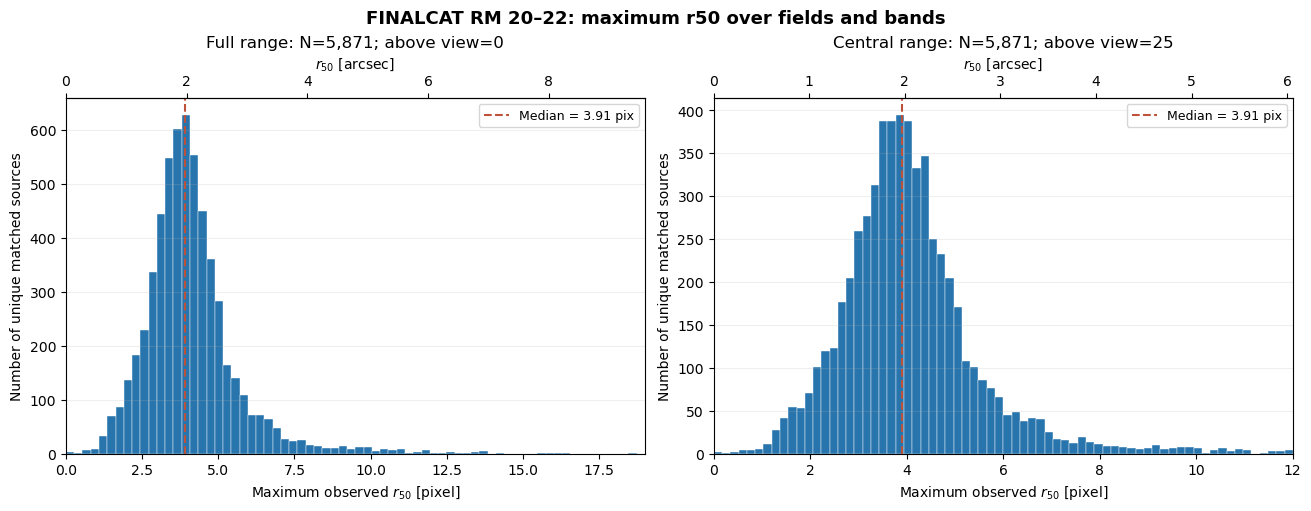

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_cosmos1-4_RM20-22_r50_source_max_histogram.png


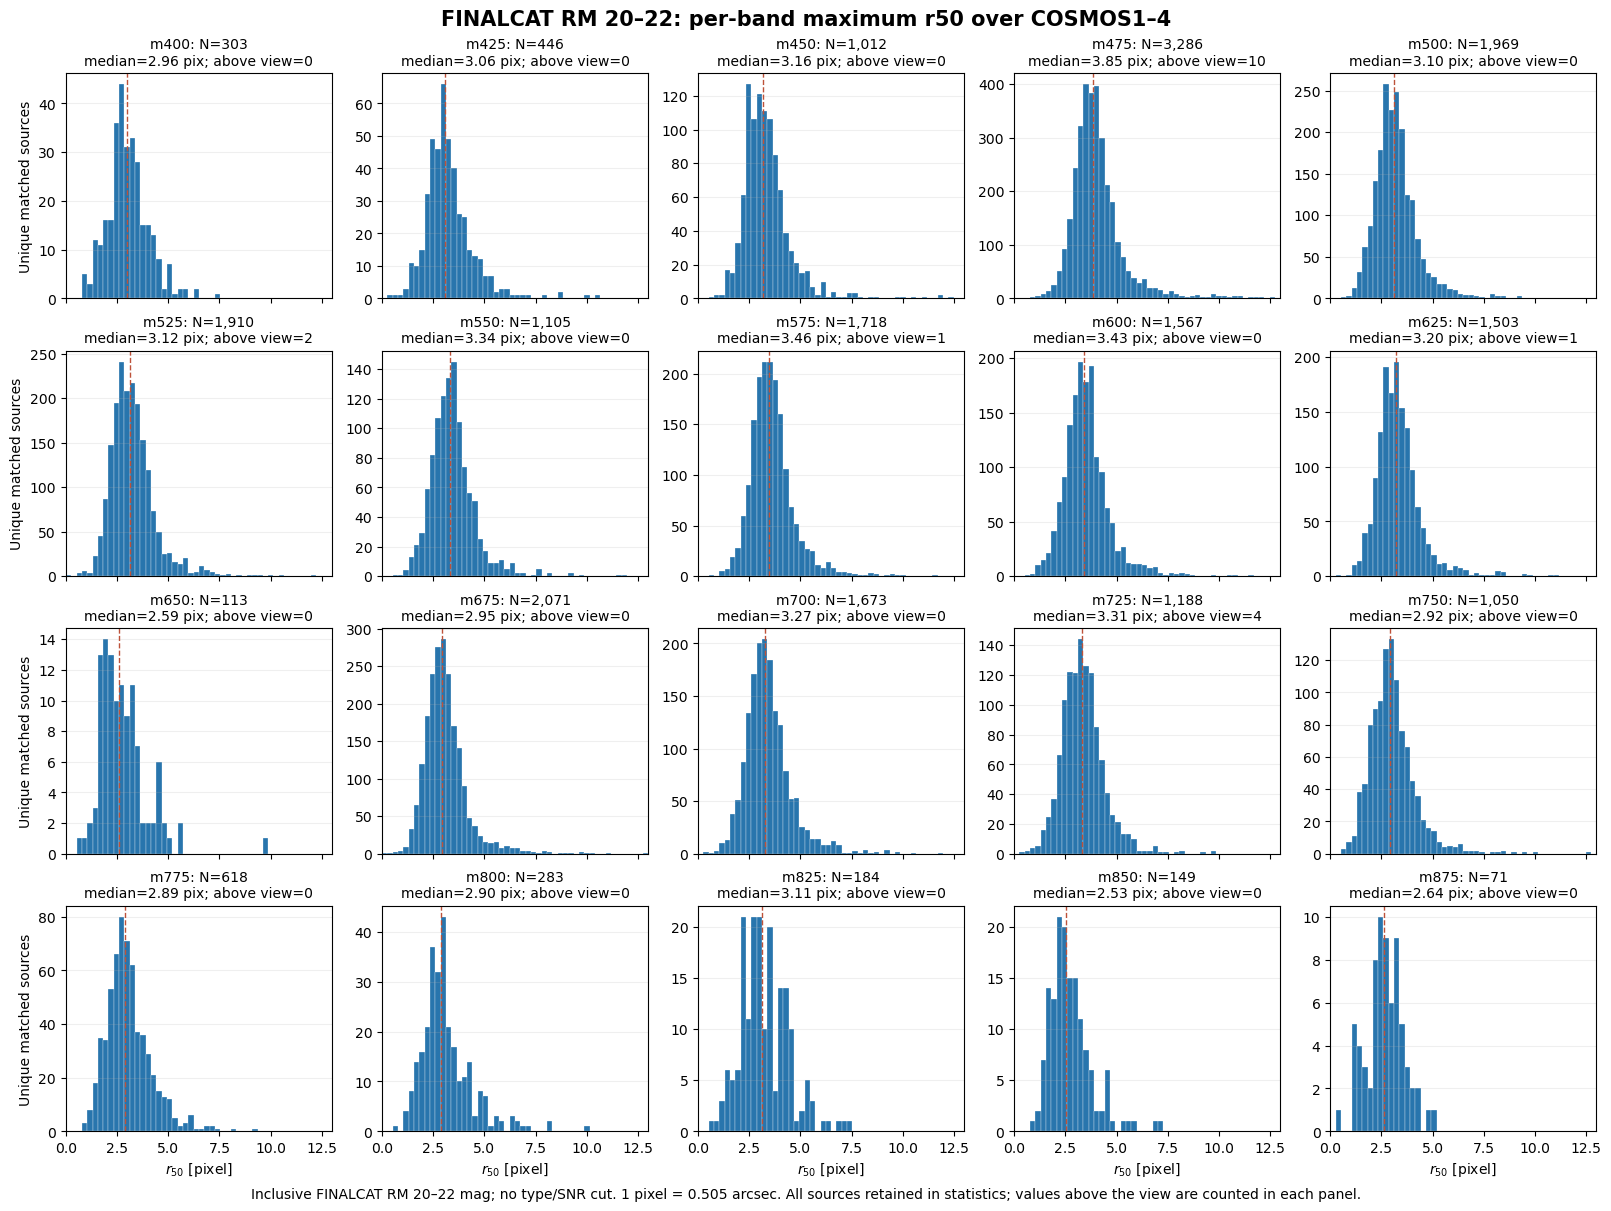

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_cosmos1-4_RM20-22_r50_per_band_histograms.png


In [19]:
# Show all large-radius sources in the full-range panel; the companion
# central view makes the bulk of the population visible on a linear count axis.
r50_values = R50_RM_WINDOW_VALUES
r50_full_max = float(np.ceil(r50_values.max()))
r50_zoom_max = float(np.ceil(np.percentile(r50_values, 99.5)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for axis, upper, label in zip(axes, (r50_full_max, r50_zoom_max), ('Full range', 'Central range')):
    edges = np.linspace(0, upper, 71)
    axis.hist(r50_values, bins=edges, color='#2875AD', edgecolor='white', linewidth=0.3)
    axis.axvline(np.median(r50_values), color='#BD523A', linestyle='--',
                 label=f'Median = {np.median(r50_values):.2f} pix')
    overflow = int(np.sum(r50_values > upper))
    axis.set_xlim(0, upper)
    axis.set_xlabel(r'Maximum observed $r_{50}$ [pixel]')
    axis.set_ylabel('Number of unique matched sources')
    axis.set_title(f'{label}: N={len(r50_values):,}; above view={overflow}')
    axis.grid(axis='y', alpha=0.2)
    axis.legend(fontsize=9)
    # Angular axis is a unit conversion of the observed pixel radius.
    secondary = axis.secondary_xaxis('top', functions=(
        lambda x: x * R50_PIXEL_SCALE_ARCSEC,
        lambda x: x / R50_PIXEL_SCALE_ARCSEC))
    secondary.set_xlabel(r'$r_{50}$ [arcsec]')
fig.suptitle(f'FINALCAT RM {R50_RM_LOWER:.0f}–{R50_RM_UPPER:.0f}: maximum r50 over fields and bands',
             fontsize=13, fontweight='bold')
R50_OVERVIEW_PATH = R50_OUTPUT / 'matched_cosmos1-4_RM20-22_r50_source_max_histogram.png'
fig.savefig(R50_OVERVIEW_PATH, dpi=180)
plt.show()
print(f'Saved {R50_OVERVIEW_PATH}')

# Use common bins and x limits for the 20 filters. Report overflow rather
# than silently interpreting the central-range view as the complete sample.
r50_band_values = R50_RM_WINDOW_BAND_PIX[np.isfinite(R50_RM_WINDOW_BAND_PIX)]
# Reuse the full-sample central x range for visual comparison.
R50_BAND_VIEW_MAX = float(np.ceil(np.percentile(
    R50_MAX_BY_BAND_PIX[np.isfinite(R50_MAX_BY_BAND_PIX)], 99.5)))
r50_band_edges = np.linspace(0, R50_BAND_VIEW_MAX, 51)
fig, axes = plt.subplots(4, 5, figsize=(16, 12), sharex=True, layout='constrained')
for band_index, (axis, band) in enumerate(zip(axes.flat, R50_BANDS)):
    values = R50_RM_WINDOW_BAND_PIX[:, band_index]
    values = values[np.isfinite(values)]
    axis.hist(values, bins=r50_band_edges, color='#2875AD', edgecolor='white', linewidth=0.2)
    axis.axvline(np.median(values), color='#BD523A', linestyle='--', linewidth=1)
    overflow = int(np.sum(values > R50_BAND_VIEW_MAX))
    axis.set_title(f'{band}: N={len(values):,}\nmedian={np.median(values):.2f} pix; above view={overflow}', fontsize=10)
    axis.set_xlim(0, R50_BAND_VIEW_MAX)
    axis.grid(axis='y', alpha=0.2)
    if band_index % 5 == 0:
        axis.set_ylabel('Unique matched sources')
    if band_index >= 15:
        axis.set_xlabel(r'$r_{50}$ [pixel]')
fig.suptitle(f'FINALCAT RM {R50_RM_LOWER:.0f}–{R50_RM_UPPER:.0f}: per-band maximum r50 over COSMOS1–4',
             fontsize=15, fontweight='bold')
fig.supxlabel(f'Inclusive FINALCAT RM 20–22 mag; no type/SNR cut. '
              f'1 pixel = {R50_PIXEL_SCALE_ARCSEC:.3f} arcsec. '
              'All sources retained in statistics; values above the view are counted in each panel.', fontsize=10)
R50_BANDS_PATH = R50_OUTPUT / 'matched_cosmos1-4_RM20-22_r50_per_band_histograms.png'
fig.savefig(R50_BANDS_PATH, dpi=180)
plt.show()
print(f'Saved {R50_BANDS_PATH}')


In [20]:
window_median=float(np.median(R50_RM_WINDOW_VALUES))
window_mean=float(np.mean(R50_RM_WINDOW_VALUES))
window_p90=float(np.percentile(R50_RM_WINDOW_VALUES,90))
parent_values=R50_SOURCE_MAX_PIX[R50_VALID_RM & R50_HAS_RADIUS]
parent_median=float(np.median(parent_values))
display(Markdown(
    '### RM 20–22 mag 표본 결과\n\n'
    f'- 유효 RM **{R50_VALID_RM.sum():,}개** 중 **{R50_RM_LOWER:.0f} ≤ RM ≤ {R50_RM_UPPER:.0f} mag**를 선택했습니다. '
    f'선택된 천체는 **{R50_RM_WINDOW_N:,}개 ({100*R50_RM_WINDOW_FRACTION:.3f}%)**입니다. '
    f'유효 RM이 아닌 **{(~R50_VALID_RM).sum():,}개**는 제외했습니다.\n'
    f'- 천체별 최대 r50의 중앙값은 **{window_median:.3f} pixel '
    f'({window_median*R50_PIXEL_SCALE_ARCSEC:.3f} arcsec)**, '
    f'평균은 **{window_mean:.3f} pixel**, 90백분위는 **{window_p90:.3f} pixel**입니다.\n'
    f'- 유효 RM 전체 표본의 중앙값은 **{parent_median:.3f} pixel**입니다. '
    '이 비교의 전체 요약은 필터들 중에서도 최대값을 택한 값이며, '
    '필터별 통계는 위 표와 20개 히스토그램에 따로 남겼습니다.\n'
    '- 동일 천체의 여러 COSMOS 측정값은 이전과 같이 가장 큰 값을 사용했습니다. '
    '관측된 r50에는 PSF/seeing과 측정 오차가 포함되며, 특히 최댓값은 이상값의 영향을 받을 수 있습니다.'
))


### RM 20–22 mag 표본 결과

- 유효 RM **9,594개** 중 **20 ≤ RM ≤ 22 mag**를 선택했습니다. 선택된 천체는 **5,871개 (61.194%)**입니다. 유효 RM이 아닌 **623개**는 제외했습니다.
- 천체별 최대 r50의 중앙값은 **3.907 pixel (1.973 arcsec)**, 평균은 **4.106 pixel**, 90백분위는 **5.729 pixel**입니다.
- 유효 RM 전체 표본의 중앙값은 **4.192 pixel**입니다. 이 비교의 전체 요약은 필터들 중에서도 최대값을 택한 값이며, 필터별 통계는 위 표와 20개 히스토그램에 따로 남겼습니다.
- 동일 천체의 여러 COSMOS 측정값은 이전과 같이 가장 큰 값을 사용했습니다. 관측된 r50에는 PSF/seeing과 측정 오차가 포함되며, 특히 최댓값은 이상값의 영향을 받을 수 있습니다.

## Maximum r50 versus FINALCAT RM magnitude

Use the same size measurement as the previous histograms: for each unique matched source, take the largest valid positive `flux_radius` among all available COSMOS fields and all 20 filters. Plot the full sample with finite positive FINALCAT `RM`, then plot the inclusive RM 20–22 mag subset. Invalid or sentinel RM values cannot be placed on the magnitude axis and are excluded from both scatter plots. Convert pixel radius to arcseconds using the measured common COSMOS image scale (0.505 arcsec/pixel). The two panels use independent y-axis limits to show each sample's distribution clearly; read each y-axis scale as labeled.


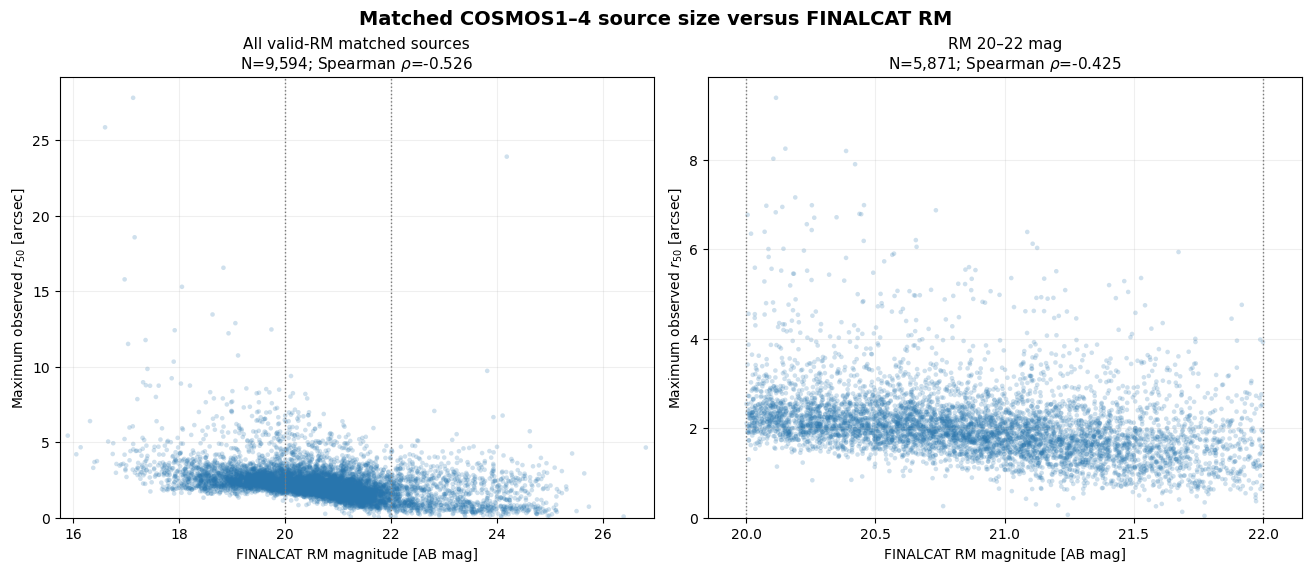

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_cosmos1-4_r50_vs_finalcat_RM_scatter.png
All valid-RM matched sources: N=9,594; RM median=20.673; r50 median=2.117 arcsec; Spearman rho=-0.5262, p=0.000e+00
RM 20–22 mag: N=5,871; RM median=20.869; r50 median=1.973 arcsec; Spearman rho=-0.4251, p=2.386e-256


In [21]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display, Markdown

# A source enters the relation only when both catalog magnitude and the
# across-field/across-band maximum radius are valid.
R50_SCATTER_FULL = R50_VALID_RM & R50_HAS_RADIUS
R50_SCATTER_CUT = R50_RM_WINDOW_MASK & R50_HAS_RADIUS
R50_SCATTER_X = [R50_RM[R50_SCATTER_FULL], R50_RM[R50_SCATTER_CUT]]
R50_SCATTER_Y = [
    R50_SOURCE_MAX_PIX[R50_SCATTER_FULL] * R50_PIXEL_SCALE_ARCSEC,
    R50_SOURCE_MAX_PIX[R50_SCATTER_CUT] * R50_PIXEL_SCALE_ARCSEC,
]
R50_SCATTER_LABELS = ['All valid-RM matched sources', 'RM 20–22 mag']
R50_SCATTER_STATS = [spearmanr(x, y) for x, y in zip(R50_SCATTER_X, R50_SCATTER_Y)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout='constrained')
for axis, x, y, label, corr in zip(
        axes, R50_SCATTER_X, R50_SCATTER_Y, R50_SCATTER_LABELS, R50_SCATTER_STATS):
    axis.scatter(x, y, s=11, alpha=0.22, color='#2875AD', edgecolors='none', rasterized=True)
    axis.axvline(20, color='#777777', linestyle=':', linewidth=1)
    axis.axvline(22, color='#777777', linestyle=':', linewidth=1)
    axis.set_xlim(float(np.min(x)) - 0.15, float(np.max(x)) + 0.15)
    axis.set_ylim(0, float(np.max(y)) * 1.05)
    axis.set_xlabel('FINALCAT RM magnitude [AB mag]')
    axis.set_ylabel(r'Maximum observed $r_{50}$ [arcsec]')
    axis.set_title(f'{label}\nN={len(x):,}; Spearman $\\rho$={corr.statistic:.3f}', fontsize=11)
    axis.grid(alpha=0.2)
fig.suptitle('Matched COSMOS1–4 source size versus FINALCAT RM', fontsize=14, fontweight='bold')
R50_SCATTER_FIG = R50_OUTPUT / 'matched_cosmos1-4_r50_vs_finalcat_RM_scatter.png'
fig.savefig(R50_SCATTER_FIG, dpi=180)
plt.show()
print(f'Saved {R50_SCATTER_FIG}')
for label, x, y, corr in zip(R50_SCATTER_LABELS, R50_SCATTER_X, R50_SCATTER_Y, R50_SCATTER_STATS):
    print(f'{label}: N={len(x):,}; RM median={np.median(x):.3f}; '
          f'r50 median={np.median(y):.3f} arcsec; Spearman rho={corr.statistic:.4f}, '
          f'p={corr.pvalue:.3e}')


In [22]:
full_corr, cut_corr = R50_SCATTER_STATS
full_n, cut_n = map(len, R50_SCATTER_X)
display(Markdown(
    '### 산점도 요약\n\n'
    f'- 전체 패널은 RM 유효 matched 천체 **{full_n:,}개**, RM 20–22 패널은 **{cut_n:,}개**입니다. '
    f'RM sentinel 및 누락값 **{(~R50_VALID_RM).sum():,}개**는 RM 축에 놓을 수 없어 제외했습니다.\n'
    f'- 전체 표본 Spearman 상관계수는 **ρ={full_corr.statistic:.3f}**, '
    f'RM 20–22 표본은 **ρ={cut_corr.statistic:.3f}**입니다.\n'
    '- 크기는 각 소스의 20개 필터와 COSMOS1–4 측정 중 최댓값을 사용했습니다. '
    '따라서 필터별 고정 크기와 COSMOS 필드별 측정 비교가 아니라, 이전 히스토그램과 같은 최대 관측 r50 요약입니다. '
    '상관계수는 이 요약 크기와 RM 사이의 순위 상관입니다.'
))


### 산점도 요약

- 전체 패널은 RM 유효 matched 천체 **9,594개**, RM 20–22 패널은 **5,871개**입니다. RM sentinel 및 누락값 **623개**는 RM 축에 놓을 수 없어 제외했습니다.
- 전체 표본 Spearman 상관계수는 **ρ=-0.526**, RM 20–22 표본은 **ρ=-0.425**입니다.
- 크기는 각 소스의 20개 필터와 COSMOS1–4 측정 중 최댓값을 사용했습니다. 따라서 필터별 고정 크기와 COSMOS 필드별 측정 비교가 아니라, 이전 히스토그램과 같은 최대 관측 r50 요약입니다. 상관계수는 이 요약 크기와 RM 사이의 순위 상관입니다.

## RM ≤ 21: band fluxes and half-flux surface-brightness proxy

The current selection for this new analysis is **finite, positive FINALCAT RM ≤ 21 mag**. All quantities below are measured per source and per filter. Among matched COSMOS1–4 measurements with both a valid band magnitude and a finite positive radius, choose the largest radius **within that filter** and retain the magnitude from the **same field and filter**. The across-band maximum used in the preceding overview histograms is not used here, because flux and size must describe the same measurement.

With $r_{50}$ in arcseconds and the AB zero point $f_{\nu,0}=3631$ Jy:

$$f_\nu=3631\,10^{-0.4m_b}\;\mathrm{Jy},\qquad
\overline I_\nu=\frac{0.5 f_\nu}{\pi r_{50}^2}
=\frac{f_\nu}{2\pi r_{50}^2}\;\mathrm{Jy\,arcsec^{-2}}.$$

$$\mu_b=-2.5\log_{10}\!\left(\frac{\overline I_\nu}{3631\;\mathrm{Jy\,arcsec^{-2}}}\right)
=m_b+2.5\log_{10}\!\left(2\pi r_{50}^2\right)
\quad[\mathrm{AB\;mag\,arcsec^{-2}}].$$

Thus $-2.5\log_{10}[1/(2\pi r_{50}^2)]$ is the **magnitude offset** to add to $m_b$. The final expression requested implies **one factor of 0.5**: half the flux, not a further 0.5 times an already halved flux.

**Scientific interpretation:** the available 7DT magnitudes are calibrated 3-arcsec-diameter aperture measurements (`aper3`), not total magnitudes. Dividing half of this aperture flux by the half-light area follows the requested calculation but is a **surface-brightness proxy**. It equals the mean brightness inside the true half-light radius only when the supplied flux is the corresponding total flux. The radii are observed, include PSF/seeing, and are not deconvolved. No additional star/galaxy, S/N, redshift, or matched-band-count selection is imposed.

Show both $\mu_b$ versus FINALCAT RM and $\mu_b$ versus the corresponding 7DT band magnitude. Every panel identifies its filter; the brighter direction is upward on the surface-brightness axis.


In [23]:
from astropy import units as u

# The preceding size-analysis section provides the catalog, matched flags,
# band list, reference-row identity, and WCS-derived 0.505 arcsec/pixel scale.
SB_RM = np.asarray(np.ma.filled(R50_CATALOG['finalcat_RM'], np.nan), dtype=float)
SB_SELECTION = np.isfinite(SB_RM) & (SB_RM > 0) & (SB_RM <= 21.0)
SB_PARENT_N = int(SB_SELECTION.sum())
SB_AB_ZEROPOINT_JY = 3631.0
SB_HALF_FLUX_FRACTION = 0.5
sb_source_rows = np.flatnonzero(SB_SELECTION)
sb_rows = []
SB_BAND_SUMMARY_ROWS = []

for band in R50_BANDS:
    band_mags = np.full((len(R50_CATALOG), len(R50_FIELDS)), np.nan)
    band_radii = np.full_like(band_mags, np.nan)
    for field_index, field in enumerate(R50_FIELDS):
        prefix = f'7dt_cosmos{field}_{band}'
        mag_name, radius_name = prefix + '_mag', prefix + '_flux_radius'
        if mag_name not in R50_CATALOG.colnames or radius_name not in R50_CATALOG.colnames:
            continue
        matched = np.asarray(np.ma.filled(R50_CATALOG[f'7dt_cosmos{field}_matched'], False), dtype=bool)
        mag = np.asarray(np.ma.filled(R50_CATALOG[mag_name], np.nan), dtype=float)
        radius = np.asarray(np.ma.filled(R50_CATALOG[radius_name], np.nan), dtype=float)
        # Require a matched field and a valid (magnitude, radius) pair. If a
        # field lacks one member of the pair, it cannot supply either quantity.
        valid = SB_SELECTION & matched & np.isfinite(mag) & np.isfinite(radius) & (radius > 0)
        band_mags[valid, field_index] = mag[valid]
        band_radii[valid, field_index] = radius[valid]
    candidates = np.where(np.isfinite(band_radii), band_radii, -np.inf)
    has_pair = np.isfinite(band_radii).any(axis=1)
    source_index = np.flatnonzero(has_pair)
    chosen_field_index = candidates[has_pair].argmax(axis=1)
    chosen_field = np.asarray(R50_FIELDS)[chosen_field_index]
    radius_pix = band_radii[source_index, chosen_field_index]
    magnitude = band_mags[source_index, chosen_field_index]
    radius_arcsec = radius_pix * R50_PIXEL_SCALE_ARCSEC

    # Explicitly compute AB flux, half flux, intensity, and AB surface
    # brightness, instead of treating a magnitude as a linear flux.
    flux_jy = SB_AB_ZEROPOINT_JY * 10.0 ** (-0.4 * magnitude)
    half_flux_jy = SB_HALF_FLUX_FRACTION * flux_jy
    area_arcsec2 = np.pi * radius_arcsec ** 2
    intensity_jy_arcsec2 = half_flux_jy / area_arcsec2
    surface_brightness = -2.5 * np.log10(intensity_jy_arcsec2 / SB_AB_ZEROPOINT_JY)
    magnitude_offset = 2.5 * np.log10(2.0 * np.pi * radius_arcsec ** 2)
    # Both routes express the user's same half-flux definition; retain the
    # residual to make the flux-to-magnitude conversion inspectable.
    identity_residual = surface_brightness - (magnitude + magnitude_offset)
    for j, source in enumerate(source_index):
        sb_rows.append((int(R50_REFERENCE_IDS[source]), float(SB_RM[source]), band,
            int(chosen_field[j]), float(magnitude[j]), float(radius_pix[j]),
            float(radius_arcsec[j]), float(flux_jy[j]), float(half_flux_jy[j]),
            float(area_arcsec2[j]), float(intensity_jy_arcsec2[j]),
            float(surface_brightness[j]), float(magnitude_offset[j]),
            float(identity_residual[j])))
    SB_BAND_SUMMARY_ROWS.append((band,len(source_index),
        float(np.median(magnitude)) if len(magnitude) else np.nan,
        float(np.median(radius_arcsec)) if len(radius_arcsec) else np.nan,
        float(np.median(surface_brightness)) if len(surface_brightness) else np.nan))

SB_PHOTOMETRY = Table(rows=sb_rows, names=[
    'finalcat_idx','FINALCAT_RM','band','selected_COSMOS','band_mag_AB',
    'r50_pix','r50_arcsec','flux_nu_Jy','half_flux_nu_Jy','area_arcsec2',
    'intensity_Jy_arcsec2','mu_AB_mag_arcsec2','mag_offset','identity_residual_mag'])
SB_PHOTOMETRY['r50_pix'].unit = u.pix
SB_PHOTOMETRY['r50_arcsec'].unit = u.arcsec
SB_PHOTOMETRY['flux_nu_Jy'].unit = u.Jy
SB_PHOTOMETRY['half_flux_nu_Jy'].unit = u.Jy
SB_PHOTOMETRY['area_arcsec2'].unit = u.arcsec ** 2
SB_PHOTOMETRY['intensity_Jy_arcsec2'].unit = u.Jy / u.arcsec ** 2
SB_PHOTOMETRY.meta['RMMAX'] = 21.0
SB_PHOTOMETRY.meta['ABZERO'] = SB_AB_ZEROPOINT_JY
SB_PHOTOMETRY.meta['FLUXFRAC'] = SB_HALF_FLUX_FRACTION
SB_PHOTOMETRY.meta['PIXSCAL'] = R50_PIXEL_SCALE_ARCSEC
SB_PHOTOMETRY.meta['MAGAPER'] = '3 arcsec diameter; not total magnitude'
SB_PHOTOMETRY.meta['R50RULE'] = 'max radius within band over fields with valid paired magnitude'
SB_PHOTOMETRY.meta['COMMENT'] = 'mu uses half aperture flux / (pi*r50_arcsec**2); a surface-brightness proxy.'
SB_TABLE_PATH = R50_OUTPUT / 'matched_RMle21_band_surface_brightness.fits'
SB_PHOTOMETRY.write(SB_TABLE_PATH, overwrite=True)
SB_SUMMARY = Table(rows=SB_BAND_SUMMARY_ROWS, names=[
    'Band','N_sources','Median_band_mag','Median_r50_arcsec','Median_mu_mag_arcsec2'])
for column in SB_SUMMARY.colnames[2:]:
    SB_SUMMARY[column].info.format = '.3f'
print(f'Finite positive FINALCAT RM <= 21: {SB_PARENT_N:,} sources')
print(f'Sources with a valid magnitude/r50 pair in any band: {len(np.unique(SB_PHOTOMETRY["finalcat_idx"])):,}')
print(f'Source-band measurements after field reduction: {len(SB_PHOTOMETRY):,}')
print(f'Maximum difference between flux-based and direct magnitude calculation: '
      f'{np.max(np.abs(SB_PHOTOMETRY["identity_residual_mag"])):.3e} mag')
SB_SUMMARY.pprint(max_lines=-1,max_width=-1)
print(f'Saved derived measurements: {SB_TABLE_PATH}')


Finite positive FINALCAT RM <= 21: 6,043 sources
Sources with a valid magnitude/r50 pair in any band: 6,043
Source-band measurements after field reduction: 50,777
Maximum difference between flux-based and direct magnitude calculation: 7.105e-15 mag
Band N_sources Median_band_mag Median_r50_arcsec Median_mu_mag_arcsec2
---- --------- --------------- ----------------- ---------------------
m400      1238          21.091             1.791                24.412
m425      1559          20.916             1.915                24.315
m450      2436          20.465             1.804                23.680
m475      4283          20.851             2.139                24.462
m500      3705          21.004             1.743                24.175
m525      3495          20.684             1.856                23.968
m550      3142          20.442             1.923                23.834
m575      3622          20.352             2.003                23.837
m600      3653          20.328           

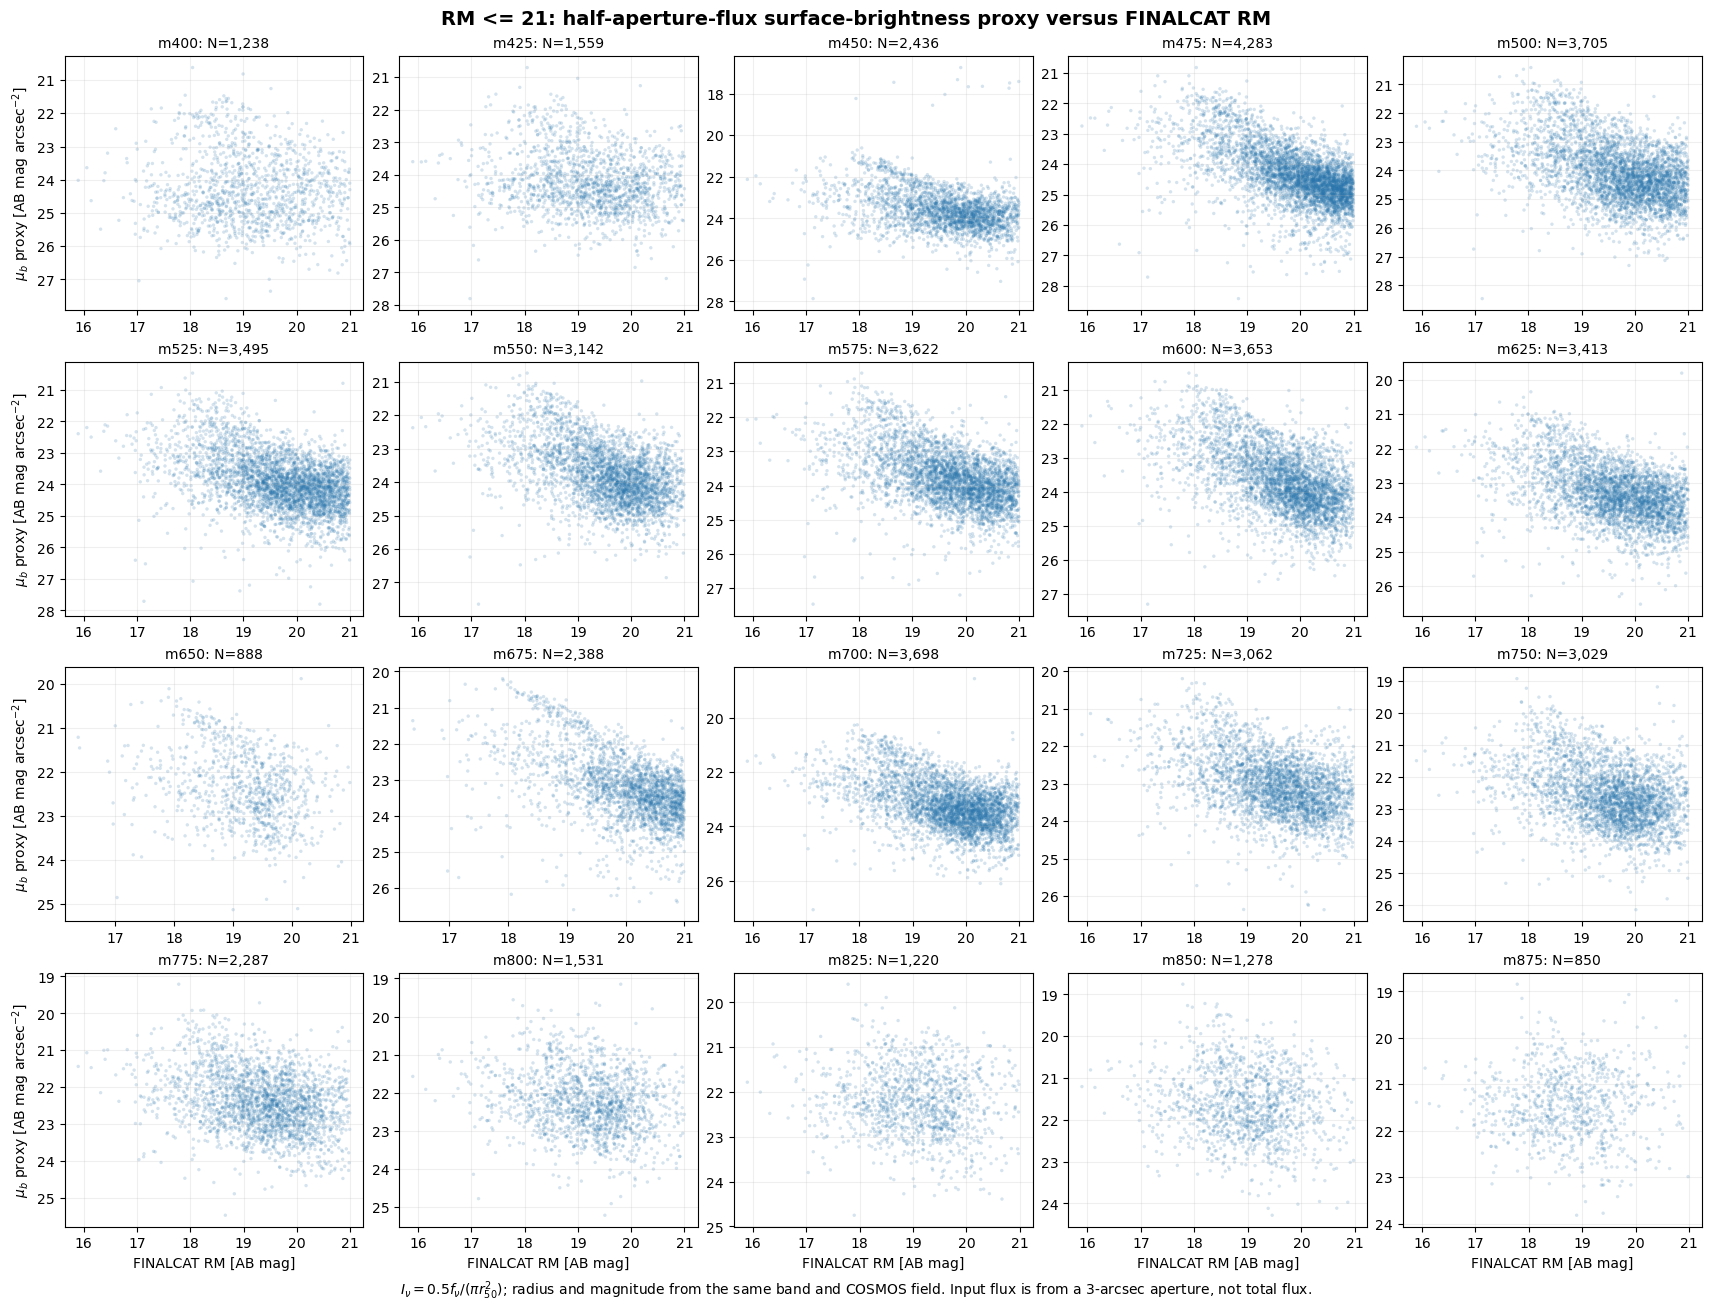

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_RMle21_mu_vs_RM_per_band.png


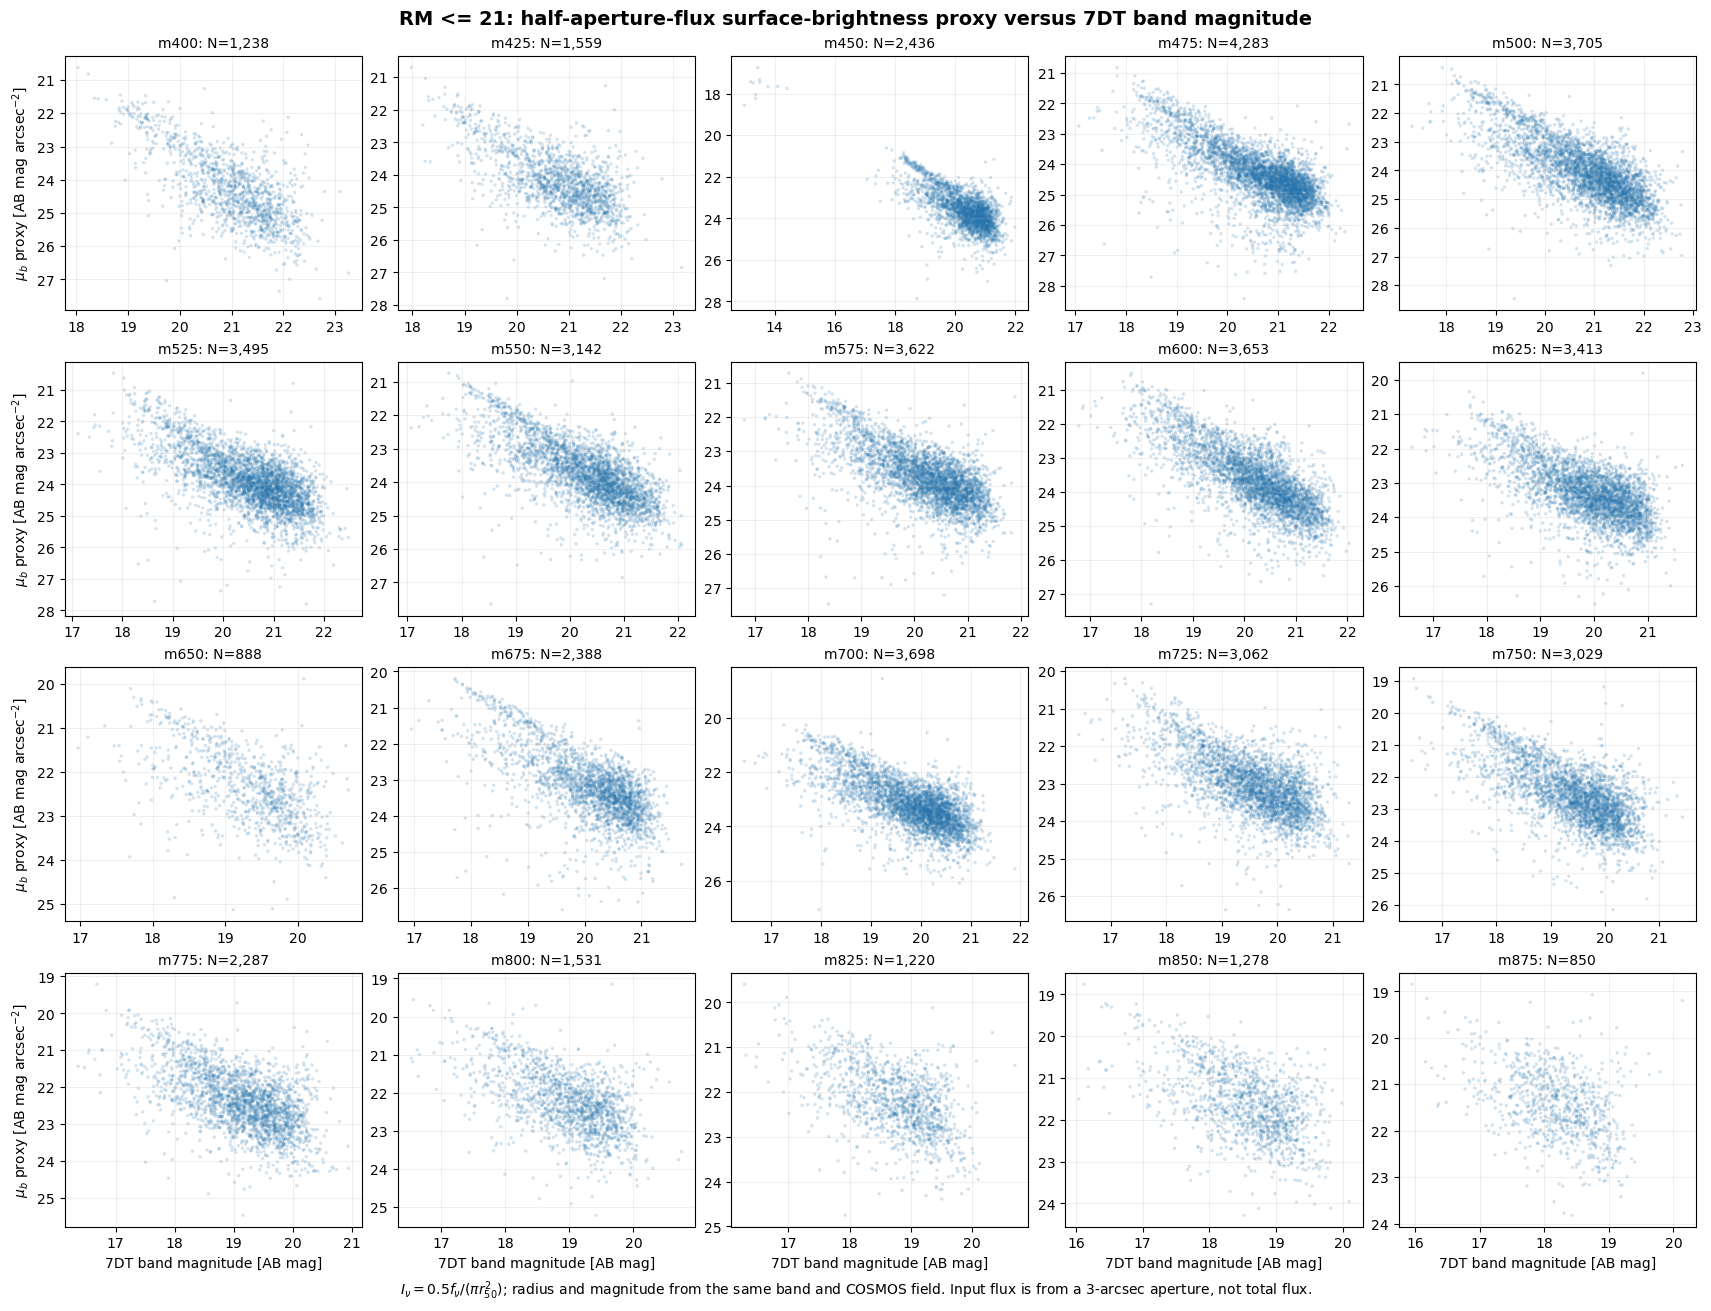

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/matched_RMle21_mu_vs_bandmag_per_band.png


In [24]:
SB_SCATTER_PATHS = []
# These two x-axis choices answer different questions: RM is the reference
# magnitude used for source selection, while band_mag_AB is the flux input
# to the surface-brightness conversion for that particular filter.
for x_column, x_label, filename, title in [
    ('FINALCAT_RM','FINALCAT RM [AB mag]',
     'matched_RMle21_mu_vs_RM_per_band.png',
     'RM <= 21: half-aperture-flux surface-brightness proxy versus FINALCAT RM'),
    ('band_mag_AB','7DT band magnitude [AB mag]',
     'matched_RMle21_mu_vs_bandmag_per_band.png',
     'RM <= 21: half-aperture-flux surface-brightness proxy versus 7DT band magnitude'),
]:
    fig,axes = plt.subplots(4,5,figsize=(17,13),layout='constrained')
    for index,(axis,band) in enumerate(zip(axes.flat,R50_BANDS)):
        band_rows = SB_PHOTOMETRY[np.asarray(SB_PHOTOMETRY['band']).astype(str)==band]
        x=np.asarray(band_rows[x_column],dtype=float)
        y=np.asarray(band_rows['mu_AB_mag_arcsec2'],dtype=float)
        axis.scatter(x,y,s=6,alpha=0.2,color='#2875AD',edgecolors='none',rasterized=True)
        axis.set_title(f'{band}: N={len(band_rows):,}',fontsize=10)
        # Reverse the magnitude axis so higher surface brightness is upward.
        axis.invert_yaxis()
        axis.grid(alpha=0.2)
        if index%5==0:
            axis.set_ylabel(r'$\mu_b$ proxy [AB mag arcsec$^{-2}$]')
        if index>=15:
            axis.set_xlabel(x_label)
    fig.suptitle(title,fontsize=14,fontweight='bold')
    fig.supxlabel(r'$I_\nu=0.5 f_\nu/(\pi r_{50}^2)$; radius and magnitude from the same band and COSMOS field. '
                  'Input flux is from a 3-arcsec aperture, not total flux.',fontsize=10)
    save_path=R50_OUTPUT/filename
    fig.savefig(save_path,dpi=180)
    plt.show()
    SB_SCATTER_PATHS.append(save_path)
    print(f'Saved {save_path}')


In [25]:
display(Markdown(
    '### 계산 결과와 해석\n\n'
    f'- 현재 선택은 **유효한 RM ≤ 21 mag**, 총 **{SB_PARENT_N:,}개 천체**입니다. '
    f'필터별 유효 flux/r50 조합 **{len(SB_PHOTOMETRY):,}건**을 계산했습니다.\n'
    '- AB magnitude를 Jy 단위 flux로 바꾼 뒤 **0.5 × flux / (π r50²)**를 계산하고 '
    '다시 AB mag/arcsec²로 변환했습니다. 반지름에는 arcsec 단위를 사용했습니다.\n'
    '- 직접 계산식은 **μ = m + 2.5 log10(2π r50²)**입니다. '
    '질문에 적은 −2.5 log10[1/(2π r50²)] 항은 원래 magnitude에 더하는 보정량입니다.\n'
    '- 같은 필터의 여러 COSMOS 측정 중 유효한 r50가 가장 큰 측정을 선택하고, '
    '그 측정의 magnitude를 함께 사용했습니다.\n'
    '- 첫 20개 패널은 RM–μ, 다음 20개 패널은 각 밴드 자체 magnitude–μ입니다. '
    '표면밝기가 밝을수록 위에 표시했습니다.\n'
    '- 현재 입력은 3″ aperture flux이므로, 이 결과를 total flux 기반의 정확한 '
    '평균 유효 표면밝기로 해석하려면 total magnitude와의 일관성을 추가로 확인해야 합니다.'
))


### 계산 결과와 해석

- 현재 선택은 **유효한 RM ≤ 21 mag**, 총 **6,043개 천체**입니다. 필터별 유효 flux/r50 조합 **50,777건**을 계산했습니다.
- AB magnitude를 Jy 단위 flux로 바꾼 뒤 **0.5 × flux / (π r50²)**를 계산하고 다시 AB mag/arcsec²로 변환했습니다. 반지름에는 arcsec 단위를 사용했습니다.
- 직접 계산식은 **μ = m + 2.5 log10(2π r50²)**입니다. 질문에 적은 −2.5 log10[1/(2π r50²)] 항은 원래 magnitude에 더하는 보정량입니다.
- 같은 필터의 여러 COSMOS 측정 중 유효한 r50가 가장 큰 측정을 선택하고, 그 측정의 magnitude를 함께 사용했습니다.
- 첫 20개 패널은 RM–μ, 다음 20개 패널은 각 밴드 자체 magnitude–μ입니다. 표면밝기가 밝을수록 위에 표시했습니다.
- 현재 입력은 3″ aperture flux이므로, 이 결과를 total flux 기반의 정확한 평균 유효 표면밝기로 해석하려면 total magnitude와의 일관성을 추가로 확인해야 합니다.

## Cumulative source counts and m425/m650 depth maps

One figure with **one row and three panels**, ordered left to right:

1. The cumulative RM histogram from notebook 2.3: identical 0.5-mag bins, connected curves at bin centers, wavelength colors, unique-source band-success selection, $r=17$–21 display range, and $N_{\mathrm{source}}$ axis label. Reference legend: **Subaru/HSC** (no N).
2. The **m425** depth map.
3. The **m650** depth map.

Both depth panels use the same `viridis` color scale over 13–22.5 AB mag, with opaque depth colors and a **5σ limiting magnitude [AB mag]** colorbar label. Display-only Field 1–4 follow the plotted quadrant convention (upper right, upper left, lower left, lower right). Each available field shows the coadd FITS header's `EXPTIME` in seconds below its name; unavailable bands are labeled accordingly. Depths use a 3″-diameter aperture and the deepest available field at each position. No subplot titles or depth legends are added.

The calculations below read the saved matched catalog and per-field depth CSVs. The figure is saved as PNG (300 dpi) and PDF in `Report/7DT Observation Proposal` and displayed below.

The depth panels show band names in the upper-left corner in white on translucent black boxes. Field/exposure and band annotations use 22 pt text (twice the previous 11 pt field annotation size). The magnitude display crop does not alter any sample or cumulative count.

All three panels’ x/y axis-label fonts are scaled to 1.7× their original sizes; the band and Field/exposure annotations retain their existing font size.

The wavelength and depth colorbar label fonts are 1.4× their previous sizes.


In [26]:
# Independently runnable: read the persisted catalog, without rebuilding it
# or repeating the SDSS queries in the catalog-production section.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from astropy.io import fits
from astropy.table import Table
from scl_plot import scl_plt

CUM_ROOT = Path.cwd().resolve()
if CUM_ROOT.name == 'Notebooks':
    CUM_ROOT = CUM_ROOT.parent
CUM_OUTPUT = CUM_ROOT / 'output/singlephot/analysis/numofmatchedbands'
CUM_OUTPUT.mkdir(parents=True, exist_ok=True)
CUM_PATH = CUM_ROOT / 'output/singlephot/master_catalog_MatchedWithFianlcat_OverallCosmosField.fits'
CUM_CATALOG = Table.read(CUM_PATH, hdu='CATALOG')
CUM_REFERENCE = Table.read(CUM_ROOT / 'COSMOS_data/COSMOS_finalcat.fits')
CUM_BANDS = tuple(f'm{wave}' for wave in range(400, 900, 25))
CUM_FIELDS = (1, 2, 3, 4)
with fits.open(CUM_PATH, memmap=False) as hdus:
    # The production file stores exact masks separately, including Boolean
    # columns. Honor those masks when reading the saved per-band success flags.
    CUM_PACKED_MASKS = np.array(hdus['COLUMN_MASKS'].data, copy=True)
    CUM_BITORDER = hdus['COLUMN_MASKS'].header['BITORDER']
CUM_COLUMN_INDEX = {name: i for i, name in enumerate(CUM_CATALOG.colnames)}


def cumulative_catalog_values(name, fill=np.nan):
    """Return one saved column with its production FITS mask restored."""
    index = CUM_COLUMN_INDEX[name]
    bit = index % 8 if CUM_BITORDER == 'little' else 7 - index % 8
    masked = ((CUM_PACKED_MASKS[:, index // 8] >> bit) & 1).astype(bool)
    values = np.asarray(CUM_CATALOG[name], dtype=float).copy()
    values[masked | np.ma.getmaskarray(CUM_CATALOG[name])] = fill
    return values


CUM_RM = cumulative_catalog_values('finalcat_RM')
CUM_REF_RM = np.asarray(np.ma.filled(CUM_REFERENCE['RM'], np.nan), dtype=float)
CUM_VALID = np.isfinite(CUM_RM) & (CUM_RM > 0) & (CUM_RM < 50)
CUM_REF_VALID = np.isfinite(CUM_REF_RM) & (CUM_REF_RM > 0) & (CUM_REF_RM < 50)
# Keep the previous section's 0.5-mag spacing over the full valid RM range.
CUM_ALL_RM = np.concatenate([CUM_RM[CUM_VALID], CUM_REF_RM[CUM_REF_VALID]])
CUM_THRESHOLDS = np.arange(np.floor(CUM_ALL_RM.min() * 2) / 2,
                           np.ceil(CUM_ALL_RM.max() * 2) / 2 + 0.5, 0.5)


def cumulative_rm_counts(values):
    """Count RM <= each threshold, including values on the threshold itself.

    Count from the complete valid bright-end sample before restricting the
    display to 16-21 mag; a cropped histogram would omit brighter sources.
    """
    return np.searchsorted(np.sort(values), CUM_THRESHOLDS, side='right')


CUM_REFERENCE_COUNTS = cumulative_rm_counts(CUM_REF_RM[CUM_REF_VALID])
CUM_BAND_COUNTS = {}
for band in CUM_BANDS:
    successful = np.zeros(len(CUM_CATALOG), dtype=bool)
    for field in CUM_FIELDS:
        prefix = f'7dt_cosmos{field}_'
        matched = cumulative_catalog_values(prefix + 'matched', fill=0).astype(bool)
        success = cumulative_catalog_values(prefix + band + '_success', fill=0).astype(bool)
        # The saved success flags encode source_id >= 0, 0 < mag < 50,
        # finite mag/error, and mag_err > 0. Union fields within each band.
        successful |= matched & success
    CUM_BAND_COUNTS[band] = cumulative_rm_counts(CUM_RM[successful & CUM_VALID])

CUM_TABLE = Table([CUM_THRESHOLDS, CUM_REFERENCE_COUNTS] +
                  [CUM_BAND_COUNTS[band] for band in CUM_BANDS],
                  names=['RM_threshold', 'N_reference'] + [f'N_{band}' for band in CUM_BANDS])
CUM_WAVELENGTH = np.array([int(band[1:]) for band in CUM_BANDS], dtype=float)
CUM_CMAP = LinearSegmentedColormap.from_list(
    'cumulative_purple_to_red',
    ['#8A00CC', '#003BFF', '#00BFFF', '#00A83B', '#FFD400', '#FF6500', '#E00000'])
CUM_NORM = Normalize(vmin=CUM_WAVELENGTH.min(), vmax=CUM_WAVELENGTH.max())

# Match the preceding figure: cumulative bin counts at bin centers,
# with connected lines and small circular markers for the 7DT bands.
CUM_BIN_CENTERS = 0.5 * (CUM_THRESHOLDS[:-1] + CUM_THRESHOLDS[1:])



In [27]:
# Keep the combined-depth section independently runnable from root/Notebooks.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / 'COSMOS_data'
BANDS_7DT = tuple(f'm{wave}' for wave in range(400, 900, 25))
OVERALL_ANALYSIS_DIR = PROJECT_ROOT / 'output/singlephot/analysis'


def _combined_depth_band_image_path(cosmos, band):
    """Resolve the band's coadd for the same WCS used by Proposal.ipynb."""
    paths = sorted((DATA_ROOT / f'COSMOS{cosmos}').glob(f'*{band}*.com.fits'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one COSMOS{cosmos} {band} coadd; got {len(paths)}')
    return paths[0]

# Load the COSMOS1-4 depth grids and convert their cell boundaries to RA/Dec.
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon

COMBINED_DEPTH_FIG_DIR = OVERALL_ANALYSIS_DIR
COMBINED_DEPTH_FIG_DIR.mkdir(parents=True, exist_ok=True)
COMBINED_DEPTH_COSMOS = (1, 2, 3, 4)
# Display-only numbering follows mathematical quadrants on the reversed-RA
# plot: upper right=1, upper left=2, lower left=3, lower right=4.
# Original COSMOS IDs still select every input file, WCS, and depth grid.
COMBINED_DEPTH_DISPLAY_FIELD = {1: 4, 2: 1, 3: 3, 4: 2}
COMBINED_DEPTH_POOL = 16
COMBINED_DEPTH_PAD_DEG = 0.02
COMBINED_DEPTH_BACKGROUND_ALPHA = 0.22
COMBINED_DEPTH_LABEL_BBOX_ALPHA = 0.30
COMBINED_DEPTH_MAP_NX = 1000
COMBINED_DEPTH_MAP_NY = 750


def _combined_depth_csv_path(cosmos):
    return (PROJECT_ROOT / 'output' / f'COSMOS{cosmos}' / 'singlephot' / 'analysis'
            / f'cosmos{cosmos}_7dt_depth_5sigma_3arcsec.csv')


def _combined_depth_detection_path(cosmos):
    candidates = [
        DATA_ROOT / f'COSMOS{cosmos}' / f'COSMOS{cosmos}_detectionimage.fits',
        PROJECT_ROOT / 'output' / f'COSMOS{cosmos}' / f'COSMOS{cosmos}_detectionimage.fits',
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(f'No detection image found for COSMOS{cosmos}')


def _combined_depth_pooled_background(path, factor=COMBINED_DEPTH_POOL):
    data = fits.getdata(path, memmap=True)
    ny, nx = data.shape
    nx_used, ny_used = (nx // factor) * factor, (ny // factor) * factor
    pooled = np.empty((ny_used // factor, nx_used // factor), dtype=np.float32)
    for y0 in range(0, ny_used, 1024):
        y1 = min(y0 + 1024, ny_used)
        chunk = np.asarray(data[y0:y1, :nx_used], dtype=np.float32)
        chunk_h = (y1 - y0) // factor
        block = chunk[:chunk_h * factor].reshape(chunk_h, factor, nx_used // factor, factor)
        with np.errstate(invalid='ignore'):
            pooled[y0 // factor:y0 // factor + chunk_h] = np.nanmean(block, axis=(1, 3))
    return np.ma.masked_equal(pooled, 0.0), nx_used, ny_used


combined_depth_tables = {}
combined_depth_available_by_band = {band: set() for band in BANDS_7DT}
combined_depth_maps = {}
combined_depth_footprints = {}
all_ra, all_dec, background_samples = [], [], []

for cosmos in COMBINED_DEPTH_COSMOS:
    csv_path = _combined_depth_csv_path(cosmos)
    if not csv_path.exists():
        raise FileNotFoundError(f'Missing depth table: {csv_path}')
    table = Table.read(csv_path, format='csv')
    combined_depth_tables[cosmos] = table
    available = set(np.asarray(table['band']).astype(str))
    for band in available:
        combined_depth_available_by_band.setdefault(band, set()).add(cosmos)

    detection_path = _combined_depth_detection_path(cosmos)
    detection_header = fits.getheader(detection_path)
    detection_wcs = WCS(detection_header)
    background, nx_used, ny_used = _combined_depth_pooled_background(detection_path)
    x_corners = np.array([0.5, nx_used + 0.5, nx_used + 0.5, 0.5])
    y_corners = np.array([0.5, 0.5, ny_used + 0.5, ny_used + 0.5])
    ra_corners, dec_corners = detection_wcs.all_pix2world(x_corners, y_corners, 1)
    combined_depth_footprints[cosmos] = {
        'background': background,
        'wcs': detection_wcs,
        'ra_corners': np.asarray(ra_corners, dtype=float),
        'dec_corners': np.asarray(dec_corners, dtype=float),
        'ra_min': float(np.nanmin(ra_corners)),
        'ra_max': float(np.nanmax(ra_corners)),
        'dec_min': float(np.nanmin(dec_corners)),
        'dec_max': float(np.nanmax(dec_corners)),
        'nx_used': nx_used,
        'ny_used': ny_used,
        'polygon': np.column_stack((ra_corners, dec_corners)),
    }
    all_ra.extend(ra_corners.tolist())
    all_dec.extend(dec_corners.tolist())
    finite_background = background.compressed()
    if finite_background.size:
        background_samples.append(finite_background[::max(1, finite_background.size // 50000)])

    for band in available:
        band_path = _combined_depth_band_image_path(cosmos, band)
        band_header = fits.getheader(band_path)
        # Match by the FITS FILTER keyword, never by filename order. Read the
        # coadd's actual EXPTIME: COSMOS1-3 report total exposure duration;
        # COSMOS4 describes its keyword as maximum equivalent exposure time.
        if str(band_header['FILTER']).strip() != band:
            raise ValueError(f'Unexpected FILTER in {band_path}')
        exposure_seconds = float(band_header['EXPTIME'])
        if not np.isfinite(exposure_seconds) or exposure_seconds <= 0:
            raise ValueError(f'Invalid EXPTIME in {band_path}')
        band_wcs = WCS(band_header)
        band_rows = table[np.asarray(table['band']).astype(str) == band]
        x_edges = np.unique(np.concatenate([
            np.asarray(band_rows['x_min'], dtype=float), np.asarray(band_rows['x_max'], dtype=float)
        ]))
        y_edges = np.unique(np.concatenate([
            np.asarray(band_rows['y_min'], dtype=float), np.asarray(band_rows['y_max'], dtype=float)
        ]))
        if len(x_edges) < 2 or len(y_edges) < 2:
            continue
        pixel_x, pixel_y = np.meshgrid(x_edges + 0.5, y_edges + 0.5)
        ra_edges, dec_edges = band_wcs.all_pix2world(pixel_x, pixel_y, 1)
        depth_grid = np.full((len(y_edges) - 1, len(x_edges) - 1), np.nan, dtype=float)
        invalid_grid = np.zeros_like(depth_grid, dtype=bool)
        for row in band_rows:
            ix = int(np.searchsorted(x_edges, float(row['x_min']), side='left'))
            iy = int(np.searchsorted(y_edges, float(row['y_min']), side='left'))
            if ix >= depth_grid.shape[1] or iy >= depth_grid.shape[0]:
                continue
            status = str(row['status']).strip()
            depth = float(row['depth_5sigma_mag'])
            if status == 'ok' and np.isfinite(depth):
                depth_grid[iy, ix] = depth
            else:
                invalid_grid[iy, ix] = True
        combined_depth_maps[(cosmos, band)] = {
            'wcs': band_wcs,
            'exptime_s': exposure_seconds,
            'x_edges': x_edges + 0.5,
            'y_edges': y_edges + 0.5,
            'ra_edges': np.asarray(ra_edges, dtype=float),
            'dec_edges': np.asarray(dec_edges, dtype=float),
            'depth': depth_grid,
            'invalid': invalid_grid,
        }

COMBINED_DEPTH_RA_MIN = float(np.nanmin(all_ra))
COMBINED_DEPTH_RA_MAX = float(np.nanmax(all_ra))
COMBINED_DEPTH_DEC_MIN = float(np.nanmin(all_dec))
COMBINED_DEPTH_DEC_MAX = float(np.nanmax(all_dec))
if background_samples:
    background_values = np.concatenate(background_samples)
    background_vmin, background_vmax = np.nanpercentile(background_values, [1, 99])
else:
    background_vmin, background_vmax = 0.0, 1.0
COMBINED_DEPTH_BACKGROUND_NORM = Normalize(background_vmin, background_vmax, clip=True)

for band in BANDS_7DT:
    fields = sorted(combined_depth_available_by_band.get(band, set()))
    print(f'{band}: available COSMOS fields={fields or "none"}')
print(f'Combined RA range: [{COMBINED_DEPTH_RA_MIN:.5f}, {COMBINED_DEPTH_RA_MAX:.5f}] deg')
print(f'Combined Dec range: [{COMBINED_DEPTH_DEC_MIN:.5f}, {COMBINED_DEPTH_DEC_MAX:.5f}] deg')


# Use the same all-field/all-band magnitude limits as Proposal.ipynb.
# Round outward to half magnitudes; avoid per-band percentile clipping so
# the same AB limiting magnitude maps to the same color in every image.
COMBINED_DEPTH_ALL_VALUES = np.concatenate([
    entry['depth'][np.isfinite(entry['depth'])]
    for entry in combined_depth_maps.values()
])
if not COMBINED_DEPTH_ALL_VALUES.size:
    raise ValueError('No finite depth measurements for the shared color scale')
COMBINED_DEPTH_VMIN = float(np.floor(COMBINED_DEPTH_ALL_VALUES.min() * 2) / 2)
COMBINED_DEPTH_VMAX = float(np.ceil(COMBINED_DEPTH_ALL_VALUES.max() * 2) / 2)
if COMBINED_DEPTH_VMAX == COMBINED_DEPTH_VMIN:
    COMBINED_DEPTH_VMAX += 0.5
COMBINED_DEPTH_NORM = Normalize(COMBINED_DEPTH_VMIN, COMBINED_DEPTH_VMAX, clip=True)
COMBINED_DEPTH_CMAP = plt.get_cmap('viridis')
print(f'Shared depth color scale: {COMBINED_DEPTH_VMIN:.1f}–{COMBINED_DEPTH_VMAX:.1f} AB mag')


from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as patheffects

ra_edges = np.linspace(COMBINED_DEPTH_RA_MIN, COMBINED_DEPTH_RA_MAX, COMBINED_DEPTH_MAP_NX + 1)
dec_edges = np.linspace(COMBINED_DEPTH_DEC_MIN, COMBINED_DEPTH_DEC_MAX, COMBINED_DEPTH_MAP_NY + 1)
ra_centers = 0.5 * (ra_edges[:-1] + ra_edges[1:])
dec_centers = 0.5 * (dec_edges[:-1] + dec_edges[1:])
world_ra, world_dec = np.meshgrid(ra_centers, dec_centers)

detection_coverage = np.zeros(world_ra.shape, dtype=bool)
for cosmos in COMBINED_DEPTH_COSMOS:
    footprint = combined_depth_footprints[cosmos]
    pixel_x, pixel_y = footprint['wcs'].all_world2pix(world_ra, world_dec, 1)
    detection_coverage |= (pixel_x >= 0.5) & (pixel_x < footprint['nx_used'] + 0.5) & (pixel_y >= 0.5) & (pixel_y < footprint['ny_used'] + 0.5)


def proposal_draw_depth(fig, ax, band):
    """Draw the current depth-analysis recipe on one of the figure's axes.

    Use native axes with the shared all-band normalization, display-only Field
    numbering, and the original field/band coadd's FITS EXPTIME annotation.
    """
    available_fields = sorted(combined_depth_available_by_band.get(band, set()))
    selected_depth = np.full(world_ra.shape, np.nan, dtype=float)
    selected_field = np.zeros(world_ra.shape, dtype=np.int8)
    band_coverage = np.zeros(world_ra.shape, dtype=bool)
    for cosmos in available_fields:
        depth_map = combined_depth_maps[(cosmos, band)]
        pixel_x, pixel_y = depth_map['wcs'].all_world2pix(world_ra, world_dec, 1)
        ix = np.searchsorted(depth_map['x_edges'], pixel_x, side='right') - 1
        iy = np.searchsorted(depth_map['y_edges'], pixel_y, side='right') - 1
        inside = (ix >= 0) & (ix < depth_map['depth'].shape[1]) & (iy >= 0) & (iy < depth_map['depth'].shape[0])
        band_coverage |= inside
        candidate = np.full(world_ra.shape, np.nan, dtype=float)
        candidate[inside] = depth_map['depth'][iy[inside], ix[inside]]
        use_candidate = np.isfinite(candidate) & (~np.isfinite(selected_depth) | (candidate > selected_depth))
        selected_depth[use_candidate] = candidate[use_candidate]
        selected_field[use_candidate] = cosmos
    finite_depths = selected_depth[np.isfinite(selected_depth)]
    depth_vmin, depth_vmax = COMBINED_DEPTH_VMIN, COMBINED_DEPTH_VMAX
    depth_norm, depth_cmap = COMBINED_DEPTH_NORM, COMBINED_DEPTH_CMAP

    ax.set_facecolor('#252525')
    for cosmos in COMBINED_DEPTH_COSMOS:
        footprint = combined_depth_footprints[cosmos]
        ax.imshow(
            footprint['background'], origin='lower', cmap='gray', norm=COMBINED_DEPTH_BACKGROUND_NORM,
            extent=[footprint['ra_max'], footprint['ra_min'], footprint['dec_min'], footprint['dec_max']],
            interpolation='nearest', alpha=COMBINED_DEPTH_BACKGROUND_ALPHA, aspect='auto', zorder=0,
        )

    ax.pcolormesh(
        ra_edges, dec_edges, np.ma.masked_invalid(selected_depth), cmap=depth_cmap,
        # Opaque colors match Proposal and do not mix with the grayscale background.
        norm=depth_norm, shading='flat', alpha=1.0, zorder=2, rasterized=True,
    )
    unavailable_only = detection_coverage & ~band_coverage
    insufficient_only = band_coverage & ~np.isfinite(selected_depth)
    if np.any(unavailable_only):
        ax.contourf(world_ra, world_dec, unavailable_only.astype(float), levels=[0.5, 1.5],
                    colors='none', hatches=['///'], alpha=0.55, zorder=3)
    if np.any(insufficient_only):
        ax.contourf(world_ra, world_dec, insufficient_only.astype(float), levels=[0.5, 1.5],
                    colors='none', hatches=['..'], alpha=0.42, zorder=4)

    for cosmos in COMBINED_DEPTH_COSMOS:
        footprint = combined_depth_footprints[cosmos]
        is_available = cosmos in available_fields
        field_number = COMBINED_DEPTH_DISPLAY_FIELD[cosmos]
        if is_available:
            # Exposure is specific to this original field AND this band.
            # No averaging across overlapping fields or filename-based values.
            exposure_seconds = combined_depth_maps[(cosmos, band)]['exptime_s']
            label = f'Field {field_number}\n({exposure_seconds:g}s)'
        else:
            # A missing band has no EXPTIME; do not imply a zero-second image.
            label = f'Field {field_number}\n(unavailable)' 
        ax.text(
            np.mean(footprint['ra_corners']), np.mean(footprint['dec_corners']), label,
            ha='center', va='center', color='white', alpha=0.96, fontsize=22, fontweight='bold',
            bbox=dict(facecolor='black', edgecolor='none', alpha=COMBINED_DEPTH_LABEL_BBOX_ALPHA, pad=2.5),
            path_effects=[patheffects.withStroke(linewidth=1.5, foreground='black', alpha=0.55)],
            zorder=6,
        )

    # Place the band name at the upper-left corner of the panel, using the
    # same white type and translucent black box as the field annotations.
    ax.text(0.04, 0.96, band, transform=ax.transAxes,
            ha='left', va='top', color='white', alpha=0.96,
            fontsize=22, fontweight='bold',
            bbox=dict(facecolor='black', edgecolor='none',
                      alpha=COMBINED_DEPTH_LABEL_BBOX_ALPHA, pad=2.5),
            path_effects=[patheffects.withStroke(linewidth=1.5, foreground='black', alpha=0.55)],
            zorder=7)

    depth_mappable = ScalarMappable(norm=depth_norm, cmap=depth_cmap)
    depth_mappable.set_array(finite_depths if finite_depths.size else np.array([depth_vmin, depth_vmax]))
    colorbar = fig.colorbar(depth_mappable, ax=ax, pad=0.02)
    colorbar.set_label(r'$5\sigma$ limiting magnitude [AB mag]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    ax.set_xlim(COMBINED_DEPTH_RA_MAX + COMBINED_DEPTH_PAD_DEG, COMBINED_DEPTH_RA_MIN - COMBINED_DEPTH_PAD_DEG)
    ax.set_ylim(COMBINED_DEPTH_DEC_MIN - COMBINED_DEPTH_PAD_DEG, COMBINED_DEPTH_DEC_MAX + COMBINED_DEPTH_PAD_DEG)
    ax.set_xlabel('RA [deg]')
    ax.set_ylabel('Dec [deg]')
    ax.grid(alpha=0.16, linewidth=0.6)


m400: available COSMOS fields=[1, 2, 3, 4]
m425: available COSMOS fields=[1, 2, 3, 4]
m450: available COSMOS fields=[1, 2, 3]
m475: available COSMOS fields=[1, 2, 3]
m500: available COSMOS fields=[1, 2, 3, 4]
m525: available COSMOS fields=[1, 2, 3, 4]
m550: available COSMOS fields=[1, 2, 3, 4]
m575: available COSMOS fields=[1, 2, 3, 4]
m600: available COSMOS fields=[1, 2, 3, 4]
m625: available COSMOS fields=[1, 2, 3, 4]
m650: available COSMOS fields=[1]
m675: available COSMOS fields=[1]
m700: available COSMOS fields=[1, 2, 3, 4]
m725: available COSMOS fields=[1, 2, 3, 4]
m750: available COSMOS fields=[1, 2, 3, 4]
m775: available COSMOS fields=[1, 2, 3, 4]
m800: available COSMOS fields=[1, 3, 4]
m825: available COSMOS fields=[1, 3, 4]
m850: available COSMOS fields=[1, 2, 3, 4]
m875: available COSMOS fields=[1, 2, 3, 4]
Combined RA range: [149.08480, 151.11632] deg
Combined Dec range: [1.47295, 2.97670] deg
Shared depth color scale: 13.0–22.5 AB mag


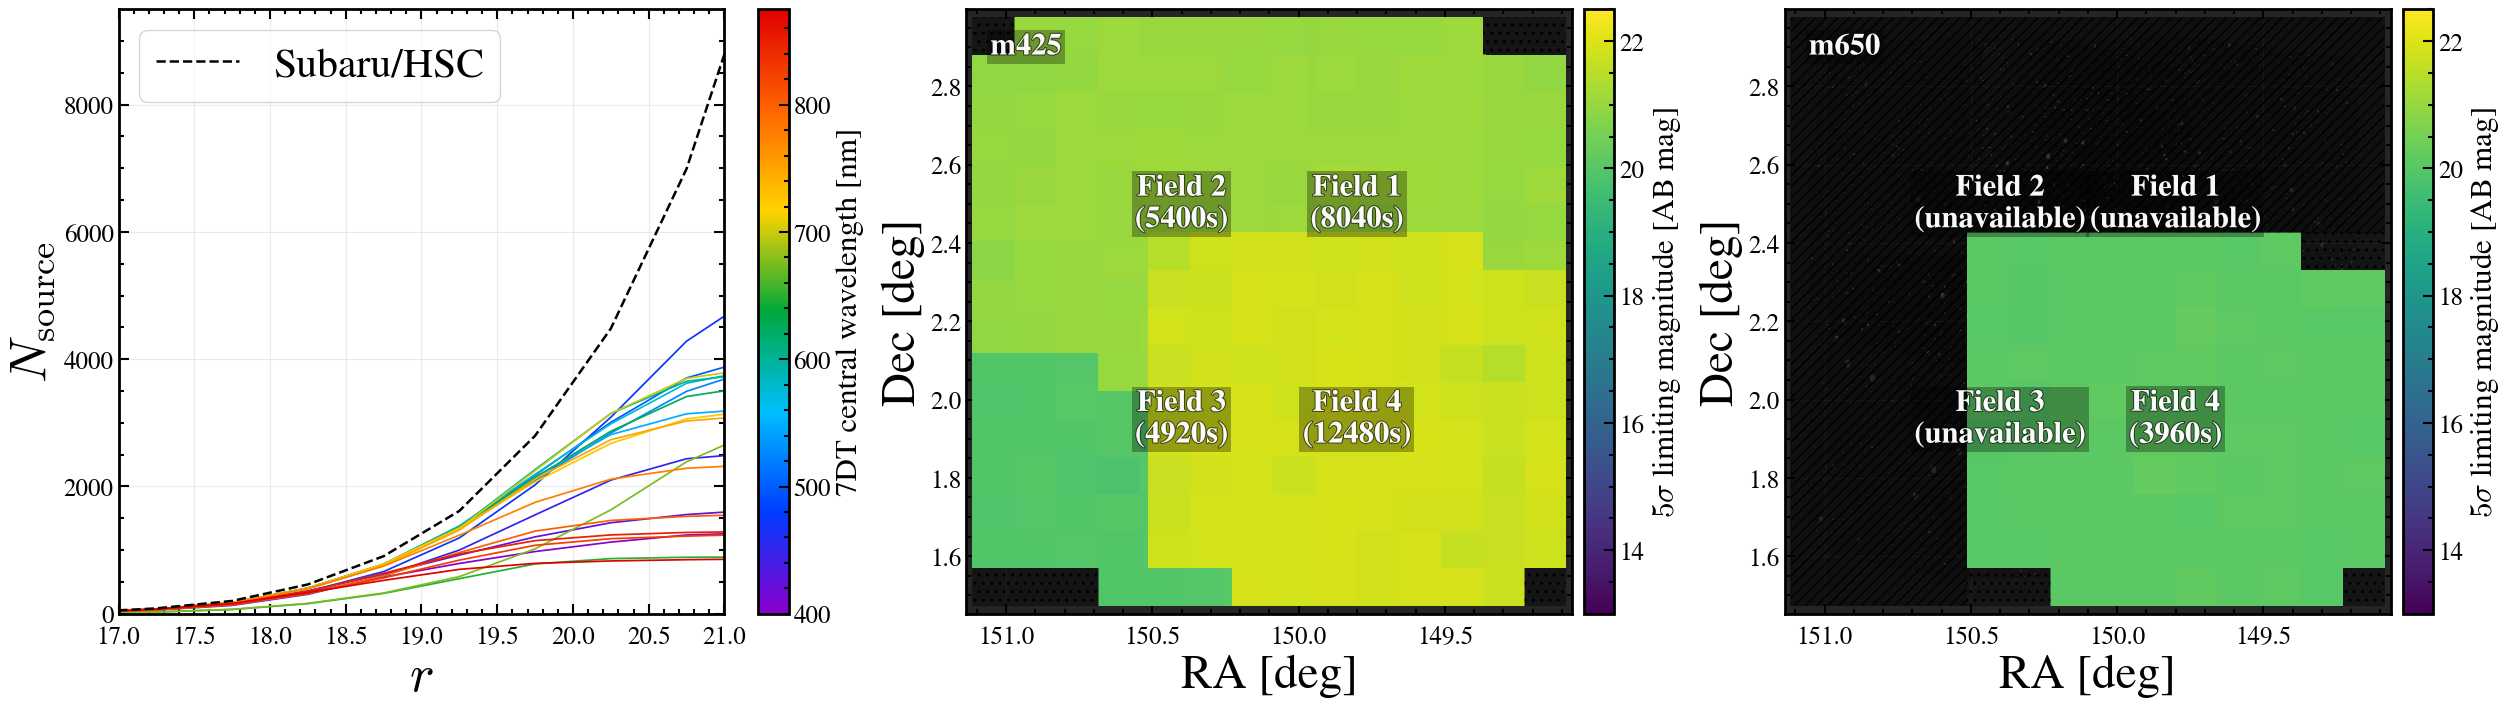

Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/cumulative_rm_depth_m425_m650.png
Saved /Users/mac_seo/Research_local/7DTonCOSMOS/Report/7DT Observation Proposal/cumulative_rm_depth_m425_m650.pdf


In [28]:
# Assemble the new single figure; its main axes are exactly one row by three.
PROPOSAL_THREE_OUTPUT = CUM_ROOT / 'Report/7DT Observation Proposal'
PROPOSAL_THREE_OUTPUT.mkdir(parents=True, exist_ok=True)
with plt.rc_context():
    scl_plt.default()
    fig, axes = plt.subplots(1, 3, figsize=(25, 7), layout='constrained')
    hist_ax = axes[0]
    # Match the latest notebook 2.3 cumulative figure: bin-center connected
    # lines and circular band markers, rather than step/stair rendering.
    hist_ax.plot(CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:],
                 color='black', linestyle='--', linewidth=1.8,
                 label='Subaru/HSC', zorder=4)
    for band, wavelength in zip(CUM_BANDS, CUM_WAVELENGTH):
        hist_ax.plot(CUM_BIN_CENTERS, CUM_BAND_COUNTS[band][1:],
                     linewidth=1.25,
                     color=CUM_CMAP(CUM_NORM(wavelength)))
    hist_ax.set_xlabel(r'$r$', fontsize=22)
    hist_ax.set_ylabel(r'$N_{\mathrm{source}}$', fontsize=22)
    hist_ax.tick_params(axis='both', labelsize=18)
    hist_ax.set_xlim(17, 21)
    visible = (CUM_BIN_CENTERS >= 17) & (CUM_BIN_CENTERS <= 21)
    boundary = np.interp([17, 21], CUM_BIN_CENTERS, CUM_REFERENCE_COUNTS[1:])
    visible_max = max(1, np.max(CUM_REFERENCE_COUNTS[1:][visible]), np.max(boundary))
    hist_ax.set_ylim(0, visible_max * 1.08)
    hist_ax.grid(alpha=0.25)
    hist_ax.legend(loc='upper left', fontsize=30)
    mappable = plt.cm.ScalarMappable(norm=CUM_NORM, cmap=CUM_CMAP)
    colorbar = fig.colorbar(mappable, ax=hist_ax, orientation='vertical', pad=0.02, fraction=0.05)
    colorbar.set_label('7DT central wavelength [nm]', fontsize=22.4)
    colorbar.ax.tick_params(labelsize=18)
    for ax, band in zip(axes[1:], ('m425', 'm650')):
        proposal_draw_depth(fig, ax, band)
    # Enlarge only the coordinate/magnitude axis labels; field and band
    # annotations are independent text artists and retain their current size.
    # Match each panel's coordinate tick numbers to its adjacent colorbar.
    hist_ax.tick_params(axis='both', labelsize=18)
    for ax in axes[1:]:
        ax.tick_params(axis='both', labelsize=18)
    for ax in axes:
        ax.set_xlabel(ax.get_xlabel(), fontsize=ax.xaxis.label.get_fontsize() * 1.7)
        ax.set_ylabel(ax.get_ylabel(), fontsize=ax.yaxis.label.get_fontsize() * 1.7)
    stem = PROPOSAL_THREE_OUTPUT / 'cumulative_rm_depth_m425_m650'
    fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(fig)
print(f'Saved {stem.with_suffix(".png")}')
print(f'Saved {stem.with_suffix(".pdf")}')


## Aperture-flag ablation: fixed-denominator fraction comparison

Baseline commit: `d3c9272`; branch: `codex/aperture-flag-ablation`.
Remove only `aper3_flags == 0`, then rerun COSMOS1–4 matching and downstream diagnostics. Reuse existing raw photometry; retain finite values, size and magnitude cuts, boundary masks, matching rules and photometric-success definitions.

Baseline and experiment products are isolated under `output/experiments/aperture_flag_ablation/`. Both variants use the same full valid-RM FINALCAT denominator and 0.5-mag bins. Deduplicate overlapping fields by FINALCAT row and band. The tables use the exact inclusive `RM <= 21` threshold. Increased recovery alone does not establish photo-z accuracy.


  variant   population RM_max N_reference N_sources       fraction      
----------- ---------- ------ ----------- --------- --------------------
   baseline        any     21        6991      5674   0.8116149334859104
   baseline       ge15     21        6991       599  0.08568159061650693
   baseline      all20     21        6991        68 0.009726791589186096
no_flag_cut        any     21        6991      6043   0.8643970819625233
no_flag_cut       ge15     21        6991      1089   0.1557717064797597
no_flag_cut      all20     21        6991       184  0.02631955371191532
band N_reference_RMle21 N_before ... gained_finalcat_rows lost_finalcat_rows
---- ------------------ -------- ... -------------------- ------------------
m400               6991      878 ...                  436                 76
m425               6991     1057 ...                  591                 89
m450               6991     1779 ...                  799                142
m475               6991     298

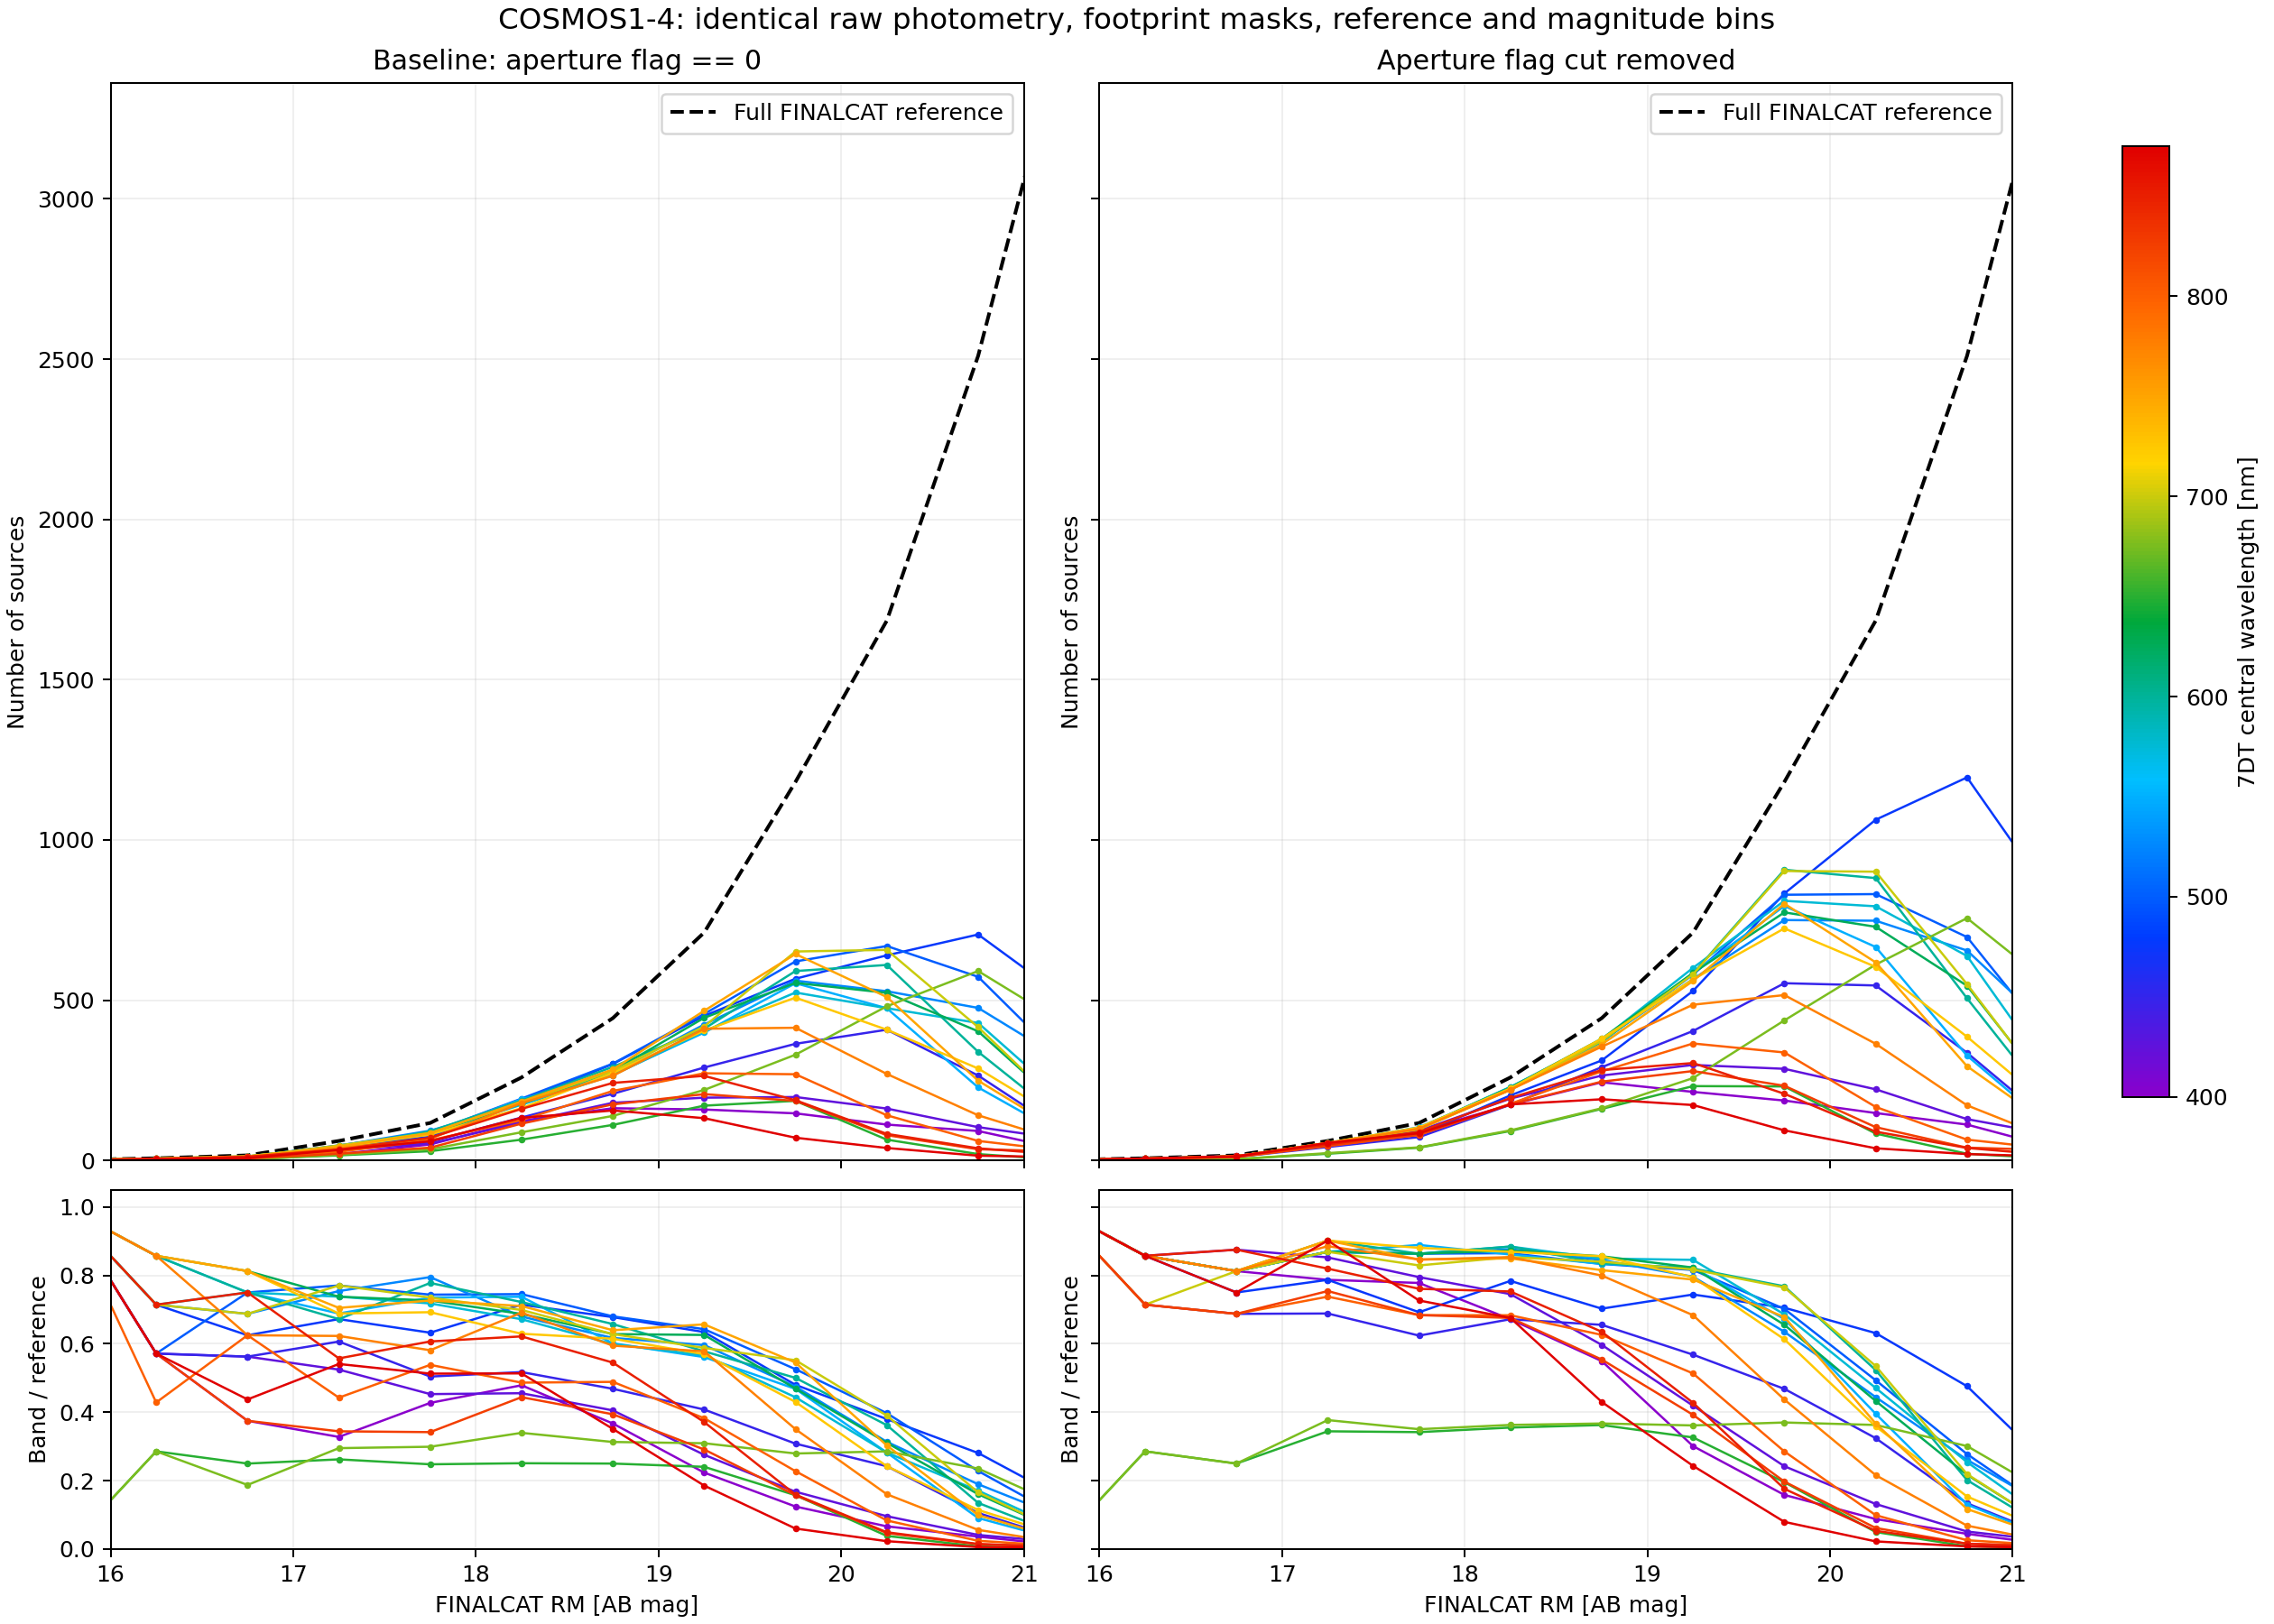

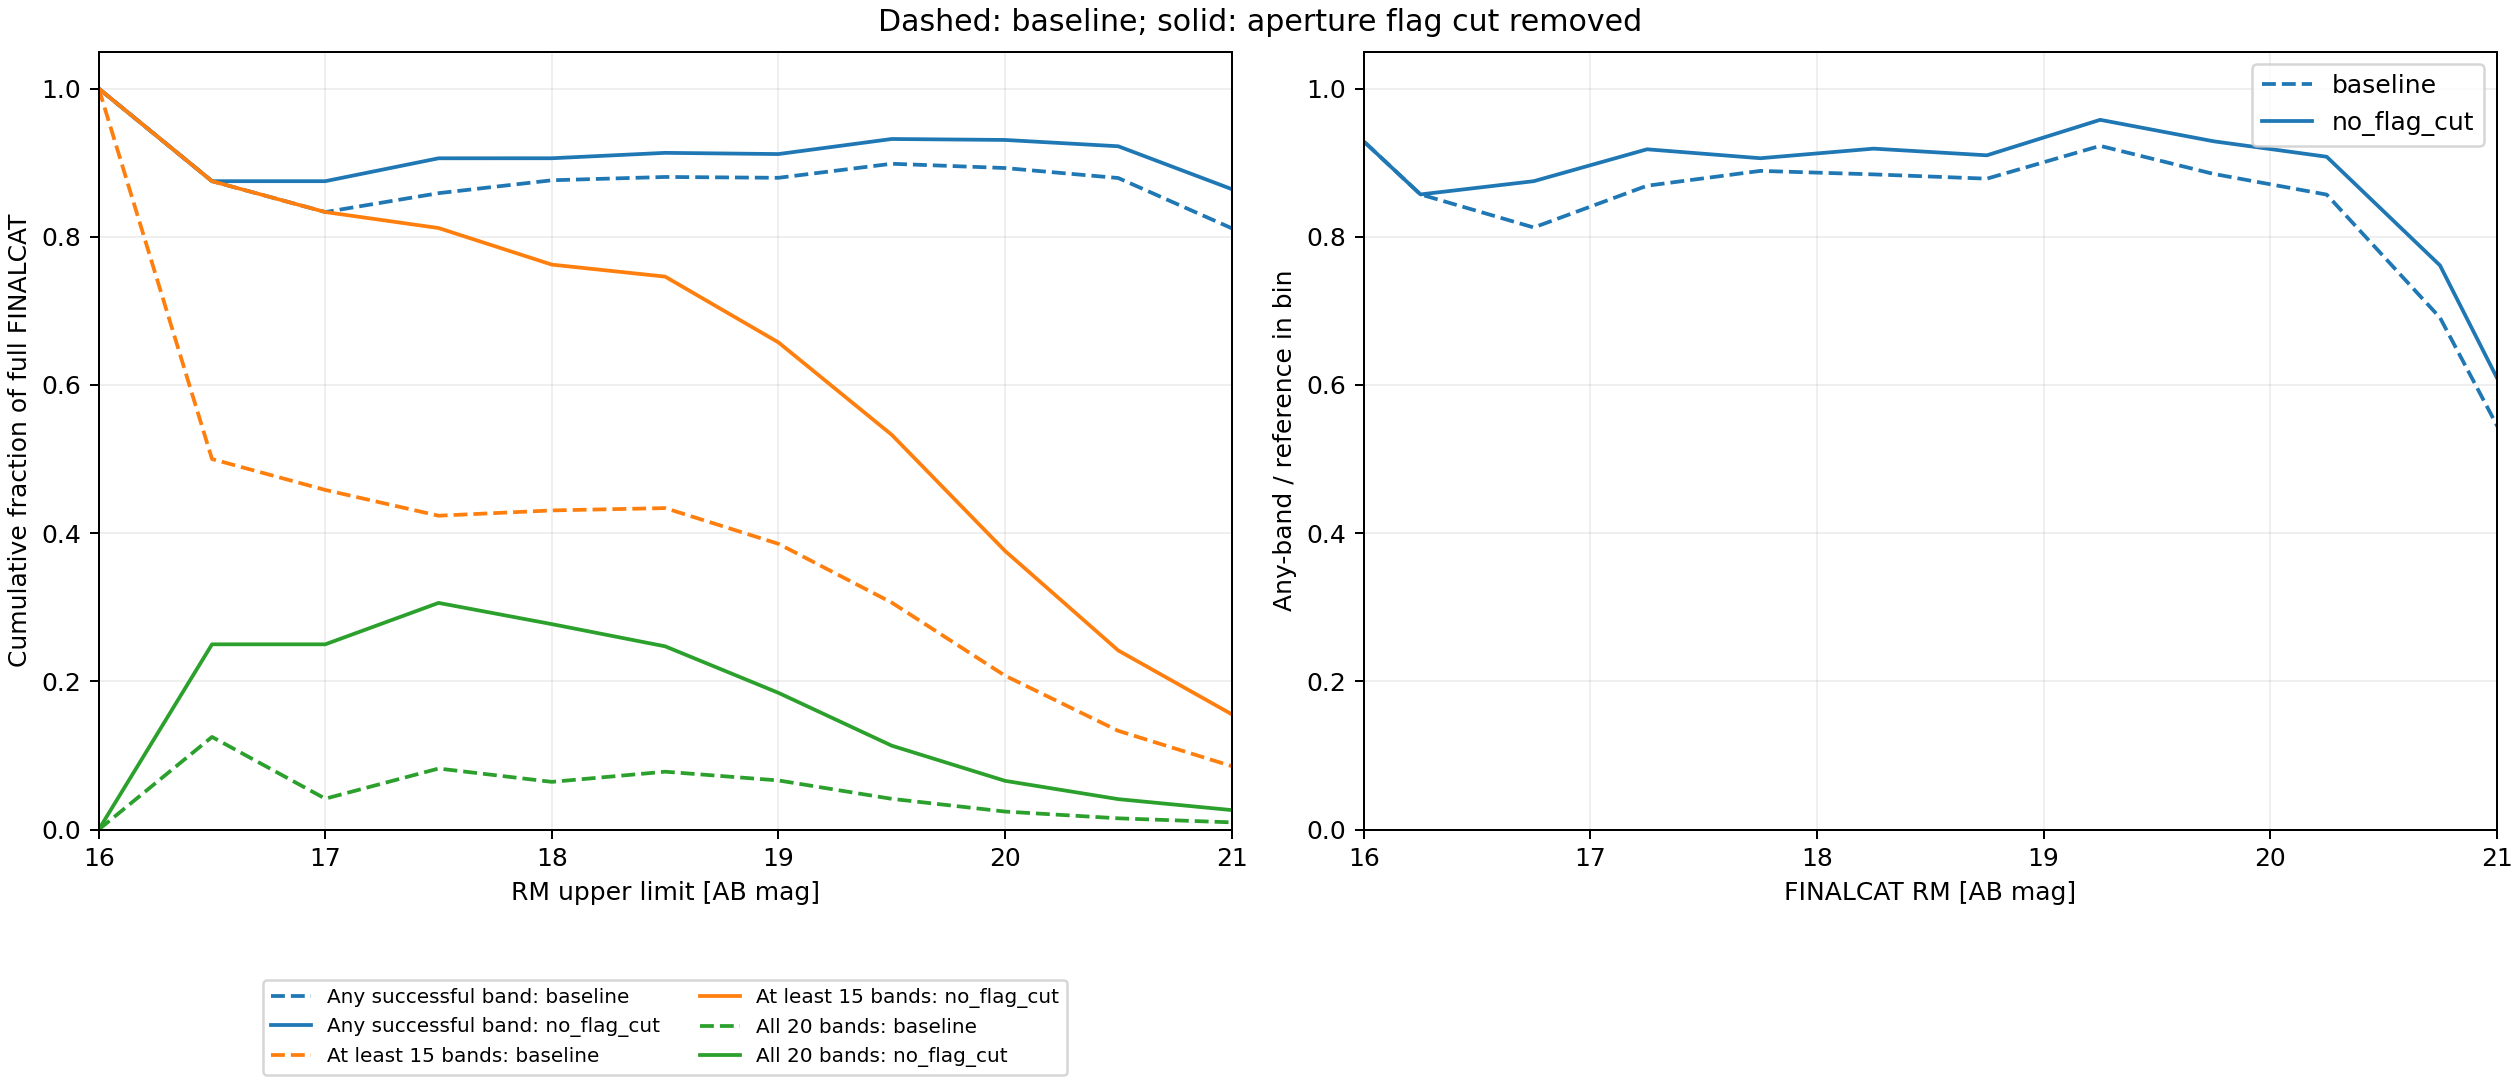

variant,population,RM_max,N_reference,N_sources,fraction
str11,str5,int64,int64,int64,float64
baseline,any,21,6991,5674,0.8116149334859104
baseline,ge15,21,6991,599,0.08568159061650693
baseline,all20,21,6991,68,0.009726791589186096
no_flag_cut,any,21,6991,6043,0.8643970819625233
no_flag_cut,ge15,21,6991,1089,0.1557717064797597
no_flag_cut,all20,21,6991,184,0.02631955371191532


band,N_reference_RMle21,N_before,N_after,fraction_before,fraction_after,increase_percentage_points,gained_finalcat_rows,lost_finalcat_rows
str4,int64,int64,int64,float64,float64,float64,int64,int64
m400,6991,878,1238,0.12559004434272636,0.1770848233442998,5.149477900157345,436,76
m425,6991,1057,1559,0.15119439279073094,0.22300100128736947,7.1806608496638535,591,89
m450,6991,1779,2436,0.25447003289944214,0.3484480045773137,9.397797167787155,799,142
m475,6991,2980,4283,0.4262623372908025,0.612644829065942,18.638249177513945,1489,186
m500,6991,2966,3705,0.4242597625518524,0.5299671005578601,10.570733800600772,924,185
m525,6991,2595,3495,0.3711915319696753,0.4999284794736089,12.873694750393362,1071,171
m550,6991,2260,3142,0.3232727792876556,0.44943498784151054,12.616220855385496,1001,119
m575,6991,2418,3622,0.345873265627235,0.5180946931769418,17.222142754970676,1325,121
m600,6991,2581,3653,0.3691889572307252,0.5225289658131884,15.334000858246316,1186,114


In [29]:
# Replot saved catalogs only; this cell never invokes SourceXtractor++.
from pathlib import Path
import importlib.util
from IPython.display import display, Image

ABLATION_ROOT = Path.cwd().resolve()
if ABLATION_ROOT.name == 'Notebooks':
    ABLATION_ROOT = ABLATION_ROOT.parent
ABLATION_HELPER = ABLATION_ROOT / 'Report/2026-10-20/plot_aperture_flag_comparison.py'
ABLATION_SPEC = importlib.util.spec_from_file_location('aperture_flag_comparison', ABLATION_HELPER)
ABLATION_MODULE = importlib.util.module_from_spec(ABLATION_SPEC)
ABLATION_SPEC.loader.exec_module(ABLATION_MODULE)
ABLATION_FRACTION_PNG, ABLATION_OVERALL_PNG, ABLATION_POPULATIONS, ABLATION_BANDS = ABLATION_MODULE.main()
display(Image(filename=str(ABLATION_FRACTION_PNG)))
display(Image(filename=str(ABLATION_OVERALL_PNG)))
display(ABLATION_POPULATIONS)
display(ABLATION_BANDS)
